<a href="https://colab.research.google.com/github/Dunk0725/GIS-26/blob/NJ-Youth-Football-GIS/Copy_of_PS4_NJ_Youth_Football_GIS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PS4 — New Jersey Youth Football: State Resources, Public Policy, and Statewide Coordination**

## Project Purpose

New Jersey has many independent community youth football organizations. They operate locally and participate in different leagues, but there is no single statewide structure connecting all of them.

This project uses GIS to test whether a proposed organization called the **New Jersey Youth and Amateur Sports Association (NJYASA)** could create a practical statewide structure.

The proposed model would organize participating programs through:

1. **Local organizations**
2. **21 County Conferences**
3. **Three regions: North, Central, and South**

Each County Conference would elect one president. The seven County Presidents within each region would form that region's representative council.

Professional NJYASA staff would work from the statewide and regional levels to coordinate partnerships, resources, and services.

### Main Research Question

**How can GIS identify geographic relationships among New Jersey youth football organizations, state government resources, and youth-sports legislative activity, and what do these relationships suggest about the potential role of NJYASA as a statewide coordinating organization?**

### What This Project Examines

- Where New Jersey's 266 identified youth football organizations are geographically located.
- How youth football organizations currently operate across different leagues.
- How a proposed structure of 21 County Conferences and three regions (North, Central, and South) could support statewide coordination.
- How relevant programs, funding, and resources associated with five New Jersey state departments (State, Children and Families, Community Affairs, Education, and Health) are geographically distributed, where suitable data are available.
- How youth-sports and interscholastic-athletics legislative sponsorship is distributed across New Jersey's 40 legislative districts.
- What these geographic relationships suggest about potential opportunities and limitations for NJYASA as a statewide coordinating organization.

### Important Limitation

This project examines geographic relationships among 266 identified youth football organizations, public resources, and legislative activity in New Jersey. However, comparable statewide data on athlete enrollment, team size, organizational membership, operating budgets, funding, and service areas are not consistently available. Therefore, organization counts alone cannot establish participation levels, community needs, or equitable access to youth sports.

Where suitable data are available, PS4 will incorporate population, per-capita measures, funding, and service availability to provide additional geographic context.

The proposed NJYASA county and regional structure remains a planning model. Identifying relevant state resources, institutions, or legislative activity does not establish existing partnerships, funding commitments, or organizational participation.

These findings may identify potential opportunities for coordination, but they do not independently demonstrate NJYASA's administrative feasibility or effectiveness.

In [40]:
# -------------------------------------------------------
# PS3 - SETUP
# -------------------------------------------------------

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

print("GIS setup complete.")

GIS setup complete.


In [41]:
# -------------------------------------------------------
# PS3 - DATA SOURCES
# -------------------------------------------------------

# Official New Jersey county boundaries
COUNTY_URL = (
    "https://services2.arcgis.com/XVOqAjTOJ5P6ngMu/"
    "arcgis/rest/services/NJ_Counties_3424/"
    "FeatureServer/0/query?"
    "where=1%3D1&outFields=*&returnGeometry=true&"
    "outSR=4326&f=geojson"
)

# Youth football research dataset
FOOTBALL_URL = (
    "https://raw.githubusercontent.com/"
    "Dunk0725/GIS-26/"
    "NJ-Youth-Football-GIS/"
    "PS3_NJ_Youth_Football_Analysis_Ready_2026.csv"
)

print("Data sources ready.")

Data sources ready.


In [42]:
# -------------------------------------------------------
# PS3 - LOAD DATA
# -------------------------------------------------------

# Load NJ counties
counties = gpd.read_file(COUNTY_URL)

counties = counties[
    ["COUNTY", "geometry"]
].copy()

counties = counties.to_crs("EPSG:4326")

counties["COUNTY"] = (
    counties["COUNTY"]
    .astype(str)
    .str.strip()
    .str.title()
)


# Load youth football organizations
football = pd.read_csv(
    FOOTBALL_URL,
    dtype={"Program_ID": "string"}
)

football["Program_ID"] = (
    football["Program_ID"]
    .str.strip()
)


print("NJ counties:", len(counties))
print("Youth football organizations:", len(football))

NJ counties: 21
Youth football organizations: 266


In [43]:
# -------------------------------------------------------
# PS3 - DATA CHECK
# -------------------------------------------------------

duplicate_ids = football["Program_ID"].duplicated().sum()

missing_coordinates = (
    football[
        ["Latitude", "Longitude"]
    ]
    .isna()
    .any(axis=1)
    .sum()
)

missing_league = (
    football["League_Acronym"]
    .isna()
    .sum()
)


print("Organizations:", len(football))
print("Duplicate IDs:", duplicate_ids)
print("Missing coordinates:", missing_coordinates)
print("League affiliation still pending:", missing_league)

Organizations: 266
Duplicate IDs: 0
Missing coordinates: 0
League affiliation still pending: 1


## Data Check

The working dataset contains **266 documented youth football organizations** with geographic coordinates.

One organization currently has a pending exact league affiliation. It remains included in the geographic analysis because its organization and field location are documented, but it will be treated separately when analyzing league membership.

## Where Are the Organizations?

The first step is to determine where the 266 documented organizations are located across New Jersey.

Each organization is converted into a GIS point using its home-field coordinates. Those points are then compared with official New Jersey county boundaries.

This provides an independent check that the researched county information matches the geographic location of each field.

In [44]:
# -------------------------------------------------------
# PS3 - CREATE ORGANIZATION POINTS
# -------------------------------------------------------

football["Latitude"] = pd.to_numeric(
    football["Latitude"],
    errors="coerce"
)

football["Longitude"] = pd.to_numeric(
    football["Longitude"],
    errors="coerce"
)

football_points = gpd.GeoDataFrame(
    football.copy(),
    geometry=gpd.points_from_xy(
        football["Longitude"],
        football["Latitude"]
    ),
    crs="EPSG:4326"
)

print("Organization points created:", len(football_points))

Organization points created: 266


In [45]:
# -------------------------------------------------------
# PS3 - CHECK ORGANIZATION COUNTIES
# -------------------------------------------------------

county_lookup = (
    counties[
        ["COUNTY", "geometry"]
    ]
    .rename(
        columns={
            "COUNTY": "GIS_County"
        }
    )
    .copy()
)

football_by_county = gpd.sjoin(
    football_points,
    county_lookup,
    how="left",
    predicate="within"
)

football_by_county = (
    football_by_county
    .drop(
        columns=["index_right"],
        errors="ignore"
    )
)


# Compare researched county with GIS county
football_by_county["County_Match"] = (
    football_by_county["Primary_County"]
    .astype(str)
    .str.strip()
    .str.lower()
    ==
    football_by_county["GIS_County"]
    .astype(str)
    .str.strip()
    .str.lower()
)


print("Organizations:", len(football_by_county))

print(
    "Missing GIS county:",
    football_by_county["GIS_County"].isna().sum()
)

print(
    "County matches:",
    football_by_county["County_Match"].sum()
)

print(
    "County differences:",
    (~football_by_county["County_Match"]).sum()
)

Organizations: 266
Missing GIS county: 0
County matches: 266
County differences: 0


In [46]:
# -------------------------------------------------------
# PS3 - ORGANIZATIONS BY COUNTY
# -------------------------------------------------------

county_summary = (
    football_by_county
    .groupby("GIS_County")
    .size()
    .reset_index(
        name="Organizations"
    )
    .sort_values(
        "Organizations",
        ascending=False
    )
    .reset_index(drop=True)
)

county_summary["Statewide_Share"] = (
    county_summary["Organizations"]
    / len(football_by_county)
    * 100
).round(1)

display(county_summary)

,GIS_County,Organizations,Statewide_Share
0,Bergen,36,13.5
1,Monmouth,26,9.8
2,Morris,21,7.9
3,Burlington,19,7.1
4,Camden,18,6.8
5,Essex,18,6.8
6,Middlesex,16,6.0
7,Ocean,14,5.3
8,Union,14,5.3
9,Gloucester,13,4.9


### Why This Matters

The organizations are not evenly distributed across New Jersey.

Some counties contain many documented youth football organizations, while others contain relatively few. This difference becomes important later when considering County Conferences because every county would receive representation even though the number of organizations represented by each conference may differ substantially.

## Map 1 — Where Are New Jersey's Youth Football Organizations?

The first map shows the home-field location of each documented youth football organization in the dataset.

The purpose is to establish the statewide network before examining leagues or proposing a new administrative structure.

Each point represents one documented organization.

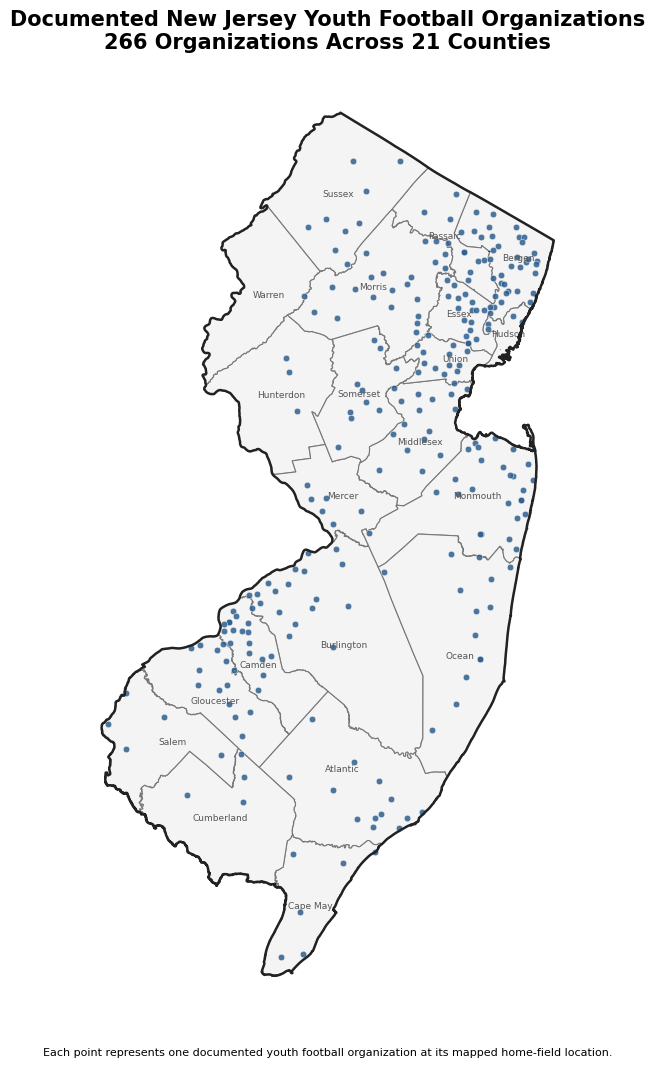

In [47]:
# -------------------------------------------------------
# PS3 - MAP 1
# DOCUMENTED YOUTH FOOTBALL ORGANIZATIONS
# -------------------------------------------------------

# Use NJ State Plane for a cleaner map shape
map_counties = counties.to_crs("EPSG:3424")
map_points = football_by_county.to_crs("EPSG:3424")


# -------------------------------------------------------
# CREATE MAP
# -------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(9, 11)
)


# County background
map_counties.plot(
    ax=ax,
    color="#f4f4f4",
    edgecolor="#777777",
    linewidth=0.8
)


# Organization locations
map_points.plot(
    ax=ax,
    color="#2f5f8f",
    edgecolor="white",
    linewidth=0.35,
    markersize=22,
    alpha=0.85,
    zorder=3
)


# -------------------------------------------------------
# COUNTY LABELS
# -------------------------------------------------------

county_labels = map_counties.copy()

county_labels["label_point"] = (
    county_labels.geometry
    .representative_point()
)


for _, row in county_labels.iterrows():

    ax.text(
        row["label_point"].x,
        row["label_point"].y,
        row["COUNTY"],

        ha="center",
        va="center",

        fontsize=6.5,
        color="#555555",

        zorder=4
    )


# -------------------------------------------------------
# STRONGER STATE OUTLINE
# -------------------------------------------------------

state_outline = map_counties.dissolve()

state_outline.boundary.plot(
    ax=ax,
    color="#222222",
    linewidth=1.8,
    zorder=5
)


# -------------------------------------------------------
# TITLE
# -------------------------------------------------------

ax.set_title(
    "Documented New Jersey Youth Football Organizations\n"
    f"{len(map_points)} Organizations Across 21 Counties",
    fontsize=15,
    fontweight="bold",
    pad=15
)


# -------------------------------------------------------
# MAP NOTE
# -------------------------------------------------------

fig.text(
    0.5,
    0.035,

    (
        "Each point represents one documented youth football "
        "organization at its mapped home-field location."
    ),

    ha="center",
    fontsize=8
)


ax.set_axis_off()

plt.tight_layout(
    rect=[0, 0.055, 1, 1]
)

plt.show()

### Map 1 Interpretation

The 266 documented organizations are distributed across all 21 New Jersey counties, showing that community youth football operates as a statewide network rather than as a small number of isolated local programs.

The distribution is not even. Bergen County contains the largest documented concentration with 36 organizations, followed by Monmouth with 26 and Morris with 21. Burlington County contains 19 organizations. At the other end of the distribution, Warren County contains one documented organization.

This geographic variation becomes important when considering a statewide coordination model. A structure based on counties would provide statewide representation, but different County Conferences could be responsible for very different numbers of organizations.

The map represents organization home-field locations and does not measure athlete enrollment, team counts, participation rates, or the full service area of each organization.

## How Are Organizations Currently Organized?

The organizations in the dataset participate in many different youth football leagues.

Rather than requiring the reader to understand every league, this section asks a simpler question:

**How many different leagues operate within each county?**

A county with several leagues represents a more fragmented local structure than a county where organizations primarily participate in one league.

One organization's exact league affiliation is still pending verification, so it is included in the geographic analysis but not counted as a verified league affiliation.

In [48]:
# -------------------------------------------------------
# PS3 - LEAGUE STRUCTURE
# -------------------------------------------------------

verified_leagues = football_by_county[
    football_by_county["League_Acronym"].notna()
].copy()

verified_leagues = verified_leagues[
    verified_leagues["League_Acronym"].str.strip() != ""
]


league_by_county = (
    verified_leagues
    .groupby("GIS_County")
    .agg(
        Verified_Organizations=("Program_ID", "count"),
        Verified_Leagues=("League_Acronym", "nunique")
    )
    .reset_index()
)


league_by_county = (
    county_summary[
        ["GIS_County", "Organizations"]
    ]
    .merge(
        league_by_county,
        on="GIS_County",
        how="left"
    )
    .fillna(0)
    .sort_values(
        ["Verified_Leagues", "Organizations"],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)


print(
    "Recorded leagues statewide:",
    verified_leagues["League_Acronym"].nunique()
)

print(
    "Organizations with pending exact league:",
    len(football_by_county) - len(verified_leagues)
)

display(league_by_county)

Recorded leagues statewide: 19
Organizations with pending exact league: 1


,GIS_County,Organizations,Verified_Organizations,Verified_Leagues
0,Bergen,36,36,5
1,Essex,18,18,5
2,Morris,21,21,4
3,Passaic,10,10,4
4,Mercer,6,6,4
5,Burlington,19,18,3
6,Camden,18,18,3
7,Middlesex,16,16,3
8,Ocean,14,14,3
9,Union,14,14,3


## Map 2 — Existing League Fragmentation

This map shows the number of different verified youth football leagues represented within each county.

Darker counties contain organizations from a greater number of leagues.

The map does not suggest that having several leagues is inherently good or bad. It is used to show how organizationally complex the existing system is before considering a statewide coordination model.

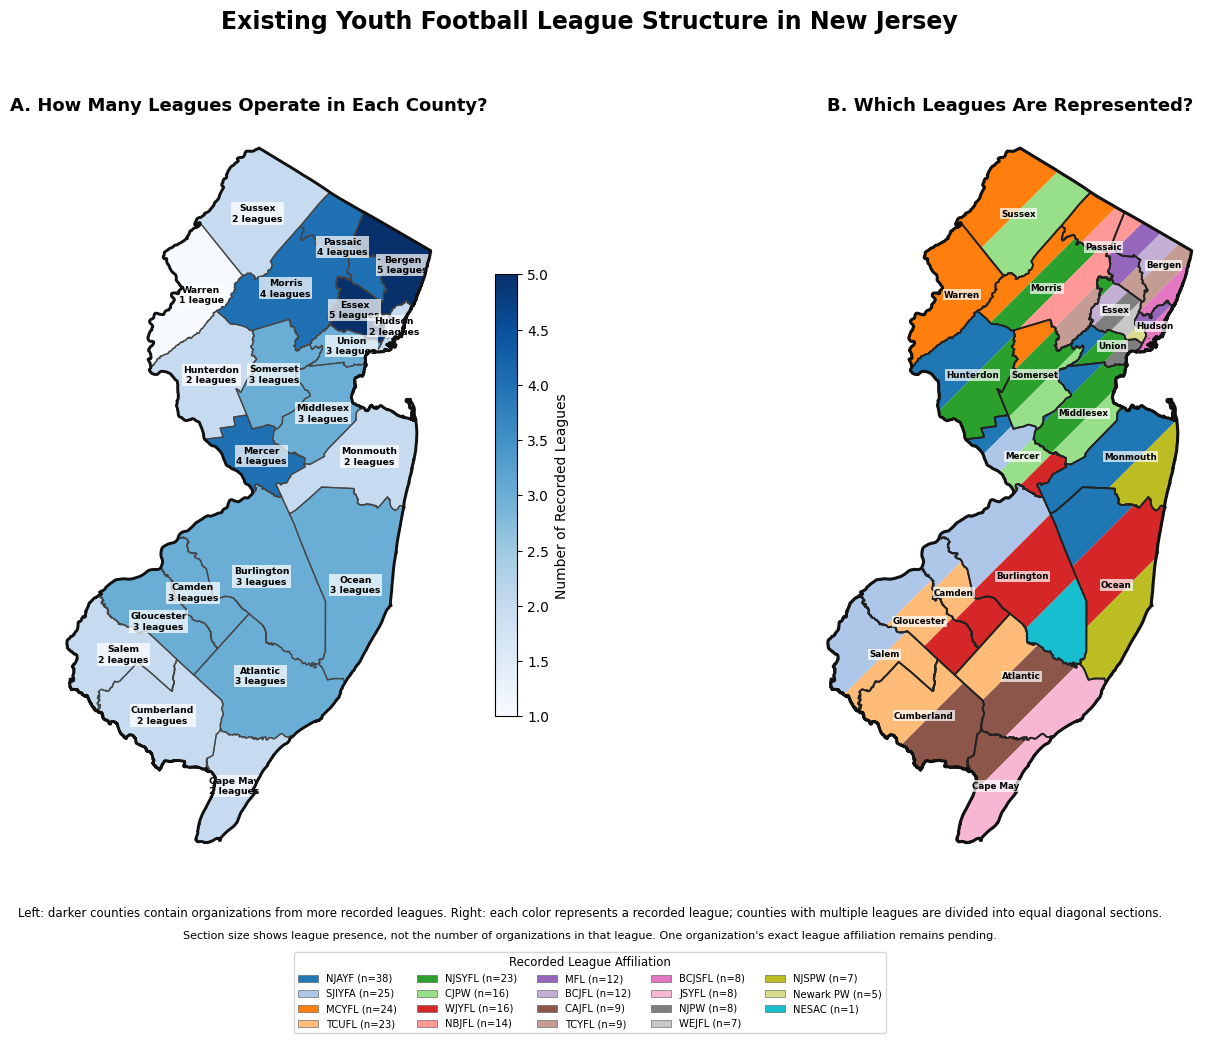

In [49]:
# -------------------------------------------------------
# PS3 - MAP 2
# EXISTING LEAGUE STRUCTURE
# -------------------------------------------------------

from shapely.affinity import rotate
from shapely.geometry import box
from matplotlib.patches import Patch


# -------------------------------------------------------
# 1. PREPARE COUNTY LEAGUE COUNTS
# -------------------------------------------------------

league_map = (
    map_counties
    .rename(
        columns={"COUNTY": "GIS_County"}
    )
    .merge(
        league_by_county[
            ["GIS_County", "Verified_Leagues"]
        ],
        on="GIS_County",
        how="left"
    )
)

league_map["Verified_Leagues"] = (
    league_map["Verified_Leagues"]
    .fillna(0)
    .astype(int)
)


# -------------------------------------------------------
# 2. CREATE A CONSISTENT COLOR FOR EACH LEAGUE
#
# tab20 uses related dark/light color pairs.
# -------------------------------------------------------

league_counts = (
    verified_leagues["League_Acronym"]
    .value_counts()
)

league_order = (
    league_counts
    .index
    .tolist()
)

tab20 = plt.get_cmap("tab20")

league_colors = {
    league: tab20(i)
    for i, league in enumerate(league_order)
}


# -------------------------------------------------------
# 3. LIST THE LEAGUES PRESENT IN EACH COUNTY
# -------------------------------------------------------

order_lookup = {
    league: i
    for i, league in enumerate(league_order)
}

county_leagues = (
    verified_leagues
    .groupby("GIS_County")["League_Acronym"]
    .apply(
        lambda x: sorted(
            x.dropna().unique(),
            key=lambda league: order_lookup[league]
        )
    )
    .to_dict()
)


# -------------------------------------------------------
# 4. FUNCTION TO DIVIDE A COUNTY INTO
#    EQUAL DIAGONAL "/" SECTIONS
# -------------------------------------------------------

def diagonal_sections(geometry, number_of_sections):

    if number_of_sections <= 1:
        return [geometry]

    center = geometry.centroid
    origin = (center.x, center.y)

    # Rotate so vertical cuts become "/" cuts
    rotated = rotate(
        geometry,
        45,
        origin=origin
    )

    minx, miny, maxx, maxy = rotated.bounds

    width = (
        maxx - minx
    ) / number_of_sections

    padding = max(
        maxx - minx,
        maxy - miny
    ) * 0.05

    pieces = []

    for i in range(number_of_sections):

        x0 = minx + i * width
        x1 = minx + (i + 1) * width

        cutting_box = box(
            x0,
            miny - padding,
            x1,
            maxy + padding
        )

        piece = rotated.intersection(
            cutting_box
        )

        piece = rotate(
            piece,
            -45,
            origin=origin
        )

        pieces.append(piece)

    return pieces


# -------------------------------------------------------
# 5. CREATE SIDE-BY-SIDE FIGURE
# -------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(18, 11)
)

ax1 = axes[0]
ax2 = axes[1]


# =======================================================
# LEFT MAP
# NUMBER OF LEAGUES PER COUNTY
# =======================================================

league_map.plot(
    ax=ax1,
    column="Verified_Leagues",
    cmap="Blues",
    edgecolor="#444444",
    linewidth=1.0,
    legend=True,
    legend_kwds={
        "label": "Number of Recorded Leagues",
        "shrink": 0.60
    }
)


league_map["label_point"] = (
    league_map.geometry
    .representative_point()
)


for _, row in league_map.iterrows():

    count = int(
        row["Verified_Leagues"]
    )

    league_word = (
        "league"
        if count == 1
        else "leagues"
    )

    ax1.text(
        row["label_point"].x,
        row["label_point"].y,

        f'{row["GIS_County"]}\n'
        f'{count} {league_word}',

        ha="center",
        va="center",

        fontsize=6.7,
        fontweight="bold",

        bbox=dict(
            facecolor="white",
            alpha=0.72,
            edgecolor="none",
            pad=1
        ),

        zorder=5
    )


# Strong state outline
league_map.dissolve().boundary.plot(
    ax=ax1,
    color="#111111",
    linewidth=2.1,
    zorder=6
)


ax1.set_title(
    "A. How Many Leagues Operate in Each County?",
    fontsize=13,
    fontweight="bold",
    pad=12
)

ax1.set_axis_off()


# =======================================================
# RIGHT MAP
# WHICH LEAGUES ARE REPRESENTED
# =======================================================

# Light background first
map_counties.plot(
    ax=ax2,
    color="#f4f4f4",
    edgecolor="none"
)


for _, county in map_counties.iterrows():

    county_name = county["COUNTY"]

    leagues = county_leagues.get(
        county_name,
        []
    )

    if len(leagues) == 0:
        continue

    pieces = diagonal_sections(
        county.geometry,
        len(leagues)
    )

    for piece, league in zip(
        pieces,
        leagues
    ):

        if piece.is_empty:
            continue

        gpd.GeoSeries(
            [piece],
            crs=map_counties.crs
        ).plot(
            ax=ax2,
            color=league_colors[league],
            edgecolor="none",
            zorder=2
        )


# -------------------------------------------------------
# COUNTY BOUNDARIES ON TOP
# -------------------------------------------------------

map_counties.boundary.plot(
    ax=ax2,
    color="#222222",
    linewidth=1.25,
    zorder=5
)


map_counties.dissolve().boundary.plot(
    ax=ax2,
    color="#111111",
    linewidth=2.2,
    zorder=6
)


# -------------------------------------------------------
# COUNTY LABELS
# -------------------------------------------------------

right_labels = map_counties.copy()

right_labels["label_point"] = (
    right_labels.geometry
    .representative_point()
)


for _, row in right_labels.iterrows():

    ax2.text(
        row["label_point"].x,
        row["label_point"].y,
        row["COUNTY"],

        ha="center",
        va="center",

        fontsize=6.3,
        fontweight="bold",

        bbox=dict(
            facecolor="white",
            alpha=0.70,
            edgecolor="none",
            pad=0.8
        ),

        zorder=7
    )


ax2.set_title(
    "B. Which Leagues Are Represented?",
    fontsize=13,
    fontweight="bold",
    pad=12
)

ax2.set_axis_off()


# -------------------------------------------------------
# 6. MAKE BOTH MAPS USE THE SAME EXTENT
# -------------------------------------------------------

minx, miny, maxx, maxy = (
    map_counties.total_bounds
)

x_padding = (
    maxx - minx
) * 0.05

y_padding = (
    maxy - miny
) * 0.03


for ax in axes:

    ax.set_xlim(
        minx - x_padding,
        maxx + x_padding
    )

    ax.set_ylim(
        miny - y_padding,
        maxy + y_padding
    )


# -------------------------------------------------------
# 7. LEAGUE LEGEND
# -------------------------------------------------------

legend_handles = [

    Patch(
        facecolor=league_colors[league],
        edgecolor="#555555",
        linewidth=0.4,
        label=(
            f"{league} "
            f"(n={league_counts[league]})"
        )
    )

    for league
    in league_order
]


fig.legend(
    handles=legend_handles,

    title="Recorded League Affiliation",

    loc="lower center",
    bbox_to_anchor=(0.5, 0.035),

    ncol=5,
    fontsize=7.2,
    title_fontsize=8.5,

    frameon=True
)


# -------------------------------------------------------
# 8. MAIN TITLE AND EXPLANATION
# -------------------------------------------------------

fig.suptitle(
    "Existing Youth Football League Structure in New Jersey",
    fontsize=17,
    fontweight="bold",
    y=0.97
)


fig.text(
    0.5,
    0.145,

    (
        "Left: darker counties contain organizations from more recorded leagues. "
        "Right: each color represents a recorded league; counties with multiple "
        "leagues are divided into equal diagonal sections."
    ),

    ha="center",
    fontsize=8.5
)


fig.text(
    0.5,
    0.125,

    (
        "Section size shows league presence, not the number of organizations in that league. "
        "One organization's exact league affiliation remains pending."
    ),

    ha="center",
    fontsize=8
)


plt.tight_layout(
    rect=[
        0,
        0.18,
        1,
        0.94
    ]
)

plt.show()

### Map 2 Interpretation

The 266 documented organizations participate in **19 recorded youth football leagues**, showing that coordination among independent community organizations already exists throughout New Jersey.

Existing leagues demonstrate that local organizations can work together within a larger structure to establish shared rules, schedules, expectations, communication, and other administrative functions. However, these coordinated systems are geographically divided. Different counties may contain several leagues, while individual leagues may extend across multiple county boundaries.

The two maps show this structure in different ways. The left map shows the number of recorded leagues represented within each county. Bergen and Essex have the greatest league diversity, with five recorded leagues each. The right map shows how those league networks overlap geographically across the state.

For the proposed NJYASA model, the importance of this finding is not that existing coordination is absent. Rather, it shows that **coordination already works at the league level**. NJYASA would examine whether similar principles could be extended statewide so that organizations operate within a more consistent administrative framework regardless of where they are located in New Jersey.

Under that concept, individual organizations could retain their local identity while families, volunteers, coaches, and organizational leaders would encounter more familiar standards, resources, and expectations when participating in youth sports elsewhere in the state.

One organization's exact league affiliation remains pending verification and is excluded from the verified league counts.

## Proposed NJYASA Regional Structure

The existing leagues show that independent organizations can already work together within a shared structure.

The next question is whether that same idea could be expanded across New Jersey.

The proposed NJYASA model divides the state into three regions:

- **North — 7 counties**
- **Central — 7 counties**
- **South — 7 counties**

These regions would not be separate football leagues. They would provide a consistent statewide framework for representation, administration, resources, and services.

The goal is to create a structure that remains familiar across the state while still allowing local organizations and communities to operate locally.

In [50]:
# -------------------------------------------------------
# PS3 - PROPOSED NJYASA REGIONS
# -------------------------------------------------------

region_counties = {

    "North": [
        "Warren",
        "Bergen",
        "Essex",
        "Hudson",
        "Morris",
        "Passaic",
        "Sussex"
    ],

    "Central": [
        "Ocean",
        "Hunterdon",
        "Mercer",
        "Middlesex",
        "Monmouth",
        "Somerset",
        "Union"
    ],

    "South": [
        "Atlantic",
        "Burlington",
        "Camden",
        "Cape May",
        "Cumberland",
        "Gloucester",
        "Salem"
    ]
}


# Create county-to-region lookup
county_to_region = {
    county: region
    for region, county_list in region_counties.items()
    for county in county_list
}


# Assign every organization to a region
football_by_county["NJYASA_Region"] = (
    football_by_county["GIS_County"]
    .map(county_to_region)
)


# Check that every organization received a region
print(
    "Organizations without a region:",
    football_by_county["NJYASA_Region"].isna().sum()
)


# Regional summary
regional_summary = (
    football_by_county
    .groupby("NJYASA_Region")
    .agg(
        Organizations=("Program_ID", "count"),
        Counties=("GIS_County", "nunique")
    )
    .reindex(
        ["North", "Central", "South"]
    )
)


regional_summary["Statewide_Share"] = (
    regional_summary["Organizations"]
    / len(football_by_county)
    * 100
).round(1)


display(regional_summary)

Organizations without a region: 0


,Organizations,Counties,Statewide_Share
NJYASA_Region,,,
North,99,7,37.2
Central,89,7,33.5
South,78,7,29.3


## Map 3 — Proposed North, Central, and South Regions

This map tests a simple statewide structure made up of three seven-county regions.

Each point remains one documented youth football organization.

The map is intended to show whether the proposed regions create a reasonable geographic distribution of organizations across the state.

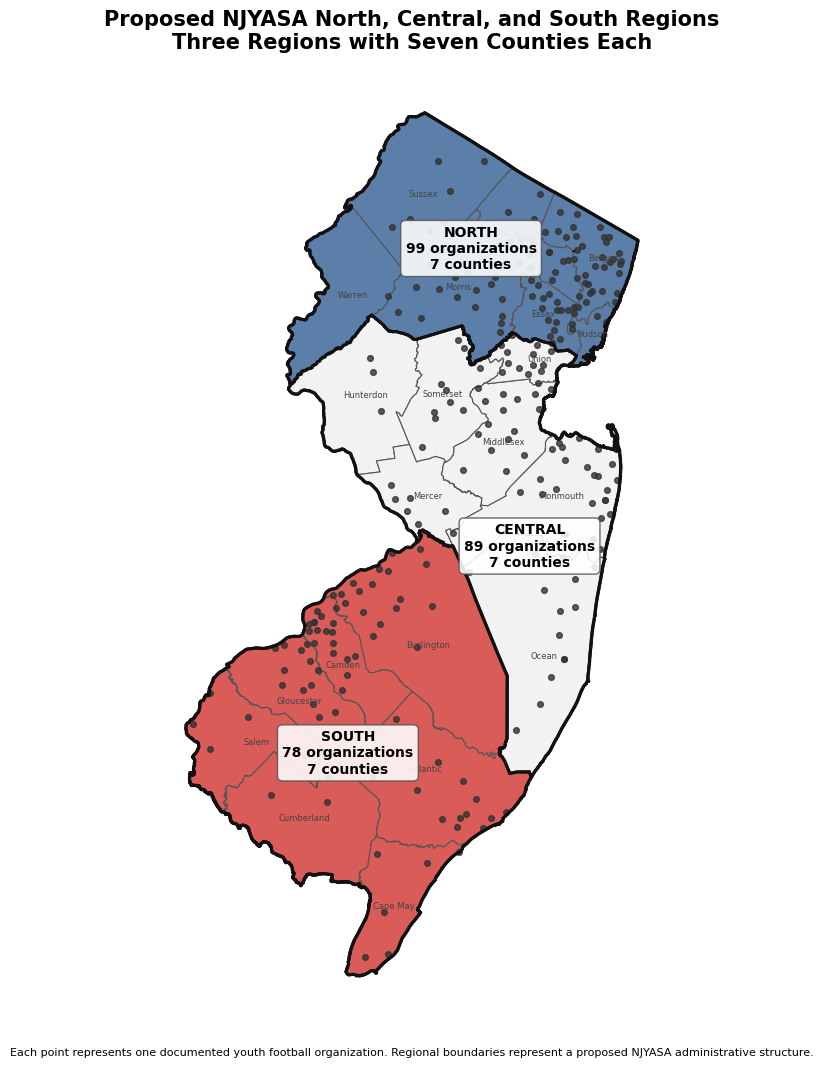

In [51]:
# -------------------------------------------------------
# PS3 - MAP 3
# PROPOSED NORTH, CENTRAL, AND SOUTH REGIONS
# -------------------------------------------------------

# Add region to county map
region_map = map_counties.copy()

region_map["NJYASA_Region"] = (
    region_map["COUNTY"]
    .map(county_to_region)
)


# Region colors
region_colors = {
    "North": "#5b7fa8",
    "Central": "#f2f2f2",
    "South": "#d95c59"
}


# -------------------------------------------------------
# CREATE MAP
# -------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(9, 11)
)


for region in [
    "North",
    "Central",
    "South"
]:

    region_map[
        region_map["NJYASA_Region"] == region
    ].plot(
        ax=ax,
        color=region_colors[region],
        edgecolor="#555555",
        linewidth=0.8
    )


# Organization points
map_points.plot(
    ax=ax,
    color="#333333",
    markersize=17,
    alpha=0.80,
    zorder=3
)


# -------------------------------------------------------
# STRONG REGION BOUNDARIES
# -------------------------------------------------------

regional_boundaries = (
    region_map
    .dissolve(
        by="NJYASA_Region"
    )
)

regional_boundaries.boundary.plot(
    ax=ax,
    color="#111111",
    linewidth=2.2,
    zorder=4
)


# State outline
region_map.dissolve().boundary.plot(
    ax=ax,
    color="#111111",
    linewidth=2.3,
    zorder=5
)


# -------------------------------------------------------
# COUNTY LABELS
# -------------------------------------------------------

region_labels = region_map.copy()

region_labels["label_point"] = (
    region_labels.geometry
    .representative_point()
)


for _, row in region_labels.iterrows():

    ax.text(
        row["label_point"].x,
        row["label_point"].y,
        row["COUNTY"],

        ha="center",
        va="center",

        fontsize=6,
        color="#444444",

        zorder=6
    )


# -------------------------------------------------------
# REGION LABELS
# -------------------------------------------------------

for region in [
    "North",
    "Central",
    "South"
]:

    geometry = (
        regional_boundaries
        .loc[region]
        .geometry
    )

    label_point = (
        geometry
        .representative_point()
    )

    organization_count = int(
        regional_summary
        .loc[
            region,
            "Organizations"
        ]
    )

    ax.text(
        label_point.x,
        label_point.y,

        f"{region.upper()}\n"
        f"{organization_count} organizations\n"
        f"7 counties",

        ha="center",
        va="center",

        fontsize=10,
        fontweight="bold",

        bbox=dict(
            facecolor="white",
            alpha=0.88,
            edgecolor="#555555",
            boxstyle="round,pad=0.35"
        ),

        zorder=8
    )


# -------------------------------------------------------
# TITLE
# -------------------------------------------------------

ax.set_title(
    "Proposed NJYASA North, Central, and South Regions\n"
    "Three Regions with Seven Counties Each",
    fontsize=15,
    fontweight="bold",
    pad=15
)


fig.text(
    0.5,
    0.035,

    (
        "Each point represents one documented youth football organization. "
        "Regional boundaries represent a proposed NJYASA administrative structure."
    ),

    ha="center",
    fontsize=8
)


ax.set_axis_off()

plt.tight_layout(
    rect=[0, 0.055, 1, 1]
)

plt.show()

In [52]:
# -------------------------------------------------------
# PS3 - LEAGUES ACROSS PROPOSED REGIONS
# -------------------------------------------------------

league_region = (
    verified_leagues
    .assign(
        NJYASA_Region=lambda df:
        df["GIS_County"].map(
            county_to_region
        )
    )
    .groupby("League_Acronym")
    .agg(
        Organizations=("Program_ID", "count"),
        Regions_Represented=("NJYASA_Region", "nunique")
    )
    .reset_index()
)


region_span_summary = (
    league_region[
        "Regions_Represented"
    ]
    .value_counts()
    .reindex(
        [1, 2, 3],
        fill_value=0
    )
    .rename_axis(
        "Regions"
    )
    .reset_index(
        name="Leagues"
    )
)


display(region_span_summary)

,Regions,Leagues
0,1,13
1,2,6
2,3,0


### Map 3 Interpretation

The proposed NJYASA structure divides New Jersey into three regions containing seven counties each.

The updated dataset places **99 documented organizations in North, 89 in Central, and 78 in South**. The regions therefore contain similar, but not equal, shares of the statewide network.

The county shading also shows that organizations are not distributed evenly within each region. Bergen County contains 36 documented organizations, while Warren County contains one. Burlington County contains 19 organizations, while Cumberland County contains four.

This is important because the proposed regions are intended to create a consistent statewide administrative structure, not three identical operating areas. Different counties and regions would still have different workloads and local needs.

The existing league structure also fits reasonably well with the proposed regional geography. Of the **19 verified leagues, 13 operate entirely within one proposed region, six operate across two regions, and none span all three**.

The regions shown are proposed administrative areas and have not been adopted by the organizations represented in the dataset.

## How Would Local Organizations Be Represented?

The proposed NJYASA model uses counties as the local level of representation.

Organizations located within the same county would participate in a **County Conference**. Each participating organization would have a voice in that conference, and the organizations would elect one **County Conference President**.

The elected County President would then represent the entire county on the Regional Council.

Because each proposed region contains seven counties, each Regional Council would contain **seven elected County Conference Presidents**.

This creates a bottom-up system in which statewide and regional decisions remain connected to people working with local organizations.

In [53]:
# -------------------------------------------------------
# PS3 - COUNTY CONFERENCE STRUCTURE
# -------------------------------------------------------

county_conferences = (
    football_by_county
    .groupby("GIS_County")
    .agg(
        Organizations=("Program_ID", "count")
    )
    .reset_index()
)


# Assign each county to its proposed region
county_conferences["NJYASA_Region"] = (
    county_conferences["GIS_County"]
    .map(county_to_region)
)


# Each county receives one elected representative
county_conferences["Regional_Seats"] = 1


# Sort for easy reading
county_conferences = (
    county_conferences
    .sort_values(
        ["NJYASA_Region", "Organizations"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)


display(county_conferences)

,GIS_County,Organizations,NJYASA_Region,Regional_Seats
0,Monmouth,26,Central,1
1,Middlesex,16,Central,1
2,Ocean,14,Central,1
3,Union,14,Central,1
4,Somerset,10,Central,1
5,Mercer,6,Central,1
6,Hunterdon,3,Central,1
7,Bergen,36,North,1
8,Morris,21,North,1
9,Essex,18,North,1


In [54]:
# -------------------------------------------------------
# PS3 - REGIONAL REPRESENTATION CHECK
# -------------------------------------------------------

regional_representation = (
    county_conferences
    .groupby("NJYASA_Region")
    .agg(
        County_Conferences=("GIS_County", "count"),
        Organizations=("Organizations", "sum"),
        Regional_Representatives=("Regional_Seats", "sum")
    )
    .reindex(
        ["North", "Central", "South"]
    )
)


display(regional_representation)

,County_Conferences,Organizations,Regional_Representatives
NJYASA_Region,,,
North,7,99,7
Central,7,89,7
South,7,78,7


## Map 4 — Proposed County Conference Representation

This map shows how the 266 documented organizations would be represented under the proposed County Conference model.

Counties are shaded by the number of documented organizations they contain.

Each county would still elect **one County Conference President**, regardless of the number of organizations in that county. The seven County Presidents in each region would together form the Regional Council.

## How Would Local Organizations Be Represented?

The proposed NJYASA model uses counties as the local level of representation.

Organizations within each county would participate in a **County Conference** and select one **County Conference President**.

The number of organizations represented by each County Conference would vary. However, each county would receive one representative on its Regional Council.

Because each proposed region contains seven counties, each Regional Council would contain **seven elected County Conference Presidents**.

In [55]:
# -------------------------------------------------------
# PS3 - COUNTY CONFERENCE STRUCTURE
# -------------------------------------------------------

county_conferences = (
    football_by_county
    .groupby("GIS_County")
    .agg(
        Organizations=("Program_ID", "count")
    )
    .reset_index()
)

county_conferences["NJYASA_Region"] = (
    county_conferences["GIS_County"]
    .map(county_to_region)
)

county_conferences["Regional_Seat"] = 1


regional_representation = (
    county_conferences
    .groupby("NJYASA_Region")
    .agg(
        Counties=("GIS_County", "count"),
        Organizations=("Organizations", "sum"),
        Representatives=("Regional_Seat", "sum")
    )
    .reindex(["North", "Central", "South"])
)

display(regional_representation)

,Counties,Organizations,Representatives
NJYASA_Region,,,
North,7,99,7
Central,7,89,7
South,7,78,7


## Map 4 — County Conference Size and Regional Representation

The two maps compare two different parts of the proposed governance system.

The left map shows how many organizations each County Conference would represent.

The right map shows the representation structure: each county would elect one County Conference President, giving every county one seat on its Regional Council.

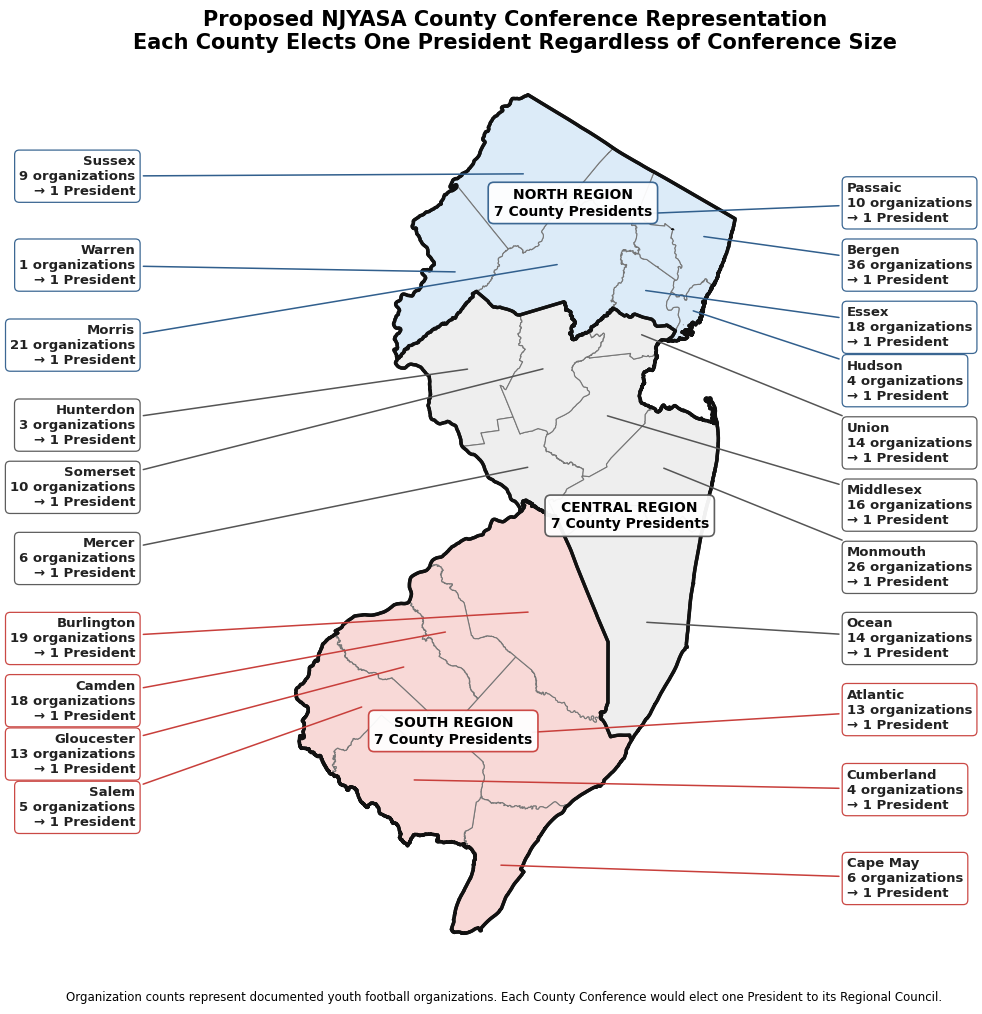

In [56]:
# -------------------------------------------------------
# PS3 - MAP 4
# COUNTY CONFERENCE REPRESENTATION
# -------------------------------------------------------

# Prepare county conference map
conference_map = (
    map_counties
    .rename(columns={"COUNTY": "GIS_County"})
    .merge(
        county_conferences,
        on="GIS_County",
        how="left"
    )
)


# -------------------------------------------------------
# REGION COLORS
# -------------------------------------------------------

region_fill = {
    "North": "#dcebf8",
    "Central": "#eeeeee",
    "South": "#f8d9d7"
}

region_line = {
    "North": "#315f8d",
    "Central": "#555555",
    "South": "#c83f3b"
}


# -------------------------------------------------------
# CREATE MAP
# -------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(12, 11)
)


# Draw counties by region
for region in ["North", "Central", "South"]:

    subset = conference_map[
        conference_map["NJYASA_Region"] == region
    ]

    subset.plot(
        ax=ax,
        color=region_fill[region],
        edgecolor="#777777",
        linewidth=0.8
    )


# -------------------------------------------------------
# STRONG REGIONAL BOUNDARIES
# -------------------------------------------------------

conference_regions = (
    conference_map
    .dissolve(by="NJYASA_Region")
)

conference_regions.boundary.plot(
    ax=ax,
    color="#111111",
    linewidth=2.4,
    zorder=5
)


conference_map.dissolve().boundary.plot(
    ax=ax,
    color="#111111",
    linewidth=2.5,
    zorder=6
)


# -------------------------------------------------------
# OUTSIDE LABEL LOCATIONS
# -------------------------------------------------------

label_positions = {

    # NORTH - LEFT
    "Sussex":      (0.03, 0.88),
    "Warren":      (0.03, 0.78),
    "Morris":      (0.03, 0.69),

    # NORTH - RIGHT
    "Passaic":     (0.91, 0.85),
    "Bergen":      (0.91, 0.78),
    "Essex":       (0.91, 0.71),
    "Hudson":      (0.91, 0.65),

    # CENTRAL - LEFT
    "Hunterdon":   (0.03, 0.60),
    "Somerset":    (0.03, 0.53),
    "Mercer":      (0.03, 0.45),

    # CENTRAL - RIGHT
    "Union":       (0.91, 0.58),
    "Middlesex":   (0.91, 0.51),
    "Monmouth":    (0.91, 0.44),
    "Ocean":       (0.91, 0.36),

    # SOUTH - LEFT
    "Burlington":  (0.03, 0.36),
    "Camden":      (0.03, 0.29),
    "Gloucester":  (0.03, 0.23),
    "Salem":       (0.03, 0.17),

    # SOUTH - RIGHT
    "Atlantic":    (0.91, 0.28),
    "Cumberland":  (0.91, 0.19),
    "Cape May":    (0.91, 0.09)
}


# -------------------------------------------------------
# COUNTY LABELS
# ORGANIZATIONS -> ONE PRESIDENT
# -------------------------------------------------------

for _, row in conference_map.iterrows():

    county = row["GIS_County"]
    region = row["NJYASA_Region"]

    point = (
        row.geometry
        .representative_point()
    )

    label_x, label_y = (
        label_positions[county]
    )

    count = int(
        row["Organizations"]
    )


    ax.annotate(

        f"{county}\n"
        f"{count} organizations\n"
        "→ 1 President",

        xy=(
            point.x,
            point.y
        ),

        xycoords="data",

        xytext=(
            label_x,
            label_y
        ),

        textcoords="axes fraction",

        ha=(
            "left"
            if label_x > 0.5
            else "right"
        ),

        va="center",

        fontsize=9.5,
        fontweight="bold",

        color="#222222",

        bbox=dict(
            facecolor="white",
            edgecolor=region_line[region],
            linewidth=0.9,
            alpha=0.95,
            boxstyle="round,pad=0.35"
        ),

        arrowprops=dict(
            arrowstyle="-",
            color=region_line[region],
            linewidth=1.1,
            shrinkA=2,
            shrinkB=2
        ),

        zorder=10
    )


# -------------------------------------------------------
# REGIONAL COUNCIL LABELS
# -------------------------------------------------------

regional_label_offsets = {
    "North": (0, 25000),
    "Central": (0, 0),
    "South": (0, -15000)
}


for region in ["North", "Central", "South"]:

    geometry = (
        conference_regions
        .loc[region]
        .geometry
    )

    point = (
        geometry
        .representative_point()
    )

    dx, dy = (
        regional_label_offsets[region]
    )


    ax.text(
        point.x + dx,
        point.y + dy,

        f"{region.upper()} REGION\n"
        "7 County Presidents",

        ha="center",
        va="center",

        fontsize=10,
        fontweight="bold",

        bbox=dict(
            facecolor="white",
            edgecolor=region_line[region],
            linewidth=1.2,
            alpha=0.94,
            boxstyle="round,pad=0.40"
        ),

        zorder=12
    )


# -------------------------------------------------------
# TITLE
# -------------------------------------------------------

ax.set_title(
    "Proposed NJYASA County Conference Representation\n"
    "Each County Elects One President Regardless of Conference Size",
    fontsize=15,
    fontweight="bold",
    pad=15
)


# -------------------------------------------------------
# MAP NOTE
# -------------------------------------------------------

fig.text(
    0.5,
    0.035,

    (
        "Organization counts represent documented youth football organizations. "
        "Each County Conference would elect one President to its Regional Council."
    ),

    ha="center",
    fontsize=8.5
)


# -------------------------------------------------------
# MAP EXTENT
# -------------------------------------------------------

minx, miny, maxx, maxy = (
    conference_map.total_bounds
)

x_padding = (
    maxx - minx
) * 0.42

y_padding = (
    maxy - miny
) * 0.03


ax.set_xlim(
    minx - x_padding,
    maxx + x_padding
)

ax.set_ylim(
    miny - y_padding,
    maxy + y_padding
)


ax.set_axis_off()

plt.tight_layout(
    rect=[0, 0.06, 1, 0.95]
)

plt.show()

### Map 4 Interpretation

The proposed County Conference model separates organizational workload from regional representation.

County Conferences would represent very different numbers of organizations. Bergen County would represent 36 documented organizations, while Warren County would represent one. Burlington County would represent 19 organizations.

However, each County Conference would elect one President. Because each proposed region contains seven counties, the North, Central, and South Regional Councils would each contain seven elected County Presidents.

This creates a bottom-up representative structure. Local organizations select their county representative, and the seven County Presidents collectively represent the region.

The County Presidents would provide local knowledge, priorities, and accountability. They would not be expected to carry out the full administrative workload of NJYASA. Professional staff would be responsible for statewide and regional operations, partnerships, programs, and service coordination. Equal county representation would not imply equal resource allocation or a fixed number of organizations. County Conferences could grow as additional eligible community organizations are formed, while programs and resources could be distributed according to participation, need, and other relevant measures.

# Interim Findings — Maps 1–4: Youth Football and Statewide Coordination

This project examined whether a county-based and regional structure could provide a practical way to coordinate New Jersey youth football organizations statewide while maintaining local representation.

The analysis identified **266 documented youth football organizations across all 21 New Jersey counties**. These organizations already participate in multiple leagues that coordinate programs across municipal and county boundaries. This demonstrates that coordinated organization is already part of youth football in New Jersey, although the current structure varies depending on location and league affiliation.

A proposed NJYASA structure could organize this statewide network through **21 County Conferences and three regions: North, Central, and South**. Each County Conference would be made up of its local youth football organizations and would elect one County President. Because each proposed region contains seven counties, each Regional Council would contain seven County Presidents.

This approach creates a bottom-up system of representation. Local organizations would have a direct role in selecting their county representative, while professional NJYASA staff could handle the larger administrative, partnership, and statewide responsibilities instead of placing those responsibilities on local volunteers.

Together, Maps 1–4 demonstrate that New Jersey's identified youth football organizations operate across all 21 counties and participate in multiple existing league structures. These findings provide a geographic foundation for examining the proposed NJYASA model of 21 County Conferences and three regional councils.

However, the distribution of organizations alone does not establish whether the proposed structure would be administratively effective or whether resources are equitably distributed. PS4 builds upon these findings by examining relevant state government resources, public programs, and legislative activity to identify potential opportunities for coordination.

## Map 5 — New Jersey Department of State: Volunteer Support and Youth Football

### Research Question

How are volunteer-support resources distributed across New Jersey's 21 counties, and what geographic relationships exist between those resources and documented community youth football organizations?

### Research Purpose

Community youth football organizations rely heavily on volunteer coaches, administrators, and other community members. The New Jersey Department of State supports volunteerism through the Governor's Office of Volunteerism and its network of volunteer-support organizations.

This analysis builds upon the Department of State research completed in PS1. It will compare county-level volunteer-support directory listings with the updated inventory of 266 identified youth football organizations.

Where suitable population data are available, the analysis will also examine population-adjusted measures to provide additional geographic context.

The objective is to identify potential opportunities for coordination, not to assume that directory listings represent the number of available volunteers or that existing volunteer-support organizations have agreed to partner with NJYASA.

**Data Source:** New Jersey Department of State — Volunteer Centers of New Jersey.

https://nj.gov/state/volunteer-centers.shtml

In [57]:

# -------------------------------------------------------
# PS4 - MAP 5
# NJ DEPARTMENT OF STATE - VOLUNTEER SUPPORT
# -------------------------------------------------------

# Source: NJ Department of State
# https://www.nj.gov/state/volunteer-centers.shtml
# County listings compiled during PS1 research.

volunteer_counts = {
    "Atlantic": 2,
    "Bergen": 1,
    "Burlington": 2,
    "Camden": 1,
    "Cape May": 2,
    "Cumberland": 2,
    "Essex": 1,
    "Gloucester": 1,
    "Hudson": 2,
    "Hunterdon": 1,
    "Mercer": 1,
    "Middlesex": 1,
    "Monmouth": 1,
    "Morris": 1,
    "Ocean": 1,
    "Passaic": 1,
    "Salem": 1,
    "Somerset": 1,
    "Sussex": 1,
    "Union": 1,
    "Warren": 1
}

# Convert directory listings into a table
volunteers = pd.DataFrame(
    volunteer_counts.items(),
    columns=["COUNTY", "Volunteer_Listings"]
)

# Join volunteer listings to NJ county boundaries
map5_counties = counties.merge(
    volunteers,
    on="COUNTY",
    how="left",
    validate="one_to_one"
)

# Add youth football organization counts from Maps 1-4
map5_counties = map5_counties.merge(
    county_summary[["GIS_County", "Organizations"]],
    left_on="COUNTY",
    right_on="GIS_County",
    how="left",
    validate="one_to_one"
)

# Verify the data
assert len(map5_counties) == 21
assert map5_counties[
    ["Volunteer_Listings", "Organizations"]
].notna().all().all()
assert map5_counties["Organizations"].sum() == 266

print("Counties matched:", len(map5_counties))
print("Youth football organizations:",
      map5_counties["Organizations"].sum())
print("County volunteer directory listings:",
      map5_counties["Volunteer_Listings"].sum())

display(
    map5_counties[
        ["COUNTY", "Organizations", "Volunteer_Listings"]
    ].sort_values("Organizations", ascending=False)
)


Counties matched: 21
Youth football organizations: 266
County volunteer directory listings: 26


,COUNTY,Organizations,Volunteer_Listings
1,Bergen,36,1
12,Monmouth,26,1
13,Morris,21,1
2,Burlington,19,2
3,Camden,18,1
6,Essex,18,1
11,Middlesex,16,1
14,Ocean,14,1
19,Union,14,1
7,Gloucester,13,1


Census population data successfully loaded!
New Jersey counties: 21


,COUNTY,Youth_Population_5_17
0,Atlantic,42743
1,Bergen,151994
2,Burlington,71961
3,Camden,88614
4,Cape May,11893


MAP 5 - STATEWIDE RESULTS
-------------------------
Counties: 21
Youth football organizations: 266
Estimated head-coach roles: 1330
3 days per week: 127,680 estimated hours | $4,927,171 illustrative value
4 days per week: 170,240 estimated hours | $6,569,562 illustrative value
5 days per week: 212,800 estimated hours | $8,211,952 illustrative value


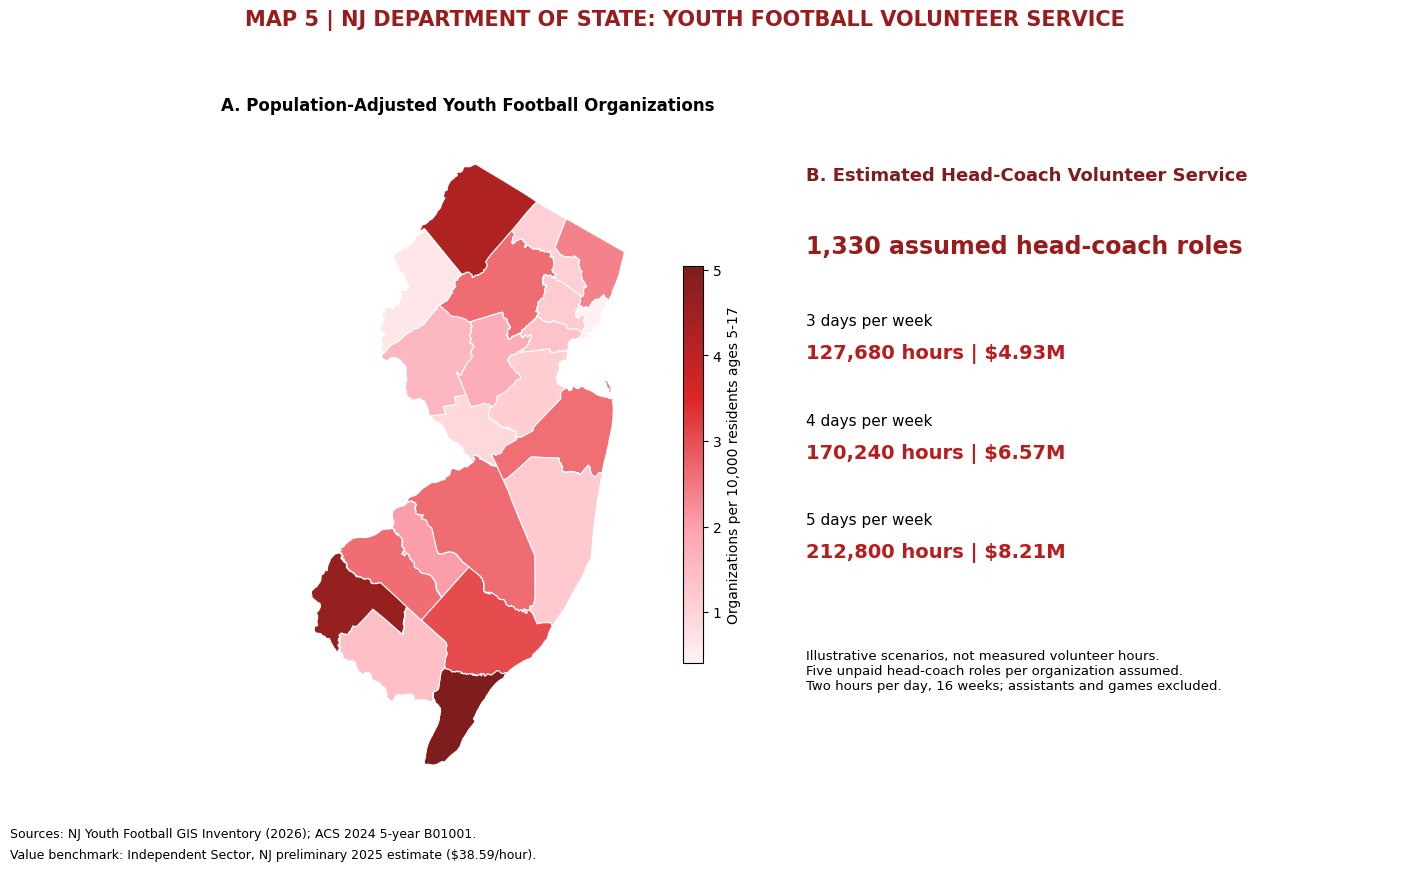

,COUNTY,Organizations,Youth_Population_5_17,Organizations_Per_10000_Youth,Head_Coach_Roles,Hours_4_days
4,Cape May,6,11893,5.04,30,3840
16,Salem,5,10752,4.65,25,3200
18,Sussex,9,21214,4.24,45,5760
0,Atlantic,13,42743,3.04,65,8320
2,Burlington,19,71961,2.64,95,12160
13,Morris,21,79668,2.64,105,13440
7,Gloucester,13,49538,2.62,65,8320
12,Monmouth,26,100018,2.60,130,16640
1,Bergen,36,151994,2.37,180,23040
3,Camden,18,88614,2.03,90,11520


In [58]:

# ======================================================
# PS4 - MAP 5
# NJ DEPARTMENT OF STATE: VOLUNTEER SERVICE
# ======================================================

import requests
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display

# STEP 1: Define assumptions

HEAD_COACHES_PER_ORG = 5
HOURS_PER_DAY = 2
SEASON_WEEKS = 16
VOLUNTEER_HOURLY_VALUE = 38.59

# Use county data already prepared in Map 5
m5 = map5_counties[
    ["COUNTY", "Organizations",
     "Volunteer_Listings", "geometry"]
].copy()

m5["COUNTY"] = m5["COUNTY"].str.strip().str.title()

assert len(m5) == 21
assert m5["COUNTY"].is_unique
assert m5["Organizations"].sum() == 266

# STEP 2: Calculate hypothetical volunteer hours

m5["Head_Coach_Roles"] = (
    m5["Organizations"] * HEAD_COACHES_PER_ORG
)

for days in [3, 4, 5]:
    m5[f"Hours_{days}_days"] = (
        m5["Head_Coach_Roles"]
        * HOURS_PER_DAY
        * days
        * SEASON_WEEKS
    )

    m5[f"Value_{days}_days"] = (
        m5[f"Hours_{days}_days"]
        * VOLUNTEER_HOURLY_VALUE
    )


# STEP 3: Retrieve official Census population data
# No API key or registration required
# Source: US Census Bureau, 2024 County Population Estimates

census_url = (
    "https://www2.census.gov/programs-surveys/popest/"
    "datasets/2020-2024/counties/asrh/"
    "cc-est2024-syasex-34.csv"
)

# Download New Jersey county population data
census_data = pd.read_csv(census_url, encoding="latin-1")

# Select July 2024 estimates (YEAR = 6)
# and children ages 5 through 17
youth = census_data[
    (census_data["YEAR"] == 6) &
    (census_data["AGE"].between(5, 17)) &
    (census_data["COUNTY"] != 0)
].copy()

# Calculate total population ages 5-17 by county
population = (
    youth.groupby("CTYNAME", as_index=False)["TOT_POP"]
    .sum()
    .rename(columns={
        "CTYNAME": "COUNTY",
        "TOT_POP": "Youth_Population_5_17"
    })
)

# Standardize county names
population["COUNTY"] = (
    population["COUNTY"]
    .str.replace(" County", "", regex=False)
    .str.strip()
)

# Validate results
assert len(population) == 21
assert population["COUNTY"].is_unique
assert (population["Youth_Population_5_17"] > 0).all()

print("Census population data successfully loaded!")
print("New Jersey counties:", len(population))

display(population.head())

# STEP 4: Join population to football data

m5 = m5.merge(
    population,
    on="COUNTY",
    how="left",
    validate="one_to_one"
)

assert m5["Youth_Population_5_17"].notna().all()
assert (m5["Youth_Population_5_17"] > 0).all()

m5["Organizations_Per_10000_Youth"] = (
    m5["Organizations"]
    / m5["Youth_Population_5_17"]
    * 10000
)

# STEP 5: Display statewide estimates

print("MAP 5 - STATEWIDE RESULTS")
print("-------------------------")
print("Counties:", len(m5))
print("Youth football organizations:",
      int(m5["Organizations"].sum()))
print("Estimated head-coach roles:",
      int(m5["Head_Coach_Roles"].sum()))

for days in [3, 4, 5]:
    hours = int(m5[f"Hours_{days}_days"].sum())
    value = m5[f"Value_{days}_days"].sum()

    print(
        f"{days} days per week: "
        f"{hours:,} estimated hours | "
        f"${value:,.0f} illustrative value"
    )

# STEP 6: Create red-themed GIS map

red_colors = LinearSegmentedColormap.from_list(
    "NJ_State_Red",
    ["#FFF1F2", "#FDA4AF", "#DC2626", "#7F1D1D"]
)

geo = m5.to_crs(epsg=26918)

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(15, 9),
    gridspec_kw={"width_ratios": [1.4, 1]}
)

geo.plot(
    column="Organizations_Per_10000_Youth",
    ax=ax1,
    cmap=red_colors,
    edgecolor="white",
    linewidth=0.8,
    legend=True,
    legend_kwds={
        "label": "Organizations per 10,000 residents ages 5-17",
        "shrink": 0.6
    }
)

ax1.set_title(
    "A. Population-Adjusted Youth Football Organizations",
    fontweight="bold",
    fontsize=12
)
ax1.set_axis_off()

# STEP 7: Volunteer impact summary

ax2.axis("off")

ax2.text(
    0.02, 0.93,
    "B. Estimated Head-Coach Volunteer Service",
    fontsize=13,
    fontweight="bold",
    color="#7F1D1D",
    transform=ax2.transAxes
)

total_coaches = int(m5["Head_Coach_Roles"].sum())

ax2.text(
    0.02, 0.82,
    f"{total_coaches:,} assumed head-coach roles",
    fontsize=17,
    fontweight="bold",
    color="#991B1B",
    transform=ax2.transAxes
)

for y, days in zip([0.66, 0.51, 0.36], [3, 4, 5]):
    hours = int(m5[f"Hours_{days}_days"].sum())
    value = m5[f"Value_{days}_days"].sum()

    ax2.text(
        0.02, y + 0.05,
        f"{days} days per week",
        fontsize=11,
        transform=ax2.transAxes
    )

    ax2.text(
        0.02, y,
        f"{hours:,} hours | ${value/1e6:.2f}M",
        fontsize=14,
        fontweight="bold",
        color="#B91C1C",
        transform=ax2.transAxes
    )

ax2.text(
    0.02, 0.16,
    "Illustrative scenarios, not measured volunteer hours.\n"
    "Five unpaid head-coach roles per organization assumed.\n"
    "Two hours per day, 16 weeks; assistants and games excluded.",
    fontsize=9.5,
    transform=ax2.transAxes
)

fig.suptitle(
    "MAP 5 | NJ DEPARTMENT OF STATE: "
    "YOUTH FOOTBALL VOLUNTEER SERVICE",
    fontsize=15,
    fontweight="bold",
    color="#991B1B",
    y=0.97
)

fig.text(
    0.05, 0.05,
    "Sources: NJ Youth Football GIS Inventory (2026); "
    "ACS 2024 5-year B01001.",
    fontsize=9
)

fig.text(
    0.05, 0.027,
    "Value benchmark: Independent Sector, "
    "NJ preliminary 2025 estimate ($38.59/hour).",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.08, 1, 0.93])

plt.savefig(
    "PS4_Map5_Red_Volunteer_Impact.png",
    dpi=220,
    bbox_inches="tight"
)

plt.savefig(
    "PS4_Map5_Red_Volunteer_Impact.pdf",
    bbox_inches="tight"
)

plt.show()

# STEP 8: Display county comparisons

display(
    m5[[
        "COUNTY",
        "Organizations",
        "Youth_Population_5_17",
        "Organizations_Per_10000_Youth",
        "Head_Coach_Roles",
        "Hours_4_days"
    ]]
    .sort_values(
        "Organizations_Per_10000_Youth",
        ascending=False
    )
    .round(2)
)

# Save county-level data for reproducibility
m5.drop(columns="geometry").to_csv(
    "PS4_Map5_County_Volunteer_Model.csv",
    index=False
)


### **Map 5 Interpretation — Volunteer Service and Youth Football**

Map 5 examines the distribution of 266 documented community youth football organizations relative to New Jersey's population ages 5–17. Cape May County has the highest observed rate at 5.04 organizations per 10,000 school-age residents, followed by Salem County (4.65) and Sussex County (4.24). This demonstrates why population-adjusted measures are important when comparing counties of different sizes.

The analysis also estimates the potential contribution of volunteer head coaches. Assuming five unpaid head-coaching roles per organization, two hours of service per day, and a 16-week season, approximately 127,680–212,800 coaching hours could be contributed during one football season.

Using a preliminary New Jersey volunteer-time valuation of USD 38.59 per hour, these scenarios represent approximately USD 4.93 million to USD 8.21 million in illustrative volunteer-service value.

These estimates exclude assistant coaches, games, administrative volunteers, and other contributions. They are not verified volunteer records or actual financial expenditures. Likewise, population-adjusted organization rates do not establish athlete participation, program capacity, or equitable access.

The findings provide a starting point for examining how volunteer recognition, recruitment, training, and organizational support could contribute to NJYASA's proposed coordination framework and potentially align with resources administered through the New Jersey Department of State.

## Map 6 — New Jersey Department of Children and Families: NJ4S Student Supports and Youth Football

### Research Question

How does NJ4S Tier 1 service attendance vary across New Jersey's 15 regional hubs, and how are documented community youth football organizations geographically distributed within those service areas?

### Research Purpose

The New Jersey Department of Children and Families administers the NJ Statewide Student Support Services (NJ4S) network, which provides prevention and wellness programming through 15 regional hubs. Services address mental health, social-emotional well-being, substance use prevention, and other concerns affecting students and families.

This analysis builds upon the NJ4S research conducted in PS1. It will compare historical Tier 1 attendance with the geographic distribution of 266 documented youth football organizations and the school-age population within each service region.

The objective is to identify potential opportunities for community outreach, information sharing, and future coordination. NJYASA is not assumed to have an existing partnership with DCF.

### Important Data Considerations

The NJ4S hub attendance figures cover August 2023 through August 2024 and may include repeat attendance by the same individuals, as well as caregivers and educators. The youth-football inventory represents 2026 organizations, while the population estimates are from 2024. These differences must be considered when interpreting the geographic comparisons.

**Sources:**
- New Jersey DCF, NJ4S Evaluation: Preliminary Phase 1 Findings, October 1, 2024
- U.S. Census Bureau, 2024 County Population Estimates
- NJ Youth Football GIS Inventory, 2026

https://www.nj.gov/dcf/documents/ARE-Presentation-Advisory-Taskforce_10-1-24.pdf

In [59]:

# ====================================================
# PS4 - MAP 6
# NJ DEPARTMENT OF CHILDREN AND FAMILIES
# NJ4S HUB DATA + YOUTH FOOTBALL + POPULATION
# ====================================================

import pandas as pd

# Historical NJ4S Tier 1 attendance from PS1.
# Source: DCF preliminary evaluation, Oct. 1, 2024.
# Figures are APPROXIMATE and may include repeat attendance.

hub_definitions = [
    ("Atlantic / Cape May", ["Atlantic", "Cape May"], 23000),
    ("Bergen", ["Bergen"], 2800),
    ("Burlington", ["Burlington"], 4900),
    ("Camden", ["Camden"], 17000),
    ("Essex", ["Essex"], 18000),
    ("Gloucester / Cumberland / Salem",
     ["Gloucester", "Cumberland", "Salem"], 17000),
    ("Hudson", ["Hudson"], 13000),
    ("Mercer", ["Mercer"], 8900),
    ("Middlesex", ["Middlesex"], 9800),
    ("Monmouth", ["Monmouth"], 7500),
    ("Morris / Sussex", ["Morris", "Sussex"], 16000),
    ("Ocean", ["Ocean"], 14000),
    ("Passaic", ["Passaic"], 17000),
    ("Somerset / Hunterdon / Warren",
     ["Somerset", "Hunterdon", "Warren"], 21000),
    ("Union", ["Union"], 5500)
]

# Build county-to-NJ4S-hub relationships
hub_rows = []
for hub, county_list, attendance in hub_definitions:
    for county in county_list:
        hub_rows.append({
            "COUNTY": county,
            "NJ4S_Hub": hub,
            "Approx_Tier1_Attendance": attendance
        })

hub_bridge = pd.DataFrame(hub_rows)

assert len(hub_definitions) == 15
assert len(hub_bridge) == 21
assert hub_bridge["COUNTY"].is_unique

# Reuse the county-level data calculated in Map 5.
# No new Census API request is necessary.

map6_counties = m5[
    ["COUNTY", "Organizations",
     "Youth_Population_5_17"]
].merge(
    hub_bridge,
    on="COUNTY",
    how="left",
    validate="one_to_one"
)

assert len(map6_counties) == 21
assert map6_counties["NJ4S_Hub"].notna().all()
assert map6_counties["Organizations"].sum() == 266

# Aggregate youth population and football programs
# to the correct 15-hub geographic unit.

map6_hubs = (
    map6_counties
    .groupby("NJ4S_Hub", as_index=False)
    .agg(
        Counties=("COUNTY", "nunique"),
        Football_Organizations=("Organizations", "sum"),
        Youth_Population_5_17=("Youth_Population_5_17", "sum"),
        Approx_Tier1_Attendance=("Approx_Tier1_Attendance", "first")
    )
)

map6_hubs["Football_Orgs_Per_10000_Youth"] = (
    map6_hubs["Football_Organizations"]
    / map6_hubs["Youth_Population_5_17"]
    * 10000
)

assert len(map6_hubs) == 15
assert map6_hubs["Counties"].sum() == 21
assert map6_hubs["Football_Organizations"].sum() == 266

print("NJ4S hubs:", len(map6_hubs))
print("Counties represented:", map6_hubs["Counties"].sum())
print("Football organizations:",
      map6_hubs["Football_Organizations"].sum())

display(
    map6_hubs.sort_values(
        "Approx_Tier1_Attendance",
        ascending=False
    ).round(2)
)

# Save source and geographic comparison tables
map6_hubs.to_csv(
    "PS4_Map6_NJ4S_Hub_Summary.csv",
    index=False
)

hub_bridge.to_csv(
    "PS4_Map6_NJ4S_County_Bridge.csv",
    index=False
)


NJ4S hubs: 15
Counties represented: 21
Football organizations: 266


,NJ4S_Hub,Counties,Football_Organizations,Youth_Population_5_17,Approx_Tier1_Attendance,Football_Orgs_Per_10000_Youth
0,Atlantic / Cape May,2,19,54636,23000,3.48
13,Somerset / Hunterdon / Warren,3,14,91444,21000,1.53
4,Essex,1,18,152339,18000,1.18
5,Gloucester / Cumberland / Salem,3,22,88520,17000,2.49
3,Camden,1,18,88614,17000,2.03
12,Passaic,1,10,91004,17000,1.10
10,Morris / Sussex,2,30,100882,16000,2.97
11,Ocean,1,14,116865,14000,1.20
6,Hudson,1,4,98660,13000,0.41
8,Middlesex,1,16,141664,9800,1.13


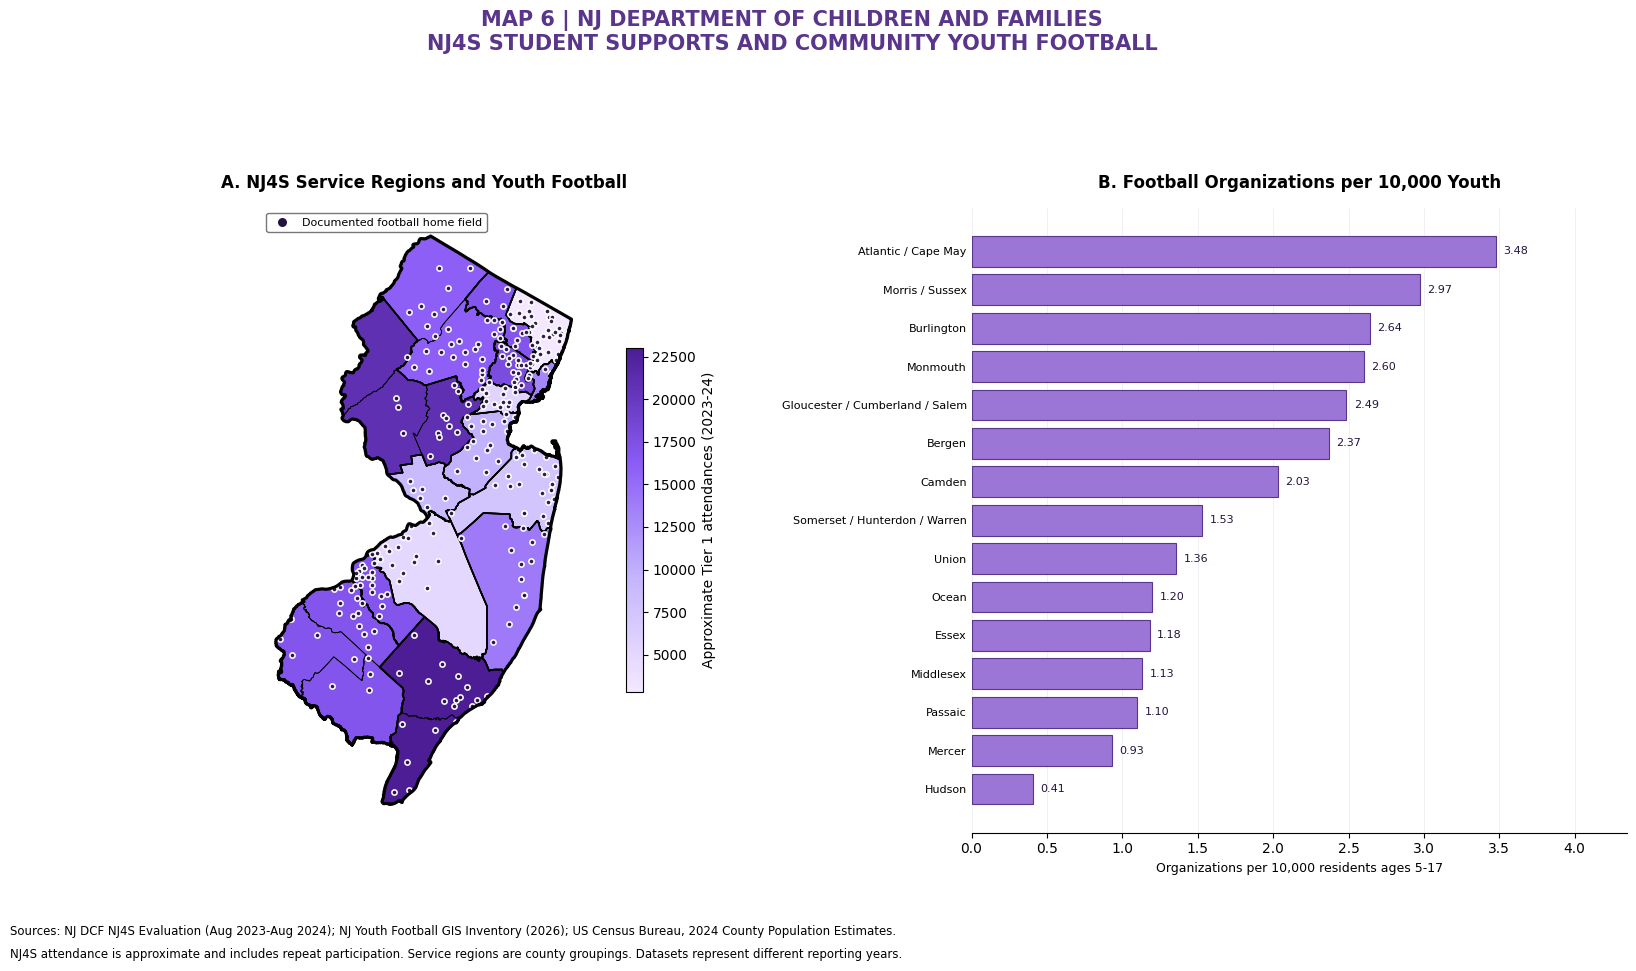

Map 6 generated successfully.
NJ4S service regions: 15
New Jersey counties: 21
Youth football locations: 266


In [60]:

# ======================================================
# PS4 - MAP 6
# NEW JERSEY DEPARTMENT OF CHILDREN AND FAMILIES
# NJ4S STUDENT SUPPORTS AND COMMUNITY YOUTH FOOTBALL
# ======================================================

import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

# ------------------------------------------------------
# STEP 1: Connect NJ4S hubs to NJ county boundaries
# ------------------------------------------------------

hub_geography = map5_counties[
    ["COUNTY", "geometry"]
].merge(
    hub_bridge[["COUNTY", "NJ4S_Hub"]],
    on="COUNTY",
    how="left",
    validate="one_to_one"
)

assert hub_geography["NJ4S_Hub"].notna().all()

# Combine counties within the same NJ4S hub
hub_geography = (
    hub_geography
    .dissolve(by="NJ4S_Hub", as_index=False)
    [["NJ4S_Hub", "geometry"]]
)

# Join hub-level attendance and population metrics
hub_map = hub_geography.merge(
    map6_hubs,
    on="NJ4S_Hub",
    how="left",
    validate="one_to_one"
)

assert len(hub_map) == 15
assert hub_map["Approx_Tier1_Attendance"].notna().all()

# Project all geographic layers into the same CRS
hub_map = hub_map.to_crs(epsg=26918)

county_outlines = map5_counties.to_crs(hub_map.crs)

# Create one outer boundary for New Jersey
nj_outline = county_outlines.dissolve()

# Reuse all documented youth football locations
football_locations = football_by_county.to_crs(
    hub_map.crs
)

assert len(football_locations) == 266

# ------------------------------------------------------
# STEP 2: Establish the purple DCF color scheme
# ------------------------------------------------------

purple_colors = LinearSegmentedColormap.from_list(
    "DCF_Purple",
    [
        "#F3E8FF",
        "#C4B5FD",
        "#8B5CF6",
        "#4C1D95"
    ]
)

# ------------------------------------------------------
# STEP 3: Create the figure
# ------------------------------------------------------

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(17, 10),
    gridspec_kw={
        "width_ratios": [1.2, 1]
    }
)

# ------------------------------------------------------
# A. NJ4S SERVICE REGIONS AND YOUTH FOOTBALL
# ------------------------------------------------------

# 1. Purple shading based on NJ4S Tier 1 attendance
hub_map.plot(
    column="Approx_Tier1_Attendance",
    ax=ax1,
    cmap=purple_colors,
    edgecolor="black",
    linewidth=1.0,
    legend=True,
    legend_kwds={
        "label": "Approximate Tier 1 attendances (2023-24)",
        "shrink": 0.55
    },
    zorder=1
)

# 2. Black county boundaries
county_outlines.boundary.plot(
    ax=ax1,
    color="black",
    linewidth=0.55,
    zorder=2
)

# 3. Strong black NJ4S regional boundaries
hub_map.boundary.plot(
    ax=ax1,
    color="black",
    linewidth=1.15,
    zorder=3
)

# 4. Youth football organizations
# Dark purple dots with strong white borders
football_locations.plot(
    ax=ax1,
    color="#24133E",
    edgecolor="white",
    linewidth=1.2,
    markersize=14,
    alpha=0.95,
    zorder=4
)

# 5. Thick black New Jersey state outline
nj_outline.boundary.plot(
    ax=ax1,
    color="black",
    linewidth=2.3,
    zorder=5
)

ax1.set_title(
    "A. NJ4S Service Regions and Youth Football",
    fontsize=12,
    fontweight="bold",
    pad=14
)

# Football location legend
ax1.legend(
    handles=[
        Line2D(
            [0], [0],
            marker="o",
            linestyle="None",
            markerfacecolor="#24133E",
            markeredgecolor="white",
            markeredgewidth=1.5,
            markersize=8,
            label="Documented football home field"
        )
    ],
    loc="upper left",
    fontsize=8,
    frameon=True,
    facecolor="white",
    edgecolor="#555555"
)

ax1.set_axis_off()
ax1.set_aspect("equal")

# ------------------------------------------------------
# B. POPULATION-ADJUSTED FOOTBALL ORGANIZATION RATES
# ------------------------------------------------------

ranked = hub_map.sort_values(
    "Football_Orgs_Per_10000_Youth",
    ascending=False
).reset_index(drop=True)

bars = ax2.barh(
    ranked["NJ4S_Hub"],
    ranked["Football_Orgs_Per_10000_Youth"],
    color="#9B76D6",
    edgecolor="#59358B",
    linewidth=0.8
)

ax2.invert_yaxis()

ax2.set_title(
    "B. Football Organizations per 10,000 Youth",
    fontsize=12,
    fontweight="bold",
    pad=14
)

ax2.set_xlabel(
    "Organizations per 10,000 residents ages 5-17",
    fontsize=9
)

ax2.tick_params(
    axis="y",
    labelsize=8,
    length=0
)

ax2.set_xlim(
    0,
    ranked["Football_Orgs_Per_10000_Youth"].max()
    * 1.25
)

# Show the exact value at the end of each bar
for bar in bars:
    value = bar.get_width()

    ax2.text(
        value + 0.05,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}",
        va="center",
        fontsize=8,
        color="#24133E"
    )

# Light gridlines for easier comparison
ax2.grid(
    axis="x",
    color="#E5E7EB",
    linewidth=0.6,
    alpha=0.7
)

ax2.set_axisbelow(True)

ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.spines["left"].set_visible(False)

# ------------------------------------------------------
# STEP 4: Main title and research notes
# ------------------------------------------------------

fig.suptitle(
    "MAP 6 | NJ DEPARTMENT OF CHILDREN AND FAMILIES\n"
    "NJ4S STUDENT SUPPORTS AND COMMUNITY YOUTH FOOTBALL",
    fontsize=15,
    fontweight="bold",
    color="#59358B",
    y=0.98
)

fig.text(
    0.04,
    0.055,
    "Sources: NJ DCF NJ4S Evaluation (Aug 2023-Aug 2024); "
    "NJ Youth Football GIS Inventory (2026); "
    "US Census Bureau, 2024 County Population Estimates.",
    fontsize=8.5
)

fig.text(
    0.04,
    0.032,
    "NJ4S attendance is approximate and includes repeat participation. "
    "Service regions are county groupings. "
    "Datasets represent different reporting years.",
    fontsize=8.5
)

plt.tight_layout(
    rect=[0, 0.10, 1, 0.89],
    w_pad=3
)

# ------------------------------------------------------
# STEP 5: Save the finished map
# ------------------------------------------------------

plt.savefig(
    "PS4_Map6_NJ4S_Youth_Football_Purple.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.savefig(
    "PS4_Map6_NJ4S_Youth_Football_Purple.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# ------------------------------------------------------
# STEP 6: Confirm results
# ------------------------------------------------------

print("Map 6 generated successfully.")
print("NJ4S service regions:", len(hub_map))
print("New Jersey counties:", len(county_outlines))
print("Youth football locations:", len(football_locations))


### **Map 6 Interpretation — NJ4S Student Supports and Community Youth Football**

Map 6 examines the geographic relationship between New Jersey's 15 NJ4S service regions and 266 documented community youth football organizations. The analysis compares historical NJ4S Tier 1 attendance with the distribution of football organizations relative to the population ages 5–17.

The population-adjusted analysis identifies Atlantic/Cape May as having the highest documented football organization rate, at 3.48 organizations per 10,000 school-age residents, followed by Morris/Sussex (2.97) and Burlington (2.64). Hudson has the lowest observed rate (0.41). These differences demonstrate the importance of accounting for population when comparing geographic areas.

The NJ4S attendance data also vary considerably across service regions. However, these figures represent approximate attendance during August 2023–August 2024, may include repeat participation and adults, and should not be interpreted as unique students served or evidence of unmet demand. The football inventory represents 2026, while the population estimates represent 2024.

**Public Administration and NJYASA Implications**

The findings demonstrate that DCF already operates a geographically organized student-support network across New Jersey. Community youth football organizations represent a separate network of local organizations operating within these same geographic areas.

This geographic relationship suggests an opportunity to investigate whether NJYASA's proposed County Conferences and Regional Councils could facilitate communication, resource awareness, and referrals between youth-sports organizations and existing student-support systems.

However, geographic overlap does not establish that youth football organizations currently participate in NJ4S programming, that a partnership exists, or that coordination would improve service outcomes.

Further research involving NJ4S administrators, youth-sports organizations, and service utilization data would be necessary to evaluate the practical feasibility and potential public value of such coordination.

## **Map 7 — New Jersey Department of Community Affairs: Public Recreation Investment and Youth Football**

### Research Question

How does public recreation funding vary across New Jersey counties relative to school-age populations and documented community youth-football organizations, and what opportunities does this suggest for coordinating local recreation needs?

### Research Purpose

The New Jersey Department of Community Affairs administers the Local Recreation Improvement Grant (LRIG) program through its Division of Local Government Services. The program provides funding to eligible counties, municipalities, and school districts for improvements to public recreation facilities.

This analysis examines FY2026 LRIG awards alongside 266 documented youth-football organizations across New Jersey's 21 counties.

The analysis will measure:

- Total recreation grant dollars awarded by county.
- Grant awards relative to county populations ages 5–17.
- Number of grant recipients in each county.
- Geographic relationships between public recreation investment and community youth-football organizations.

### Public Administration and NJYASA Relevance

NJYASA's proposed County Conferences could potentially help local youth-sports organizations communicate facility needs to municipalities and other eligible public entities.

Understanding where recreation grants are awarded, how much funding is awarded, and when applications are accepted could inform future coordination between community sports organizations and local governments.

### Important Data Considerations

The FY2026 grant awards were announced on April 13, 2026. These amounts represent funding awards, not verified expenditures or direct funding to youth-football organizations.

The grants support public recreation generally and may serve residents of all ages. Population-adjusted award amounts provide a geographic comparison but do not measure actual spending per child or establish whether recreation needs are adequately funded.

The current research also does not establish which youth-football organizations are directly municipally operated or independently governed.

### Data Sources

- NJ Department of Community Affairs — FY2026 Local Recreation Improvement Grant Awards.
- U.S. Census Bureau — 2024 County Population Estimates.
- NJ Youth Football GIS Inventory — 2026.

Official DCA grant program:

https://www.nj.gov/dca/dlgs/programs/lriggrants.shtml

Official FY2026 award listing:

https://www.nj.gov/dca/dlgs/programs/lrig_docs/2026%20LRIG/FY2026_LRIG_Grant_Awards_Listing.pdf

In [61]:

# ======================================================
# PS4 - MAP 7: NEW JERSEY DEPARTMENT OF COMMUNITY AFFAIRS
# FY2026 LOCAL RECREATION IMPROVEMENT GRANTS
# ======================================================

%pip -q install pdfplumber

import io
import re
import requests
import pdfplumber
import pandas as pd
from IPython.display import display

# STEP 1 - Download the official NJ DCA grant listing

dca_url = (
    "https://www.nj.gov/dca/dlgs/programs/lrig_docs/"
    "2026%20LRIG/FY2026_LRIG_Grant_Awards_Listing.pdf"
)

try:
    response = requests.get(
        dca_url,
        headers={"User-Agent": "Mozilla/5.0"},
        timeout=60
    )
    response.raise_for_status()
    pdf_bytes = response.content

except requests.RequestException:
    print("Automatic download unavailable.")
    print("Download the official DCA PDF and upload it here.")

    from google.colab import files
    uploaded = files.upload()
    pdf_bytes = next(iter(uploaded.values()))

assert pdf_bytes[:4] == b"%PDF", "File is not a PDF."

# STEP 2 - Extract grant records

nj_counties = set(
    map5_counties["COUNTY"].str.strip().str.title()
)

records = []
pdf_pages = []

with pdfplumber.open(io.BytesIO(pdf_bytes)) as pdf:
    for page in pdf.pages:
        pdf_pages.append(page)

        for table in page.extract_tables():
            for row in table:
                if not row or len(row) < 3:
                    continue

                cells = [
                    " ".join(str(value or "").split())
                    for value in row[:3]
                ]

                agency, county, amount = cells
                amount_clean = re.sub(r"[$,\s]", "", amount)

                if (
                    county in nj_counties
                    and amount_clean.isdigit()
                ):
                    records.append({
                        "Recipient": agency,
                        "County_Published": county,
                        "Award_Amount_USD": int(amount_clean)
                    })

    # Backup: extract using the PDF text if tables
    # did not capture all 154 records.

    if len(records) != 154:
        records = []

        county_pattern = "|".join(
            re.escape(c)
            for c in sorted(nj_counties, key=len, reverse=True)
        )

        pattern = re.compile(
            r"^(.+?)\s+(" + county_pattern +
            r")\s+\$?([\d,]+)$"
        )

        for page in pdf.pages:
            for line in (page.extract_text() or "").splitlines():
                match = pattern.match(line.strip())

                if match:
                    records.append({
                        "Recipient": match.group(1).strip(),
                        "County_Published": match.group(2),
                        "Award_Amount_USD": int(
                            match.group(3).replace(",", "")
                        )
                    })

dca_grants = pd.DataFrame(records)

# STEP 3 - Verify against the official DCA listing

print("Grant records extracted:", len(dca_grants))

assert len(dca_grants) == 154, (
    "Expected 154 awards. Review PDF extraction."
)

total_awards = int(
    dca_grants["Award_Amount_USD"].sum()
)

assert total_awards == 9918449, (
    f"Unexpected grant total: {total_awards:,}"
)

print("Official grant total verified: USD",
      f"{total_awards:,}")

# STEP 4 - Correct a published county discrepancy
# DCA lists Fredon Township under Atlantic County.
# Fredon Township is located in Sussex County.
# Keep both the original and corrected county names.

dca_grants["COUNTY"] = dca_grants["County_Published"]

fredon = (
    dca_grants["Recipient"].eq("Fredon Township")
    & dca_grants["County_Published"].eq("Atlantic")
)

assert fredon.sum() == 1

dca_grants.loc[fredon, "COUNTY"] = "Sussex"

print("Fredon Township county correction recorded.")

# STEP 5 - Summarize grants by county

dca_summary = (
    dca_grants.groupby("COUNTY", as_index=False)
    .agg(
        Grant_Awards=("Recipient", "size"),
        Award_Dollars=("Award_Amount_USD", "sum")
    )
)

# STEP 6 - Join to existing GIS and population data

map7_counties = (
    map5_counties[["COUNTY", "geometry"]]
    .merge(
        dca_summary,
        on="COUNTY",
        how="left",
        validate="one_to_one"
    )
    .merge(
        m5[[
            "COUNTY",
            "Organizations",
            "Youth_Population_5_17"
        ]],
        on="COUNTY",
        how="left",
        validate="one_to_one"
    )
)

map7_counties[
    ["Grant_Awards", "Award_Dollars"]
] = map7_counties[
    ["Grant_Awards", "Award_Dollars"]
].fillna(0)

# STEP 7 - Calculate population-adjusted measures

map7_counties["Award_Dollars_Per_Youth"] = (
    map7_counties["Award_Dollars"]
    / map7_counties["Youth_Population_5_17"]
)

map7_counties["Awards_Per_10000_Youth"] = (
    map7_counties["Grant_Awards"]
    / map7_counties["Youth_Population_5_17"]
    * 10000
)

# STEP 8 - Validate all county data

assert len(map7_counties) == 21
assert map7_counties["COUNTY"].is_unique
assert map7_counties["Organizations"].sum() == 266
assert map7_counties["Grant_Awards"].sum() == 154
assert map7_counties["Award_Dollars"].sum() == 9918449
assert map7_counties["Youth_Population_5_17"].notna().all()

print("\nMAP 7 - VALIDATED RESULTS")
print("---------------------------")
print("Counties:", len(map7_counties))
print("Football organizations:",
      int(map7_counties["Organizations"].sum()))
print("DCA grant awards:",
      int(map7_counties["Grant_Awards"].sum()))
print("Total grant dollars:",
      f"${int(map7_counties['Award_Dollars'].sum()):,}")

# STEP 9 - Display county funding comparisons

display(
    map7_counties[[
        "COUNTY",
        "Grant_Awards",
        "Award_Dollars",
        "Youth_Population_5_17",
        "Award_Dollars_Per_Youth",
        "Organizations"
    ]]
    .sort_values(
        "Award_Dollars_Per_Youth",
        ascending=False
    )
    .round(2)
)

# STEP 10 - Save data for reproducibility

dca_grants.to_csv(
    "PS4_Map7_DCA_FY2026_Grant_Records.csv",
    index=False
)

map7_counties.drop(
    columns="geometry"
).to_csv(
    "PS4_Map7_DCA_County_Analysis.csv",
    index=False
)

print("\nMap 7 data preparation completed successfully.")


Grant records extracted: 154
Official grant total verified: USD 9,918,449
Fredon Township county correction recorded.

MAP 7 - VALIDATED RESULTS
---------------------------
Counties: 21
Football organizations: 266
DCA grant awards: 154
Total grant dollars: $9,918,449


,COUNTY,Grant_Awards,Award_Dollars,Youth_Population_5_17,Award_Dollars_Per_Youth,Organizations
18,Sussex,16,1030795,21214,48.59,9
16,Salem,7,457900,10752,42.59,5
20,Warren,5,306800,16049,19.12,1
4,Cape May,3,198100,11893,16.66,6
9,Hunterdon,5,313300,18985,16.50,3
5,Cumberland,5,328487,28230,11.64,4
13,Morris,13,855912,79668,10.74,21
12,Monmouth,16,1035735,100018,10.36,26
7,Gloucester,8,500400,49538,10.10,13
0,Atlantic,6,399700,42743,9.35,13



Map 7 data preparation completed successfully.


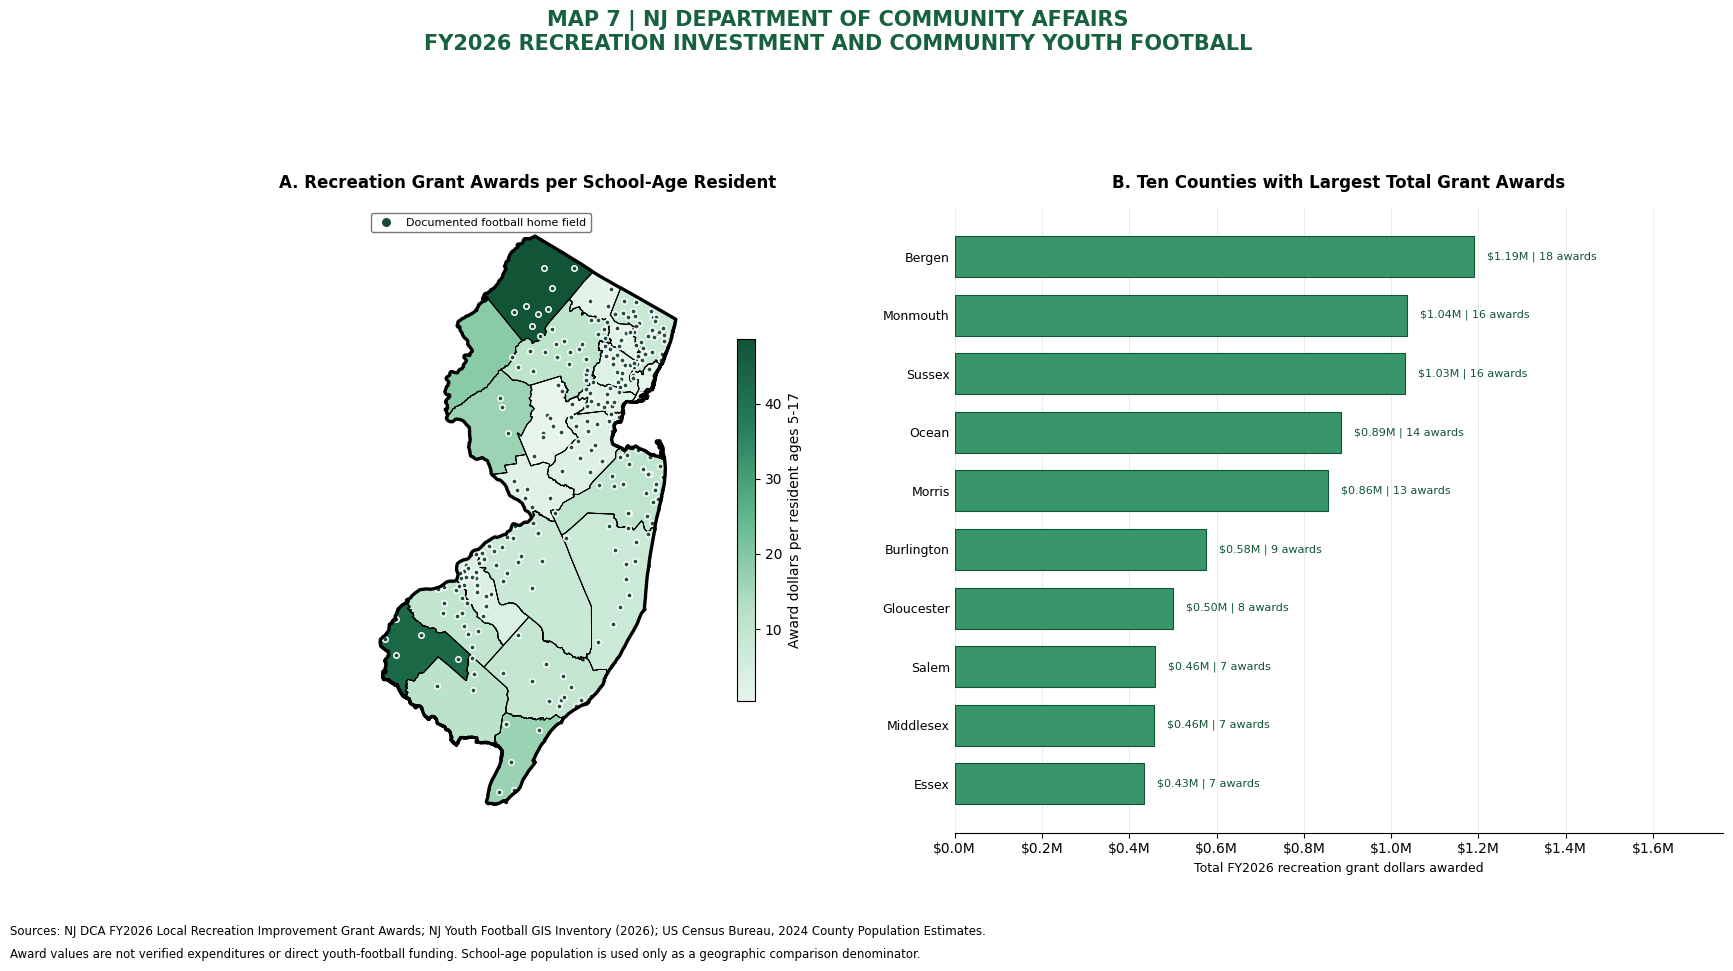

Map 7 generated successfully.
New Jersey counties: 21
Youth football locations: 266
DCA grants: 154
Total awarded: $9,918,449


In [62]:

# ======================================================
# PS4 - MAP 7
# NJ DEPARTMENT OF COMMUNITY AFFAIRS
# FY2026 RECREATION GRANTS AND COMMUNITY YOUTH FOOTBALL
# ======================================================

import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

# ------------------------------------------------------
# STEP 1 - Prepare and validate geographic data
# ------------------------------------------------------

m7 = gpd.GeoDataFrame(
    map7_counties.copy(),
    geometry="geometry",
    crs=map5_counties.crs
).to_crs(epsg=26918)

football_locations = football_by_county.to_crs(m7.crs)

nj_outline = m7[["geometry"]].dissolve()

assert len(m7) == 21
assert len(football_locations) == 266
assert m7["Grant_Awards"].sum() == 154
assert m7["Award_Dollars"].sum() == 9918449
assert m7["Award_Dollars_Per_Youth"].notna().all()

# ------------------------------------------------------
# STEP 2 - DCA green color palette
# ------------------------------------------------------

green_colors = LinearSegmentedColormap.from_list(
    "DCA_Green",
    [
        "#E7F5EC",
        "#B7E1C7",
        "#63B88E",
        "#27805B",
        "#125436"
    ]
)

# ------------------------------------------------------
# STEP 3 - Create map and funding comparison
# ------------------------------------------------------

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(18, 10),
    gridspec_kw={
        "width_ratios": [1.2, 1]
    }
)

# ------------------------------------------------------
# A. POPULATION-ADJUSTED GRANT AWARDS
# ------------------------------------------------------

m7.plot(
    column="Award_Dollars_Per_Youth",
    ax=ax1,
    cmap=green_colors,
    edgecolor="black",
    linewidth=0.6,
    legend=True,
    legend_kwds={
        "label": "Award dollars per resident ages 5-17",
        "shrink": 0.58
    },
    zorder=1
)

# Black county boundaries
m7.boundary.plot(
    ax=ax1,
    color="black",
    linewidth=0.65,
    zorder=2
)

# Dark green football dots with white outlines
football_locations.plot(
    ax=ax1,
    color="#154A35",
    edgecolor="white",
    linewidth=1.2,
    markersize=15,
    alpha=0.95,
    zorder=3
)

# Thick black New Jersey outer border
nj_outline.boundary.plot(
    ax=ax1,
    color="black",
    linewidth=2.4,
    zorder=4
)

ax1.set_title(
    "A. Recreation Grant Awards per School-Age Resident",
    fontsize=12,
    fontweight="bold",
    pad=14
)

ax1.legend(
    handles=[
        Line2D(
            [0], [0],
            marker="o",
            linestyle="None",
            markerfacecolor="#154A35",
            markeredgecolor="white",
            markeredgewidth=1.5,
            markersize=8,
            label="Documented football home field"
        )
    ],
    loc="upper left",
    fontsize=8,
    frameon=True,
    facecolor="white",
    edgecolor="#555555"
)

ax1.set_axis_off()
ax1.set_aspect("equal")

# ------------------------------------------------------
# B. TEN COUNTIES WITH LARGEST TOTAL GRANT AWARDS
# ------------------------------------------------------

top10 = (
    m7.nlargest(10, "Award_Dollars")
    .sort_values("Award_Dollars", ascending=True)
)

bars = ax2.barh(
    top10["COUNTY"],
    top10["Award_Dollars"],
    color="#38966A",
    edgecolor="#125436",
    linewidth=0.8,
    height=0.7
)

ax2.set_title(
    "B. Ten Counties with Largest Total Grant Awards",
    fontsize=12,
    fontweight="bold",
    pad=14
)

ax2.set_xlabel(
    "Total FY2026 recreation grant dollars awarded",
    fontsize=9
)

ax2.tick_params(axis="y", labelsize=9, length=0)

max_award = top10["Award_Dollars"].max()

ax2.set_xlim(0, max_award * 1.48)

# Show grant amount and award count for each county
for bar, (_, record) in zip(bars, top10.iterrows()):

    value = record["Award_Dollars"]
    grants = int(record["Grant_Awards"])

    ax2.text(
        value + max_award * 0.025,
        bar.get_y() + bar.get_height() / 2,
        f"${value/1_000_000:.2f}M | {grants} awards",
        va="center",
        fontsize=8,
        color="#125436"
    )

# Format x-axis as millions of dollars
ax2.xaxis.set_major_formatter(
    FuncFormatter(
        lambda x, pos: f"${x/1_000_000:.1f}M"
    )
)

ax2.grid(
    axis="x",
    color="#E2E8E5",
    linewidth=0.7,
    alpha=0.8
)

ax2.set_axisbelow(True)

ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.spines["left"].set_visible(False)

# ------------------------------------------------------
# STEP 4 - Main heading and research notes
# ------------------------------------------------------

fig.suptitle(
    "MAP 7 | NJ DEPARTMENT OF COMMUNITY AFFAIRS\n"
    "FY2026 RECREATION INVESTMENT AND COMMUNITY YOUTH FOOTBALL",
    fontsize=15,
    fontweight="bold",
    color="#17613F",
    y=0.98
)

fig.text(
    0.04,
    0.055,
    "Sources: NJ DCA FY2026 Local Recreation Improvement "
    "Grant Awards; NJ Youth Football GIS Inventory (2026); "
    "US Census Bureau, 2024 County Population Estimates.",
    fontsize=8.5
)

fig.text(
    0.04,
    0.032,
    "Award values are not verified expenditures or direct "
    "youth-football funding. School-age population is used "
    "only as a geographic comparison denominator.",
    fontsize=8.5
)

plt.tight_layout(
    rect=[0, 0.10, 1, 0.89],
    w_pad=3
)

# ------------------------------------------------------
# STEP 5 - Save map as PNG and PDF
# ------------------------------------------------------

plt.savefig(
    "PS4_Map7_DCA_Recreation_Investment_Green.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.savefig(
    "PS4_Map7_DCA_Recreation_Investment_Green.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# ------------------------------------------------------
# STEP 6 - Verify final results
# ------------------------------------------------------

print("Map 7 generated successfully.")
print("New Jersey counties:", len(m7))
print("Youth football locations:", len(football_locations))
print("DCA grants:", int(m7["Grant_Awards"].sum()))
print(
    "Total awarded:",
    f"${int(m7['Award_Dollars'].sum()):,}"
)


### **Map 7 Interpretation — Public Recreation Investment and Community Youth Football**

Map 7 examines the geographic distribution of New Jersey's FY2026 Local Recreation Improvement Grant (LRIG) awards relative to school-age populations and 266 documented community youth-football organizations.

The analysis identifies 154 grant awards totaling USD 9,918,449 across New Jersey's 21 counties. Bergen County received the largest total funding amount, approximately USD 1.19 million, followed by Monmouth County (USD 1.04 million) and Sussex County (USD 1.03 million).

However, population-adjusted funding reveals a different geographic pattern. Sussex County received approximately USD 48.59 in grant awards per resident ages 5–17, followed by Salem County at USD 42.59. By comparison, Burlington County received USD 8.01 per school-age resident, while Bergen County received USD 7.83.

These differences demonstrate the importance of comparing absolute funding amounts with population-adjusted measures. Counties receiving the largest total awards do not necessarily receive the highest amounts relative to their school-age populations.

### Grant Application and Funding Timeline

For FY2026, DCA opened applications on December 2, 2025, established a February 13, 2026 application deadline, and announced grant awards on April 13, 2026.

The grant program operates on a reimbursement basis. Eligible public entities must incur qualifying expenses and submit supporting documentation before receiving reimbursement.

These dates describe the FY2026 cycle and should not be assumed to apply to future funding cycles.

### Public Administration and NJYASA Implications

New Jersey's recreation-improvement grant program provides an existing mechanism through which municipalities, counties, and school districts can seek financial assistance for public recreation infrastructure.

NJYASA's proposed County Conferences could potentially assist independent youth-sports organizations in communicating facility concerns, equipment needs, and recreation priorities to the eligible public entities responsible for grant applications.

The funding timeline also suggests a potential coordinating role in identifying facility needs before annual application periods begin.

For example, Burlington County's 19 documented youth-football organizations operate within a county where nine FY2026 grant awards totaled USD 576,100. This establishes a geographic relationship between community youth-football organizations and public recreation investment, but it does not establish that those organizations directly benefited from the grants.

### Research Limitations

LRIG awards support public recreation generally, including facilities used by residents of different ages. The data do not establish how much funding directly benefits youth football.

Award amounts represent approved funding rather than verified expenditures. County-level award assignments do not necessarily identify the exact location of the funded improvements.

Population-adjusted awards are geographic comparison measures, not actual expenditures per child. One grant cycle cannot independently establish long-term funding equity or whether communities have adequate recreation infrastructure.

Further research would be necessary to identify specific funded projects, municipal relationships with youth-sports organizations, and the extent to which recreation improvements benefit documented youth-football programs.

## Map 8 — New Jersey Department of Education: Out-of-School Educational Opportunities and Community Youth Football

### Research Question

How does the geographic distribution of New Jersey Department of Education-funded 21st Century Community Learning Centers compare with documented community youth-football organizations across New Jersey's 21 counties, relative to school-age populations?

### Research Purpose

The New Jersey Department of Education administers the federally funded 21st Century Community Learning Centers (21st CCLC) program. These programs provide academic enrichment and other opportunities outside regular school hours, including youth development, physical activity, wellness education, and family engagement.

This analysis compares the NJDOE's October 2026 directory of 64 funded 21st CCLC programs with 266 documented community youth-football organizations.

The analysis will examine:

- The number of NJDOE-listed 21st CCLC grantees by county.
- The number of 21st CCLC grantee listings per 10,000 residents ages 5–17.
- The number of community youth-football organizations per 10,000 residents ages 5–17.
- Geographic differences and similarities between these two community-based networks.

### Public Administration and NJYASA Relevance

Education is one of NJYASA's proposed core pillars.

The 21st CCLC program demonstrates an existing public education framework connecting schools, families, nonprofit organizations, and community-based educational services.

NJYASA's proposed County Conferences could potentially facilitate communication and resource awareness between participating community youth-sports organizations and existing educational programs.

The objective is to identify possible areas for further collaboration, not to assume that existing NJDOE-funded organizations have agreed to partner with NJYASA.

### Important Data Considerations

The NJDOE directory identifies funded grantees, not necessarily individual physical program sites, student enrollment, or program capacity.

The youth-football inventory represents 266 documented organizations in 2026, while the population estimates are from 2024.

Population-adjusted organization counts describe geographic concentration. They do not establish educational need, equitable access, or the effectiveness of either type of program.

### Data Sources

- New Jersey Department of Education — 21st CCLC Grantee Directory, updated October 8, 2026.
- U.S. Census Bureau — 2024 County Population Estimates.
- NJ Youth Football GIS Inventory — 2026.

Official NJDOE directory:

https://www.nj.gov/education/21cclc/abstracts/

21st CCLC Program Overview:

https://www.nj.gov/education/21cclc/

In [63]:

# ======================================================
# PS4 - MAP 8
# NJ DEPARTMENT OF EDUCATION
# 21st CCLC AND COMMUNITY YOUTH FOOTBALL
# ======================================================

import pandas as pd
from IPython.display import display

# ------------------------------------------------------
# STEP 1 - NJDOE 21st CCLC grantee directory
# Source: https://www.nj.gov/education/21cclc/abstracts/
# Directory updated: October 8, 2026
# County listings are NOT necessarily physical sites.
# ------------------------------------------------------

cclc_by_county = {
    "Atlantic": [
        "Boys and Girls Club of Atlantic City",
        "Buena Regional",
        "Egg Harbor City",
        "Egg Harbor Township School District",
        "Future Leaders Organization",
        "Mullica Township School District",
        "Pleasantville Public Schools"
    ],
    "Bergen": [
        "Boys and Girls Club of Garfield",
        "Boys and Girls of Lower Bergen County",
        "Meadowlands Area YMCA"
    ],
    "Burlington": [
        "Pemberton School District"
    ],
    "Camden": [
        "Boys and Girls Club of Camden County",
        "LEAP Academy University Charter School",
        "Rutgers University Camden"
    ],
    "Cape May": [
        "Wildwood Public Schools"
    ],
    "Cumberland": [
        "Bridgeton Public Schools",
        "Millville School District"
    ],
    "Essex": [
        "East Orange School District",
        "FOCUS Hispanic Center for Community Development, Inc.",
        "Ironbound Community Corporation",
        "Newark Alliance",
        "Rutgers University-Newark",
        "United Community Corporation"
    ],
    "Gloucester": [
        "Boys and Girls Clubs of Gloucester County",
        "Glassboro Child Development Center",
        "Woodbury City Public Schools"
    ],
    "Hudson": [
        "Boys and Girls Clubs of Hudson County",
        "Jersey City Public Schools",
        "New Hope Educate the Child (ETC)",
        "Saint Peter's University",
        "Team Walker Learning Center",
        "The Ethical Community Charter School",
        "Union City Public Schools",
        "Yonkers Partners in Education"
    ],
    "Hunterdon": [],
    "Mercer": [
        "Boys and Girls Clubs of Mercer County",
        "Capital Area YMCA",
        "The Children's Home Society of New Jersey",
        "Mercer County Community College"
    ],
    "Middlesex": [
        "South River School District"
    ],
    "Monmouth": [
        "Boys and Girls Clubs of Monmouth County",
        "Freehold Borough Public Schools",
        "Keansburg School District",
        "Long Branch"
    ],
    "Morris": [],
    "Ocean": [],
    "Passaic": [
        "Boys & Girls Club of Clifton",
        "Boys and Girls Club of Paterson and Passaic",
        "Clifton School District",
        "College Achieve Paterson Charter School",
        "The Community Charter School of Paterson",
        "New Jersey Community Development Corporation",
        "Passaic Arts and Science Charter Schools",
        "Passaic City School District",
        "Paterson Education Foundation, Inc.",
        "Paterson Public Schools"
    ],
    "Salem": [
        "Salem County Vocational Technical School District"
    ],
    "Somerset": [
        "Middle Earth",
        "North Plainfield School District"
    ],
    "Sussex": [
        "Newton Public Schools"
    ],
    "Union": [
        "Impact 21",
        "Linden School District",
        "Plainfield Community Outreach",
        "Plainfield Public Schools",
        "Roselle Borough",
        "Union Township"
    ],
    "Warren": [
        "Phillipsburg School District"
    ]
}

# ------------------------------------------------------
# STEP 2 - Create an auditable grantee inventory
# ------------------------------------------------------

cclc_records = [
    {
        "COUNTY": county,
        "Grantee": name,
        "Source_Date": "2026-10-08"
    }
    for county, names in cclc_by_county.items()
    for name in names
]

cclc_grantees = pd.DataFrame(cclc_records)

assert len(cclc_by_county) == 21
assert len(cclc_grantees) == 64

# Summarize grantee listings by county
cclc_summary = pd.DataFrame({
    "COUNTY": list(cclc_by_county.keys()),
    "CCLC_Grantees": [
        len(names) for names in cclc_by_county.values()
    ]
})

assert cclc_summary["CCLC_Grantees"].sum() == 64
assert (cclc_summary["CCLC_Grantees"] > 0).sum() == 18

# ------------------------------------------------------
# STEP 3 - Reuse existing Map 5 Census and GIS data
# ------------------------------------------------------

map8_counties = (
    map5_counties[["COUNTY", "geometry"]]
    .copy()
    .merge(
        m5[[
            "COUNTY",
            "Organizations",
            "Youth_Population_5_17"
        ]],
        on="COUNTY",
        how="left",
        validate="one_to_one"
    )
    .merge(
        cclc_summary,
        on="COUNTY",
        how="left",
        validate="one_to_one"
    )
)

# ------------------------------------------------------
# STEP 4 - Validate the geographic join
# ------------------------------------------------------

assert len(map8_counties) == 21
assert map8_counties["COUNTY"].is_unique
assert map8_counties["CCLC_Grantees"].notna().all()
assert map8_counties["Organizations"].notna().all()
assert map8_counties["Organizations"].sum() == 266
assert map8_counties["CCLC_Grantees"].sum() == 64
assert (map8_counties["Youth_Population_5_17"] > 0).all()

# ------------------------------------------------------
# STEP 5 - Calculate population-adjusted measures
# ------------------------------------------------------

map8_counties["CCLC_Per_10000_Youth"] = (
    map8_counties["CCLC_Grantees"]
    / map8_counties["Youth_Population_5_17"]
    * 10000
)

map8_counties["Football_Per_10000_Youth"] = (
    map8_counties["Organizations"]
    / map8_counties["Youth_Population_5_17"]
    * 10000
)

# Difference is NOT calculated because the two
# program categories are not equivalent services.

# ------------------------------------------------------
# STEP 6 - Display statewide results
# ------------------------------------------------------

print("MAP 8 - VALIDATED RESULTS")
print("-------------------------")
print("New Jersey counties:", len(map8_counties))
print("NJDOE CCLC grantee listings:",
      int(map8_counties["CCLC_Grantees"].sum()))
print("Counties with listed CCLC grantees:",
      int((map8_counties["CCLC_Grantees"] > 0).sum()))
print("Youth football organizations:",
      int(map8_counties["Organizations"].sum()))

print("\nCounties without listed CCLC grantees:")
print(
    ", ".join(
        map8_counties.loc[
            map8_counties["CCLC_Grantees"] == 0,
            "COUNTY"
        ].sort_values()
    )
)

display(
    map8_counties[[
        "COUNTY",
        "CCLC_Grantees",
        "CCLC_Per_10000_Youth",
        "Organizations",
        "Football_Per_10000_Youth",
        "Youth_Population_5_17"
    ]]
    .sort_values(
        "CCLC_Grantees",
        ascending=False
    )
    .round(2)
)

# ------------------------------------------------------
# STEP 7 - Save data for GitHub reproducibility
# ------------------------------------------------------

cclc_grantees.to_csv(
    "PS4_Map8_NJDOE_CCLC_Grantee_Inventory.csv",
    index=False
)

map8_counties.drop(
    columns="geometry"
).to_csv(
    "PS4_Map8_NJDOE_County_Comparison.csv",
    index=False
)

print("\nMap 8 data preparation completed successfully.")


MAP 8 - VALIDATED RESULTS
-------------------------
New Jersey counties: 21
NJDOE CCLC grantee listings: 64
Counties with listed CCLC grantees: 18
Youth football organizations: 266

Counties without listed CCLC grantees:
Hunterdon, Morris, Ocean


,COUNTY,CCLC_Grantees,CCLC_Per_10000_Youth,Organizations,Football_Per_10000_Youth,Youth_Population_5_17
15,Passaic,10,1.10,10,1.10,91004
8,Hudson,8,0.81,4,0.41,98660
0,Atlantic,7,1.64,13,3.04,42743
6,Essex,6,0.39,18,1.18,152339
19,Union,6,0.58,14,1.36,103186
12,Monmouth,4,0.40,26,2.60,100018
10,Mercer,4,0.62,6,0.93,64544
3,Camden,3,0.34,18,2.03,88614
1,Bergen,3,0.20,36,2.37,151994
7,Gloucester,3,0.61,13,2.62,49538



Map 8 data preparation completed successfully.


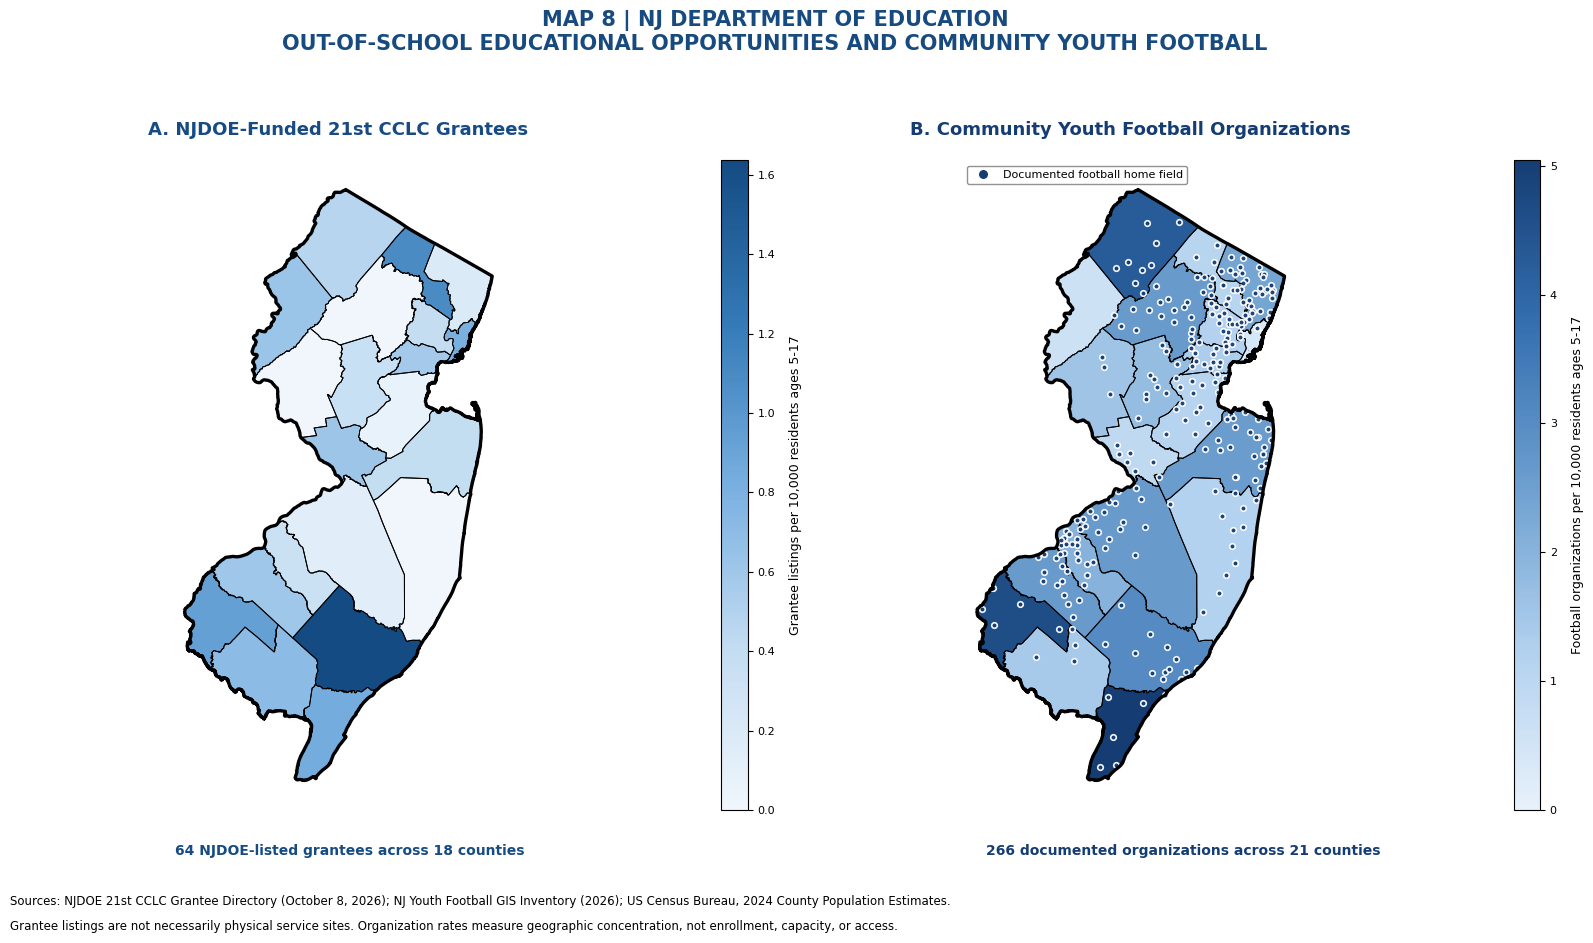

Map 8 generated successfully.
New Jersey counties: 21
NJDOE CCLC grantee listings: 64
Counties with CCLC grantees: 18
Football locations: 266

Highest CCLC grantee rate:
Atlantic 1.64

Highest football organization rate:
Cape May 5.04


In [64]:

# ==========================================================
# PS4 - MAP 8
# NJ DEPARTMENT OF EDUCATION
# 21st CCLC AND COMMUNITY YOUTH FOOTBALL
# TWO SIDE-BY-SIDE BLUE GIS MAPS
# ==========================================================

import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.lines import Line2D

# ----------------------------------------------------------
# STEP 1 - Prepare geographic data
# ----------------------------------------------------------

m8 = gpd.GeoDataFrame(
    map8_counties.copy(),
    geometry="geometry",
    crs=map5_counties.crs
).to_crs(epsg=26918)

# Reuse documented football home-field locations
football_locations = football_by_county.to_crs(m8.crs)

# Create NJ state outline
nj_outline = m8[["geometry"]].dissolve()

# Validate data before mapping
assert len(m8) == 21
assert len(football_locations) == 266
assert m8["CCLC_Grantees"].sum() == 64
assert m8["Organizations"].sum() == 266
assert (m8["CCLC_Grantees"] > 0).sum() == 18

assert m8[
    ["CCLC_Per_10000_Youth", "Football_Per_10000_Youth"]
].notna().all().all()

# ----------------------------------------------------------
# STEP 2 - NJDOE blue color palettes
# ----------------------------------------------------------

cclc_colors = LinearSegmentedColormap.from_list(
    "NJDOE_CCLC_Blue",
    [
        "#F0F6FC",
        "#C2DCF1",
        "#78AFE0",
        "#347AB7",
        "#144B83"
    ]
)

football_colors = LinearSegmentedColormap.from_list(
    "NJDOE_Football_Blue",
    [
        "#E8F1FB",
        "#B0D0EE",
        "#6D9FCF",
        "#346FB0",
        "#153D73"
    ]
)

cclc_max = m8["CCLC_Per_10000_Youth"].max()
football_max = m8["Football_Per_10000_Youth"].max()

# ----------------------------------------------------------
# STEP 3 - Create two side-by-side maps
# ----------------------------------------------------------

fig = plt.figure(figsize=(17, 10), facecolor="white")

gs = fig.add_gridspec(
    1, 4,
    width_ratios=[1, 0.04, 1, 0.04],
    left=0.05,
    right=0.95,
    top=0.82,
    bottom=0.17,
    wspace=0.16
)

ax1 = fig.add_subplot(gs[0, 0])
cax1 = fig.add_subplot(gs[0, 1])

ax2 = fig.add_subplot(gs[0, 2])
cax2 = fig.add_subplot(gs[0, 3])

# ----------------------------------------------------------
# MAP A - NJDOE 21st CCLC
# ----------------------------------------------------------

m8.plot(
    column="CCLC_Per_10000_Youth",
    ax=ax1,
    cmap=cclc_colors,
    vmin=0,
    vmax=cclc_max,
    edgecolor="none",
    zorder=1
)

# Black county boundaries
m8.boundary.plot(
    ax=ax1,
    color="black",
    linewidth=0.7,
    zorder=2
)

# Thick black New Jersey outline
nj_outline.boundary.plot(
    ax=ax1,
    color="black",
    linewidth=2.4,
    zorder=3
)

ax1.set_title(
    "A. NJDOE-Funded 21st CCLC Grantees",
    fontsize=13,
    fontweight="bold",
    color="#164B83",
    pad=18
)

ax1.set_axis_off()
ax1.set_aspect("equal")

# Dedicated CCLC colorbar
cclc_scale = ScalarMappable(
    norm=Normalize(vmin=0, vmax=cclc_max),
    cmap=cclc_colors
)

cclc_scale.set_array([])

cb1 = fig.colorbar(
    cclc_scale,
    cax=cax1
)

cb1.set_label(
    "Grantee listings per 10,000 residents ages 5-17",
    fontsize=9,
    labelpad=10
)

cb1.ax.tick_params(labelsize=8)

# ----------------------------------------------------------
# MAP B - COMMUNITY YOUTH FOOTBALL
# ----------------------------------------------------------

m8.plot(
    column="Football_Per_10000_Youth",
    ax=ax2,
    cmap=football_colors,
    vmin=0,
    vmax=football_max,
    edgecolor="none",
    zorder=1
)

# Black county boundaries
m8.boundary.plot(
    ax=ax2,
    color="black",
    linewidth=0.7,
    zorder=2
)

# Football home fields with strong white borders
football_locations.plot(
    ax=ax2,
    color="#153D73",
    edgecolor="white",
    linewidth=1.2,
    markersize=16,
    alpha=0.95,
    zorder=3
)

# Thick black New Jersey state outline
nj_outline.boundary.plot(
    ax=ax2,
    color="black",
    linewidth=2.4,
    zorder=4
)

ax2.set_title(
    "B. Community Youth Football Organizations",
    fontsize=13,
    fontweight="bold",
    color="#153D73",
    pad=18
)

ax2.set_axis_off()
ax2.set_aspect("equal")

# Football location legend
ax2.legend(
    handles=[
        Line2D(
            [0], [0],
            marker="o",
            linestyle="None",
            markerfacecolor="#153D73",
            markeredgecolor="white",
            markeredgewidth=1.5,
            markersize=8,
            label="Documented football home field"
        )
    ],
    loc="upper left",
    fontsize=8,
    frameon=True,
    facecolor="white",
    edgecolor="#777777"
)

# Dedicated football colorbar
football_scale = ScalarMappable(
    norm=Normalize(vmin=0, vmax=football_max),
    cmap=football_colors
)

football_scale.set_array([])

cb2 = fig.colorbar(
    football_scale,
    cax=cax2
)

cb2.set_label(
    "Football organizations per 10,000 residents ages 5-17",
    fontsize=9,
    labelpad=10
)

cb2.ax.tick_params(labelsize=8)

# ----------------------------------------------------------
# STEP 4 - Main title and explanatory notes
# ----------------------------------------------------------

fig.suptitle(
    "MAP 8 | NJ DEPARTMENT OF EDUCATION\n"
    "OUT-OF-SCHOOL EDUCATIONAL OPPORTUNITIES "
    "AND COMMUNITY YOUTH FOOTBALL",
    fontsize=15,
    fontweight="bold",
    color="#174B80",
    y=0.97
)

# Statewide summary beneath each panel
fig.text(
    0.25,
    0.125,
    "64 NJDOE-listed grantees across 18 counties",
    ha="center",
    fontsize=10,
    fontweight="bold",
    color="#164B83"
)

fig.text(
    0.74,
    0.125,
    "266 documented organizations across 21 counties",
    ha="center",
    fontsize=10,
    fontweight="bold",
    color="#153D73"
)

fig.text(
    0.05,
    0.075,
    "Sources: NJDOE 21st CCLC Grantee Directory "
    "(October 8, 2026); NJ Youth Football GIS Inventory "
    "(2026); US Census Bureau, 2024 County Population "
    "Estimates.",
    fontsize=8.5
)

fig.text(
    0.05,
    0.050,
    "Grantee listings are not necessarily physical service "
    "sites. Organization rates measure geographic "
    "concentration, not enrollment, capacity, or access.",
    fontsize=8.5
)

# ----------------------------------------------------------
# STEP 5 - Export high-resolution maps
# ----------------------------------------------------------

plt.savefig(
    "PS4_Map8_NJDOE_CCLC_vs_Youth_Football_Blue.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.savefig(
    "PS4_Map8_NJDOE_CCLC_vs_Youth_Football_Blue.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# ----------------------------------------------------------
# STEP 6 - Verify results
# ----------------------------------------------------------

print("Map 8 generated successfully.")
print("New Jersey counties:", len(m8))
print("NJDOE CCLC grantee listings:",
      int(m8["CCLC_Grantees"].sum()))
print("Counties with CCLC grantees:",
      int((m8["CCLC_Grantees"] > 0).sum()))
print("Football locations:", len(football_locations))

print("\nHighest CCLC grantee rate:")
top_cclc = m8.sort_values(
    "CCLC_Per_10000_Youth",
    ascending=False
).iloc[0]

print(
    top_cclc["COUNTY"],
    round(top_cclc["CCLC_Per_10000_Youth"], 2)
)

print("\nHighest football organization rate:")
top_football = m8.sort_values(
    "Football_Per_10000_Youth",
    ascending=False
).iloc[0]

print(
    top_football["COUNTY"],
    round(top_football["Football_Per_10000_Youth"], 2)
)


### Map 8 Interpretation — Out-of-School Educational Opportunities and Community Youth Football

Map 8 examines the geographic distribution of New Jersey Department of Education-funded 21st Century Community Learning Centers (21st CCLC) and documented community youth-football organizations across New Jersey's 21 counties.

The analysis identifies 64 NJDOE-listed CCLC grantees distributed across 18 counties and 266 documented youth-football organizations operating across all 21 counties. Both geographic distributions were adjusted using the 2024 county population estimates for residents ages 5–17.

Atlantic County has the highest population-adjusted CCLC grantee rate, with 1.64 listings per 10,000 school-age residents. Cape May County has the highest youth-football organization rate, with 5.04 organizations per 10,000 school-age residents.

The geographic comparison reveals different distribution patterns. Burlington County has 0.14 CCLC grantee listings and 2.64 football organizations per 10,000 school-age residents. Hudson County has 0.81 CCLC grantee listings and 0.41 football organizations per 10,000 school-age residents. Morris County has no listed CCLC grantees in the October 2026 directory but has 21 documented youth-football organizations.

These findings demonstrate that NJDOE-funded out-of-school-time programming and community youth-football organizations have different geographic footprints. However, grantee listings and football organizations represent different service models and should not be interpreted as equivalent measures of program participation, capacity, or educational access.

### Public Administration and NJYASA Implications

The 21st CCLC program provides an established framework for academic enrichment, youth development, physical activity, and family engagement outside regular school hours.

NJYASA's proposed statewide structure of 21 County Conferences and three Regional Councils could potentially facilitate communication between participating youth-sports organizations, local school districts, and community educational programs.

For example, Burlington County's 19 documented youth-football organizations represent an existing network of community organizations that could be examined for possible connections to educational resources and opportunities.

The findings suggest that county-level coordination may provide a useful framework for identifying potential relationships between existing community sports organizations and educational service providers.

However, geographic distribution alone does not establish existing partnerships, unmet educational needs, or the administrative feasibility of NJYASA's proposed coordination model.

### Research Limitations

The NJDOE directory identifies funded CCLC grantee listings rather than all physical service locations. Individual grantees may operate multiple program sites or serve students from several communities.

The analysis does not measure CCLC enrollment, program capacity, participation frequency, funding per student, or educational outcomes.

The youth-football inventory identifies documented organizations and their home-field locations but does not contain verified athlete enrollment, educational participation, or family demographic information.

The datasets also represent different reporting periods: the NJDOE directory was updated October 8, 2026; the youth-football inventory represents 2026; and the population estimates represent 2024.

Counties without listed CCLC grantees should not be interpreted as having no afterschool programs or educational support resources.

Further research involving local school districts, CCLC administrators, and community youth-sports organizations would be necessary to determine whether meaningful collaboration opportunities exist.

## Map 9 — New Jersey Department of Health: Emergency Medical Response, Trauma Care, and Local Public Health Coordination

### Research Question

How do emergency medical response times, designated trauma-center locations, and local public-health jurisdictions relate geographically to New Jersey's 266 documented community youth-football organizations, and what potential opportunities do these patterns suggest for improving emergency preparedness and public-health coordination?

### Research Purpose

This analysis examines two components of New Jersey's emergency medical and public-health infrastructure.

**Map A — Emergency Medical Response and Trauma Care**

This map compares published county-level EMS response-time statistics with the locations of New Jersey's designated Level I and Level II trauma centers and documented community youth-football home fields.

The analysis will also examine straight-line geographic proximity between football home fields and designated trauma centers.

**Map B — Local Public Health Coordination**

This map examines the geographic service jurisdictions of New Jersey's local health departments and the distribution of documented youth-football organizations within those jurisdictions.

Together, the maps examine emergency-care geography and potential opportunities for communication between community youth-sports organizations and existing public-health institutions.

### Public Administration and NJYASA Relevance

NJYASA proposes a voluntary statewide framework consisting of 21 County Conferences and three Regional Councils.

These organizational structures could potentially support communication among participating youth-sports organizations, qualified medical professionals, local health departments, and emergency-preparedness partners.

Potential areas of future coordination include emergency-action planning, CPR/AED education, coach safety training, medical referral awareness, and youth-specific emergency preparedness.

### Data and Methodological Considerations

County EMS response-time statistics summarize reported emergency responses across the general population; they are not estimates of ambulance arrival times at individual football fields.

The EMS statistics reported for June 2025–June 2026 are derived from NJDOH information published in a July 2026 news analysis. They must not be confused with the 90th-percentile response times presented in the 2025 New Jersey Strategic Highway Safety Plan.

Designated trauma-center proximity will be measured using straight-line distance, not driving distance, ambulance response time, or actual patient transport destinations.

Local health departments do not necessarily share the same boundaries as counties or municipalities. Their service jurisdictions will be examined using NJDOH directory information and municipal GIS boundaries.

Geographic associations do not establish that any youth-football facility is unsafe, that EMS services are inadequate, or that NJYASA has existing partnerships with the agencies represented.

### Data Sources

- New Jersey Department of Health — Office of Emergency Medical Services.
- NJ.com — July 26, 2026 county EMS response-time analysis based on NJDOH data.
- New Jersey Department of Health — Designated Trauma Centers.
- New Jersey Department of Health — Local Health Department Directory.
- New Jersey Office of GIS — Municipal Boundaries.
- NJ Youth Football GIS Inventory — 2026.

https://www.nj.gov/health/ems/data_resources/dashboards/

https://www.nj.gov/health/ems/documents/NJ%20Trauma%20Centers.pdf

https://www.nj.gov/health/lh/community/

https://www.ems1.com/response-times/9-n-j-counties-exceed-states-recommended-ems-response-times

In [65]:

# ==========================================================
# PS4 - MAP 9 - PART 1
# NJ DEPARTMENT OF HEALTH
# EMS RESPONSE AND TRAUMA CENTER DATA
# ==========================================================

import pandas as pd
import geopandas as gpd
from IPython.display import display

# ----------------------------------------------------------
# 1. REPORTED COUNTY EMS RESPONSE-TIME STATISTICS
# ----------------------------------------------------------

# Source: NJ.com, July 26, 2026.
# Derived from NJDOH data for June 2025 - June 2026.
#
# These are reported county averages of monthly values.
# They are NOT 90th-percentile response times.
# Values retain the precision published by the source.
# They do not predict ambulance arrival at football fields.

ems_minutes = {
    "Atlantic": 12.00,
    "Bergen": 15.00,
    "Burlington": 15.00,
    "Camden": 12.00,
    "Cape May": 13.00,
    "Cumberland": 14.00,
    "Essex": 13.00,
    "Gloucester": 13.47,
    "Hudson": 13.00,
    "Hunterdon": 18.10,
    "Mercer": 13.59,
    "Middlesex": 14.00,
    "Monmouth": 17.00,
    "Morris": 16.00,
    "Ocean": 16.10,
    "Passaic": 17.00,
    "Salem": 18.33,
    "Somerset": 18.00,
    "Sussex": 20.00,
    "Union": 13.00,
    "Warren": 22.00
}

map9_ems = pd.DataFrame([
    {
        "COUNTY": county,
        "EMS_Reported_Mean_Minutes": minutes,
        "Reporting_Period": "June 2025 - June 2026",
        "Metric": "Reported county monthly-average EMS response time"
    }
    for county, minutes in ems_minutes.items()
])

# ----------------------------------------------------------
# 2. JOIN TO EXISTING NJ COUNTY GIS DATA
# ----------------------------------------------------------

map9_counties = (
    map8_counties[
        ["COUNTY", "Organizations", "geometry"]
    ]
    .copy()
    .merge(
        map9_ems,
        on="COUNTY",
        how="left",
        validate="one_to_one"
    )
)

map9_counties = gpd.GeoDataFrame(
    map9_counties,
    geometry="geometry",
    crs=map8_counties.crs
)

# Validation
assert len(map9_ems) == 21
assert len(map9_counties) == 21
assert map9_counties["COUNTY"].is_unique
assert map9_counties["EMS_Reported_Mean_Minutes"].notna().all()
assert map9_counties["Organizations"].sum() == 266
assert len(football_by_county) == 266

print("MAP 9 - EMS DATA VALIDATION")
print("----------------------------")
print("Counties:", len(map9_counties))
print(
    "Football organizations:",
    int(map9_counties["Organizations"].sum())
)
print(
    "Lowest reported response time:",
    map9_counties["EMS_Reported_Mean_Minutes"].min(),
    "minutes"
)
print(
    "Highest reported response time:",
    map9_counties["EMS_Reported_Mean_Minutes"].max(),
    "minutes"
)

display(
    map9_counties[
        ["COUNTY", "EMS_Reported_Mean_Minutes", "Organizations"]
    ]
    .sort_values(
        "EMS_Reported_Mean_Minutes",
        ascending=False
    )
    .reset_index(drop=True)
)

# ----------------------------------------------------------
# 3. OFFICIAL NJDOH TRAUMA CENTER INVENTORY
# ----------------------------------------------------------

# Source: NJDOH New Jersey Trauma Centers directory.
# Street addresses are used without potentially erroneous
# ZIP codes in the source PDF. Locations will be verified
# against official GIS hospital points in the next stage.

trauma_records = [
    ("Atlantic", "AtlantiCare Regional Medical Center - City Campus",
     "II", "1925 Pacific Avenue", "Atlantic City"),

    ("Bergen", "Hackensack University Medical Center",
     "II", "30 Prospect Avenue", "Hackensack"),

    ("Camden", "Cooper University Hospital",
     "I", "1 Cooper Plaza", "Camden"),

    ("Essex", "University Hospital",
     "I", "150 Bergen Street", "Newark"),

    ("Hudson", "Jersey City Medical Center",
     "II", "355 Grand Street", "Jersey City"),

    ("Mercer", "Capital Health Regional Medical Center",
     "II", "750 Brunswick Avenue", "Trenton"),

    ("Middlesex", "Robert Wood Johnson University Hospital",
     "I", "1 Robert Wood Johnson Place", "New Brunswick"),

    ("Monmouth", "Jersey Shore University Medical Center",
     "II", "1945 Route 33", "Neptune"),

    ("Morris", "Morristown Medical Center",
     "II", "100 Madison Avenue", "Morristown"),

    ("Passaic", "St. Joseph's University Medical Center",
     "II", "703 Main Street", "Paterson")
]

trauma_centers = pd.DataFrame(
    trauma_records,
    columns=[
        "COUNTY",
        "Facility",
        "Trauma_Level",
        "Street",
        "City"
    ]
)

trauma_centers["Address"] = (
    trauma_centers["Street"]
    + ", "
    + trauma_centers["City"]
    + ", New Jersey, USA"
)

assert len(trauma_centers) == 10
assert (trauma_centers["Trauma_Level"] == "I").sum() == 3
assert (trauma_centers["Trauma_Level"] == "II").sum() == 7

print("\nMAP 9 - TRAUMA CENTER VALIDATION")
print("--------------------------------")
print("Total trauma centers:", len(trauma_centers))
print("Level I:", (trauma_centers["Trauma_Level"] == "I").sum())
print("Level II:", (trauma_centers["Trauma_Level"] == "II").sum())

display(
    trauma_centers[
        ["COUNTY", "Facility", "Trauma_Level", "Address"]
    ]
)

# ----------------------------------------------------------
# 4. SAVE SOURCE TABLES
# ----------------------------------------------------------

map9_ems.to_csv(
    "PS4_Map9_NJDOH_EMS_County_Statistics.csv",
    index=False
)

trauma_centers.to_csv(
    "PS4_Map9_NJDOH_Trauma_Centers.csv",
    index=False
)

print("\nMap 9 Part 1 data preparation completed successfully.")


MAP 9 - EMS DATA VALIDATION
----------------------------
Counties: 21
Football organizations: 266
Lowest reported response time: 12.0 minutes
Highest reported response time: 22.0 minutes


,COUNTY,EMS_Reported_Mean_Minutes,Organizations
0,Warren,22.00,1
1,Sussex,20.00,9
2,Salem,18.33,5
3,Hunterdon,18.10,3
4,Somerset,18.00,10
5,Passaic,17.00,10
6,Monmouth,17.00,26
7,Ocean,16.10,14
8,Morris,16.00,21
9,Bergen,15.00,36



MAP 9 - TRAUMA CENTER VALIDATION
--------------------------------
Total trauma centers: 10
Level I: 3
Level II: 7


,COUNTY,Facility,Trauma_Level,Address
0,Atlantic,AtlantiCare Regional Medical Center - City Campus,II,"1925 Pacific Avenue, Atlantic City, New Jersey..."
1,Bergen,Hackensack University Medical Center,II,"30 Prospect Avenue, Hackensack, New Jersey, USA"
2,Camden,Cooper University Hospital,I,"1 Cooper Plaza, Camden, New Jersey, USA"
3,Essex,University Hospital,I,"150 Bergen Street, Newark, New Jersey, USA"
4,Hudson,Jersey City Medical Center,II,"355 Grand Street, Jersey City, New Jersey, USA"
5,Mercer,Capital Health Regional Medical Center,II,"750 Brunswick Avenue, Trenton, New Jersey, USA"
6,Middlesex,Robert Wood Johnson University Hospital,I,"1 Robert Wood Johnson Place, New Brunswick, Ne..."
7,Monmouth,Jersey Shore University Medical Center,II,"1945 Route 33, Neptune, New Jersey, USA"
8,Morris,Morristown Medical Center,II,"100 Madison Avenue, Morristown, New Jersey, USA"
9,Passaic,St. Joseph's University Medical Center,II,"703 Main Street, Paterson, New Jersey, USA"



Map 9 Part 1 data preparation completed successfully.


In [66]:

# ==========================================================
# PS4 - MAP 9 - PART 2
# NJDOH LOCAL HEALTH DEPARTMENT DIRECTORY
# INITIAL SOURCE VERIFICATION
# ==========================================================

import requests
import io
import pdfplumber

LHD_DIRECTORY_URL = (
    "https://nj.gov/health/lh/documents/"
    "LocalHealthDirectory.pdf"
)

response = requests.get(
    LHD_DIRECTORY_URL,
    headers={"User-Agent": "Mozilla/5.0"},
    timeout=60
)

response.raise_for_status()

assert response.content[:4] == b"%PDF", (
    "The downloaded response is not a PDF."
)

with pdfplumber.open(io.BytesIO(response.content)) as pdf:

    directory_page_count = len(pdf.pages)
    cover_text = pdf.pages[0].extract_text() or ""

    print("MAP 9 - LOCAL HEALTH DIRECTORY")
    print("--------------------------------")
    print("Source:", LHD_DIRECTORY_URL)
    print("PDF pages:", directory_page_count)

    print("\nFirst lines of the current directory:")
    for line in cover_text.splitlines()[:8]:
        print(line)

    assert directory_page_count >= 90, (
        "Directory has fewer pages than expected."
    )

print("\nDirectory downloaded and opened successfully.")
print(
    "Next: extract and verify municipality-to-health-"
    "department assignments."
)


MAP 9 - LOCAL HEALTH DIRECTORY
--------------------------------
Source: https://nj.gov/health/lh/documents/LocalHealthDirectory.pdf
PDF pages: 104

First lines of the current directory:
DDirectory of
LOCAL HEALTH DEPARTMENTS
in
New Jersey
10/05/2026
Atlantic
Atlantic City Department of Health & Human Services
City Hall - Suite 409

Directory downloaded and opened successfully.
Next: extract and verify municipality-to-health-department assignments.


In [67]:

# ==========================================================
# PS4 - MAP 9 - PART 3
# OFFICIAL NJ MUNICIPAL BOUNDARIES
# AND YOUTH FOOTBALL HOME-FIELD ASSIGNMENTS
# ==========================================================

import requests
import pandas as pd
import geopandas as gpd
from IPython.display import display

# ----------------------------------------------------------
# 1. Download official NJ municipal boundaries
# ----------------------------------------------------------

MUNICIPAL_URL = (
    "https://services2.arcgis.com/"
    "EfgKMXWYhNQe0H3M/ArcGIS/rest/services/"
    "NJ_Municipal_Boundaries/FeatureServer/0/query"
)

params = {
    "where": "1=1",
    "outFields": "NAME,COUNTY,MUN_CODE",
    "returnGeometry": "true",
    "outSR": "4326",
    "f": "geojson"
}

result = requests.get(
    MUNICIPAL_URL,
    params=params,
    timeout=120
)

result.raise_for_status()
data = result.json()

if "features" not in data:
    raise ValueError(
        "Municipal GIS response did not contain features: "
        + str(data)[:500]
    )

nj_municipalities = gpd.GeoDataFrame.from_features(
    data["features"],
    crs="EPSG:4326"
)

# ----------------------------------------------------------
# 2. Verify municipality records
# ----------------------------------------------------------

print("MAP 9 - NJ MUNICIPAL GIS VALIDATION")
print("-----------------------------------")
print("Municipal polygons:", len(nj_municipalities))
print("Unique municipality codes:",
      nj_municipalities["MUN_CODE"].nunique())
print("Missing geometry:",
      nj_municipalities.geometry.isna().sum())

if len(nj_municipalities) != 564:
    print("WARNING: Municipality count requires review.")

display(
    nj_municipalities[
        ["NAME", "COUNTY", "MUN_CODE"]
    ].head(10)
)

# ----------------------------------------------------------
# 3. Assign football home fields to municipalities
# ----------------------------------------------------------

football_m9 = (
    football_by_county
    .to_crs(epsg=4326)
    .copy()
    .reset_index(drop=True)
)

football_m9["Football_ID"] = (
    football_m9.index + 1
)

football_municipality_matches = gpd.sjoin(
    football_m9[["Football_ID", "geometry"]],
    nj_municipalities[
        ["NAME", "COUNTY", "MUN_CODE", "geometry"]
    ],
    how="left",
    predicate="intersects"
)

# ----------------------------------------------------------
# 4. Check for missing or ambiguous assignments
# ----------------------------------------------------------

matched = football_municipality_matches[
    football_municipality_matches["NAME"].notna()
]

matched_ids = matched["Football_ID"].nunique()

unmatched_ids = (
    266 - matched_ids
)

duplicate_ids = (
    matched.groupby("Football_ID")
    .size()
    .loc[lambda x: x > 1]
)

print("\nFOOTBALL HOME-FIELD VALIDATION")
print("--------------------------------")
print("Original football records:", len(football_m9))
print("Matched football records:", matched_ids)
print("Unmatched records:", unmatched_ids)
print("Records matching multiple municipalities:",
      len(duplicate_ids))

print("\nTOP MUNICIPALITIES BY DOCUMENTED HOME FIELDS")

display(
    matched.groupby(
        ["COUNTY", "NAME"]
    )["Football_ID"]
    .nunique()
    .sort_values(ascending=False)
    .head(15)
    .reset_index(name="Organizations")
)

# ----------------------------------------------------------
# 5. Export matches for further validation
# ----------------------------------------------------------

football_municipality_matches.drop(
    columns=["geometry", "index_right"],
    errors="ignore"
).to_csv(
    "PS4_Map9_Football_Municipality_Matches.csv",
    index=False
)

print("\nMap 9 municipal assignment check completed.")
print("Next step: Match municipalities to NJDOH")
print("local health department service jurisdictions.")


MAP 9 - NJ MUNICIPAL GIS VALIDATION
-----------------------------------
Municipal polygons: 563
Unique municipality codes: 563
Missing geometry: 0


,NAME,COUNTY,MUN_CODE
0,Cape May Point Borough,CAPE MAY,0503
1,West Cape May Borough,CAPE MAY,0512
2,Cape May,CAPE MAY,0502
3,Wildwood Crest Borough,CAPE MAY,0515
4,West Wildwood Borough,CAPE MAY,0513
5,North Wildwood,CAPE MAY,0507
6,Lower Township,CAPE MAY,0505
7,Stone Harbor Borough,CAPE MAY,0510
8,Avalon Borough,CAPE MAY,0501
9,Middle Township,CAPE MAY,0506



FOOTBALL HOME-FIELD VALIDATION
--------------------------------
Original football records: 266
Matched football records: 266
Unmatched records: 0
Records matching multiple municipalities: 0

TOP MUNICIPALITIES BY DOCUMENTED HOME FIELDS


,COUNTY,NAME,Organizations
0,ESSEX,Newark,4
1,CAMDEN,Camden,4
2,ESSEX,Fairfield Township,2
3,CUMBERLAND,Vineland,2
4,PASSAIC,Wayne Township,2
5,SOMERSET,Hillsborough Township,2
6,SUSSEX,Sparta Township,2
7,MONMOUTH,Howell Township,2
8,MONMOUTH,Ocean Township,2
9,MONMOUTH,Middletown Township,2



Map 9 municipal assignment check completed.
Next step: Match municipalities to NJDOH
local health department service jurisdictions.


In [68]:

# ==========================================================
# PS4 - MAP 9 - PART 4
# AUDIT NEW JERSEY MUNICIPAL BOUNDARY COVERAGE
# ==========================================================

import requests
import pandas as pd
from IPython.display import display

# ----------------------------------------------------------
# 1. Download reference municipality attributes
# ----------------------------------------------------------

REFERENCE_URL = (
    "https://maps.nj.gov/arcgis/rest/services/"
    "Framework/Government_Boundaries/MapServer/2/query"
)

params = {
    "where": "1=1",
    "outFields": "MUN_CODE,NAME,COUNTY",
    "returnGeometry": "false",
    "resultRecordCount": 1000,
    "f": "json"
}

r = requests.get(
    REFERENCE_URL,
    params=params,
    timeout=90
)

r.raise_for_status()

reference_json = r.json()

if "error" in reference_json:
    raise RuntimeError(reference_json["error"])

if reference_json.get("exceededTransferLimit"):
    raise RuntimeError(
        "Reference service did not return every municipality."
    )

reference_municipalities = pd.DataFrame(
    [
        feature["attributes"]
        for feature in reference_json["features"]
    ]
)

# ----------------------------------------------------------
# 2. Standardize municipality identifiers
# ----------------------------------------------------------

def normalize_mun_code(series):
    return (
        series.astype("string")
        .str.strip()
        .str.replace(r"\.0$", "", regex=True)
        .str.zfill(4)
    )

reference_municipalities["CODE"] = normalize_mun_code(
    reference_municipalities["MUN_CODE"]
)

working_municipalities = nj_municipalities[
    ["NAME", "COUNTY", "MUN_CODE"]
].copy()

working_municipalities["CODE"] = normalize_mun_code(
    working_municipalities["MUN_CODE"]
)

# ----------------------------------------------------------
# 3. Compare records
# ----------------------------------------------------------

reference_codes = set(
    reference_municipalities["CODE"].dropna()
)

working_codes = set(
    working_municipalities["CODE"].dropna()
)

missing_codes = reference_codes - working_codes
additional_codes = working_codes - reference_codes

missing_from_working = reference_municipalities[
    reference_municipalities["CODE"].isin(missing_codes)
]

additional_to_reference = working_municipalities[
    working_municipalities["CODE"].isin(additional_codes)
]

# ----------------------------------------------------------
# 4. Display validation results
# ----------------------------------------------------------

print("MAP 9 - MUNICIPAL BOUNDARY CROSS-CHECK")
print("--------------------------------------")

print(
    "Current working GIS polygons:",
    len(nj_municipalities)
)

print(
    "Official reference GIS records:",
    len(reference_municipalities)
)

print(
    "Unique working municipality codes:",
    len(working_codes)
)

print(
    "Unique reference municipality codes:",
    len(reference_codes)
)

print(
    "In reference but missing from working layer:",
    len(missing_codes)
)

print(
    "In working layer but absent from reference:",
    len(additional_codes)
)

print("\nMUNICIPALITIES TO INVESTIGATE:")
display(
    missing_from_working[
        ["COUNTY", "NAME", "MUN_CODE"]
    ]
)

print("\nADDITIONAL WORKING-LAYER RECORDS:")
display(
    additional_to_reference[
        ["COUNTY", "NAME", "MUN_CODE"]
    ]
)

print("\nCross-check completed.")
print("No municipal geometry has been altered.")


MAP 9 - MUNICIPAL BOUNDARY CROSS-CHECK
--------------------------------------
Current working GIS polygons: 563
Official reference GIS records: 564
Unique working municipality codes: 563
Unique reference municipality codes: 564
In reference but missing from working layer: 1
In working layer but absent from reference: 0

MUNICIPALITIES TO INVESTIGATE:


,COUNTY,NAME,MUN_CODE
343,BERGEN,Hackensack,0223



ADDITIONAL WORKING-LAYER RECORDS:


,COUNTY,NAME,MUN_CODE



Cross-check completed.
No municipal geometry has been altered.


In [69]:

# ==========================================================
# PS4 - MAP 9 - PART 5
# RESTORE COMPLETE NJ MUNICIPAL GEOGRAPHY
# AND REVALIDATE ALL FOOTBALL HOME FIELDS
# ==========================================================

import requests
import pandas as pd
import geopandas as gpd
from IPython.display import display

# ----------------------------------------------------------
# 1. Download the complete official NJ GIS layer
# ----------------------------------------------------------

MUNICIPAL_REFERENCE_URL = (
    "https://maps.nj.gov/arcgis/rest/services/"
    "Framework/Government_Boundaries/MapServer/2/query"
)

params = {
    "where": "1=1",
    "outFields": "NAME,COUNTY,MUN_CODE",
    "returnGeometry": "true",
    "outSR": "4326",
    "resultRecordCount": 1000,
    "f": "geojson"
}

response = requests.get(
    MUNICIPAL_REFERENCE_URL,
    params=params,
    timeout=120
)

response.raise_for_status()
municipal_data = response.json()

if "error" in municipal_data:
    raise RuntimeError(municipal_data["error"])

if "features" not in municipal_data:
    raise ValueError(
        "The NJ GIS service did not return GeoJSON features."
    )

# ----------------------------------------------------------
# 2. Create the corrected municipal GeoDataFrame
# ----------------------------------------------------------

map9_municipalities = gpd.GeoDataFrame.from_features(
    municipal_data["features"],
    crs="EPSG:4326"
)

map9_municipalities["MUN_CODE"] = (
    map9_municipalities["MUN_CODE"]
    .astype("string")
    .str.strip()
    .str.zfill(4)
)

# ----------------------------------------------------------
# 3. Validate all municipal polygons
# ----------------------------------------------------------

assert len(map9_municipalities) == 564, (
    "Expected 564 municipality records."
)

assert map9_municipalities["MUN_CODE"].nunique() == 564

assert map9_municipalities.geometry.notna().all()

assert (
    ~map9_municipalities.geometry.is_empty
).all()

assert map9_municipalities["COUNTY"].nunique() == 21

# Confirm the previously missing municipality
hackensack = map9_municipalities[
    map9_municipalities["MUN_CODE"] == "0223"
]

assert len(hackensack) == 1
assert hackensack.iloc[0]["COUNTY"] == "BERGEN"

print("MAP 9 - COMPLETE MUNICIPAL GIS VALIDATION")
print("-----------------------------------------")
print("Municipalities:", len(map9_municipalities))
print(
    "Unique codes:",
    map9_municipalities["MUN_CODE"].nunique()
)
print(
    "Counties:",
    map9_municipalities["COUNTY"].nunique()
)
print(
    "Missing geometries:",
    map9_municipalities.geometry.isna().sum()
)

print("\nPREVIOUSLY MISSING MUNICIPALITY")
display(
    hackensack[["COUNTY", "NAME", "MUN_CODE"]]
)

# ----------------------------------------------------------
# 4. Reassign all 266 football home-field locations
# ----------------------------------------------------------

map9_football_points = (
    football_by_county
    .to_crs(map9_municipalities.crs)
    .copy()
    .reset_index(drop=True)
)

map9_football_points["Football_ID"] = (
    map9_football_points.index + 1
)

map9_football_municipalities = gpd.sjoin(
    map9_football_points[
        ["Football_ID", "geometry"]
    ],
    map9_municipalities[
        ["NAME", "COUNTY", "MUN_CODE", "geometry"]
    ],
    how="left",
    predicate="intersects"
)

# ----------------------------------------------------------
# 5. Check spatial matches
# ----------------------------------------------------------

matched_ids = (
    map9_football_municipalities
    .loc[
        map9_football_municipalities["MUN_CODE"].notna(),
        "Football_ID"
    ]
    .nunique()
)

unmatched_ids = (
    len(map9_football_points) - matched_ids
)

matching_counts = (
    map9_football_municipalities
    .groupby("Football_ID")
    .size()
)

multiple_matches = (
    matching_counts[matching_counts > 1]
)

print("\nFOOTBALL MUNICIPAL ASSIGNMENT VALIDATION")
print("----------------------------------------")
print("Original football records:",
      len(map9_football_points))
print("Matched records:", matched_ids)
print("Unmatched records:", unmatched_ids)
print(
    "Records matching multiple municipalities:",
    len(multiple_matches)
)

# Stop if any assignments require review
assert len(map9_football_points) == 266
assert unmatched_ids == 0, (
    "Some football fields lack municipal assignments."
)
assert len(multiple_matches) == 0, (
    "Some football fields intersect multiple municipalities."
)

# ----------------------------------------------------------
# 6. Calculate municipality-level football counts
# ----------------------------------------------------------

map9_municipal_football_counts = (
    map9_football_municipalities
    .groupby(["MUN_CODE", "COUNTY", "NAME"])
    .agg(
        Organizations=("Football_ID", "nunique")
    )
    .reset_index()
)

print("\nMUNICIPALITIES WITH THE MOST HOME FIELDS")

display(
    map9_municipal_football_counts
    .sort_values(
        "Organizations",
        ascending=False
    )
    .head(15)
)

print("\nHackensack football home-field matches:")

display(
    map9_football_municipalities[
        map9_football_municipalities["MUN_CODE"] == "0223"
    ][["Football_ID", "COUNTY", "NAME"]]
)

# ----------------------------------------------------------
# 7. Save the validated datasets
# ----------------------------------------------------------

map9_municipalities.to_file(
    "PS4_Map9_NJ_Municipalities_564.gpkg",
    driver="GPKG"
)

map9_football_municipalities.drop(
    columns=["geometry", "index_right"],
    errors="ignore"
).to_csv(
    "PS4_Map9_Validated_Football_Municipalities.csv",
    index=False
)

print("\nMAP 9 - PART 5 COMPLETED")
print("Complete municipal geography established.")
print("Football municipality assignments revalidated.")
print("Ready for NJDOH jurisdiction matching.")


MAP 9 - COMPLETE MUNICIPAL GIS VALIDATION
-----------------------------------------
Municipalities: 564
Unique codes: 564
Counties: 21
Missing geometries: 0

PREVIOUSLY MISSING MUNICIPALITY


,COUNTY,NAME,MUN_CODE
343,BERGEN,Hackensack,0223



FOOTBALL MUNICIPAL ASSIGNMENT VALIDATION
----------------------------------------
Original football records: 266
Matched records: 266
Unmatched records: 0
Records matching multiple municipalities: 0

MUNICIPALITIES WITH THE MOST HOME FIELDS


,MUN_CODE,COUNTY,NAME,Organizations
100,0714,ESSEX,Newark,4
69,0408,CAMDEN,Camden,4
96,0707,ESSEX,Fairfield Township,2
91,0614,CUMBERLAND,Vineland,2
211,1614,PASSAIC,Wayne Township,2
222,1810,SOMERSET,Hillsborough Township,2
232,1918,SUSSEX,Sparta Township,2
155,1321,MONMOUTH,Howell Township,2
165,1337,MONMOUTH,Ocean Township,2
163,1332,MONMOUTH,Middletown Township,2



Hackensack football home-field matches:


,Football_ID,COUNTY,NAME



MAP 9 - PART 5 COMPLETED
Complete municipal geography established.
Football municipality assignments revalidated.
Ready for NJDOH jurisdiction matching.


In [70]:

# ==========================================================
# PS4 - MAP 9 - PART 6
# NJDOH LOCAL HEALTH DEPARTMENT JURISDICTIONS
# EXTRACT AND AUDIT THE OCTOBER 2026 DIRECTORY
# ==========================================================

import io
import re
import difflib
import requests
import pdfplumber
import pandas as pd
from collections import defaultdict
from IPython.display import display

# ----------------------------------------------------------
# 1. Download the current official NJDOH directory
# ----------------------------------------------------------

LHD_URL = (
    "https://nj.gov/health/lh/documents/"
    "LocalHealthDirectory.pdf"
)

r = requests.get(
    LHD_URL,
    headers={"User-Agent": "Mozilla/5.0"},
    timeout=90
)

r.raise_for_status()

assert r.content[:4] == b"%PDF", (
    "The downloaded file was not a PDF."
)

# ----------------------------------------------------------
# 2. Extract municipalities from each directory page
# ----------------------------------------------------------

directory_records = []
directory_pages = []

with pdfplumber.open(io.BytesIO(r.content)) as pdf:

    print("NJDOH directory pages:", len(pdf.pages))

    for page_number, page in enumerate(pdf.pages, 1):

        full_text = page.extract_text() or ""
        lines = [
            line.strip()
            for line in full_text.splitlines()
            if line.strip()
        ]

        # One department entry generally begins with
        # the county heading followed by the agency name.
        county_heading = lines[0] if lines else ""

        agency = lines[1] if len(lines) > 1 else ""

        agency = re.sub(
            r"\s+LINCS Agency.*$",
            "",
            agency
        ).strip()

        # Locate the municipality list on this page.
        headings = page.search("Municipalities Served")

        if not headings:
            directory_pages.append({
                "Page": page_number,
                "County_Heading": county_heading,
                "Agency": agency,
                "Extracted_Entries": 0
            })
            continue

        list_top = headings[0]["bottom"] + 4

        # Municipality lists are generally arranged
        # in separate left and right columns.
        # Exclude the page footer at the bottom.
        width = page.width
        bottom = page.height - 55

        columns = {
            "Left": (0.16 * width, 0.59 * width),
            "Right": (0.59 * width, 0.94 * width)
        }

        page_count = 0

        for column_name, (x0, x1) in columns.items():

            area = page.crop(
                (x0, list_top, x1, bottom)
            )

            column_text = area.extract_text(
                x_tolerance=2,
                y_tolerance=3
            ) or ""

            for raw_line in column_text.splitlines():

                municipality = " ".join(
                    raw_line.split()
                ).strip()

                if not municipality:
                    continue

                if re.match(
                    r"^Page\s+\d+$",
                    municipality,
                    flags=re.IGNORECASE
                ):
                    continue

                directory_records.append({
                    "Source_Page": page_number,
                    "Directory_County": county_heading,
                    "Health_Department": agency,
                    "Column": column_name,
                    "Municipality_Raw": municipality
                })

                page_count += 1

        directory_pages.append({
            "Page": page_number,
            "County_Heading": county_heading,
            "Agency": agency,
            "Extracted_Entries": page_count
        })

lhd_raw = pd.DataFrame(directory_records)
lhd_page_audit = pd.DataFrame(directory_pages)

if lhd_raw.empty:
    raise RuntimeError(
        "No municipality entries were extracted. "
        "The PDF layout needs inspection."
    )

# ----------------------------------------------------------
# 3. Normalize names for matching
# ----------------------------------------------------------

def normalize_municipality(value):

    s = str(value).upper().strip()

    # Remove county annotations only from the
    # comparison key. Preserve the original text.
    s = re.sub(r"\([^)]*\)", " ", s)

    s = s.replace("&", " AND ")

    s = re.sub(r"\bTWP\b", "TOWNSHIP", s)
    s = re.sub(r"\bBORO\b", "BOROUGH", s)
    s = re.sub(r"\bMT\b", "MOUNT", s)
    s = re.sub(r"\bPK\b", "PARK", s)

    s = re.sub(
        r"[^A-Z0-9 ]",
        " ",
        s
    )

    s = re.sub(
        r"^(BOROUGH|TOWNSHIP|CITY|VILLAGE) OF ",
        "",
        s
    )

    return " ".join(s.split())


def county_annotation(value):

    text = str(value).upper()

    match = re.search(
        r"\(([A-Z ]+?)\s+CO(?:UNTY)?\.?\)",
        text
    )

    if match:
        return match.group(1).strip()

    return None


# ----------------------------------------------------------
# 4. Create lookup from the verified 564 municipalities
# ----------------------------------------------------------

municipal_reference = map9_municipalities[
    ["MUN_CODE", "COUNTY", "NAME"]
].copy()

municipal_reference["MUN_CODE"] = (
    municipal_reference["MUN_CODE"]
    .astype("string")
    .str.zfill(4)
)

municipal_reference["KEY"] = (
    municipal_reference["NAME"]
    .apply(normalize_municipality)
)

# Include both complete and shortened forms.
# A shortened name is accepted ONLY if unique.
alias_lookup = defaultdict(set)

for _, row in municipal_reference.iterrows():

    full_key = row["KEY"]
    code = row["MUN_CODE"]

    alias_lookup[full_key].add(code)

    short_key = re.sub(
        r" (BOROUGH|TOWNSHIP|CITY|TOWN|VILLAGE)$",
        "",
        full_key
    )

    alias_lookup[short_key].add(code)

code_to_county = dict(
    zip(
        municipal_reference["MUN_CODE"],
        municipal_reference["COUNTY"]
    )
)

code_to_name = dict(
    zip(
        municipal_reference["MUN_CODE"],
        municipal_reference["NAME"]
    )
)

# ----------------------------------------------------------
# 5. Match only unambiguous municipality names
# ----------------------------------------------------------

audit_rows = []

all_aliases = list(alias_lookup.keys())

for _, row in lhd_raw.iterrows():

    raw_name = row["Municipality_Raw"]
    key = normalize_municipality(raw_name)

    candidates = sorted(
        alias_lookup.get(key, set())
    )

    explicit_county = county_annotation(raw_name)

    if explicit_county:
        candidates = [
            code for code in candidates
            if code_to_county[code].upper()
            == explicit_county
        ]

    if len(candidates) == 1:

        status = "MATCHED"
        code = candidates[0]
        matched_name = code_to_name[code]

    elif len(candidates) > 1:

        status = "AMBIGUOUS"
        code = None
        matched_name = ""

    else:

        status = "REVIEW"
        code = None
        matched_name = ""

    suggestions = difflib.get_close_matches(
        key,
        all_aliases,
        n=3,
        cutoff=0.60
    )

    audit_rows.append({
        **row.to_dict(),
        "Status": status,
        "MUN_CODE": code,
        "Matched_Municipality": matched_name,
        "Suggested_Names": " | ".join(suggestions)
    })

lhd_audit = pd.DataFrame(audit_rows)

# ----------------------------------------------------------
# 6. Check coverage and conflicting assignments
# ----------------------------------------------------------

matched = lhd_audit[
    lhd_audit["Status"] == "MATCHED"
].copy()

matched_codes = set(
    matched["MUN_CODE"].dropna()
)

all_codes = set(
    municipal_reference["MUN_CODE"]
)

unassigned_codes = all_codes - matched_codes

missing_municipalities = (
    municipal_reference[
        municipal_reference["MUN_CODE"].isin(
            unassigned_codes
        )
    ]
    .sort_values(["COUNTY", "NAME"])
)

# A municipality appearing under multiple health
# departments needs further investigation.
agency_counts = (
    matched.groupby("MUN_CODE")["Health_Department"]
    .nunique()
)

conflicting_codes = set(
    agency_counts[agency_counts > 1].index
)

conflicts = matched[
    matched["MUN_CODE"].isin(conflicting_codes)
].sort_values(
    ["MUN_CODE", "Health_Department"]
)

review_rows = lhd_audit[
    lhd_audit["Status"] != "MATCHED"
]

# ----------------------------------------------------------
# 7. Display the audit results
# ----------------------------------------------------------

print("\nMAP 9 - NJDOH DIRECTORY EXTRACTION")
print("----------------------------------")

print(
    "Directory pages:",
    len(lhd_page_audit)
)

print(
    "Municipality entries extracted:",
    len(lhd_raw)
)

print(
    "Distinct listed departments:",
    lhd_raw["Health_Department"].nunique()
)

print(
    "Direct unambiguous matches:",
    len(matched)
)

print(
    "Unique municipality codes matched:",
    len(matched_codes)
)

print(
    "Municipalities still unassigned:",
    len(unassigned_codes)
)

print(
    "Source entries requiring review:",
    len(review_rows)
)

print(
    "Municipalities with conflicting departments:",
    len(conflicting_codes)
)

print("\nEXTRACTION EXAMPLES")

display(
    lhd_audit[
        [
            "Source_Page",
            "Health_Department",
            "Municipality_Raw",
            "MUN_CODE",
            "Status"
        ]
    ].head(15)
)

print("\nENTRIES REQUIRING REVIEW")

display(
    review_rows[
        [
            "Directory_County",
            "Health_Department",
            "Municipality_Raw",
            "Status",
            "Suggested_Names"
        ]
    ].head(30)
)

print("\nUNASSIGNED GIS MUNICIPALITIES")

display(
    missing_municipalities[
        ["COUNTY", "NAME", "MUN_CODE"]
    ].head(30)
)

print("\nCONFLICTING HEALTH DEPARTMENT ASSIGNMENTS")

display(
    conflicts[
        [
            "MUN_CODE",
            "Matched_Municipality",
            "Health_Department",
            "Source_Page"
        ]
    ].head(30)
)

# ----------------------------------------------------------
# 8. Save audit files
# ----------------------------------------------------------

lhd_audit.to_csv(
    "PS4_Map9_NJDOH_Directory_Matching_Audit.csv",
    index=False
)

lhd_page_audit.to_csv(
    "PS4_Map9_NJDOH_Directory_Page_Audit.csv",
    index=False
)

missing_municipalities.to_csv(
    "PS4_Map9_NJDOH_Unassigned_Municipalities.csv",
    index=False
)

print("\nMap 9 Part 6 preliminary audit completed.")
print("Uncertain matches were NOT assigned automatically.")


NJDOH directory pages: 104

MAP 9 - NJDOH DIRECTORY EXTRACTION
----------------------------------
Directory pages: 104
Municipality entries extracted: 567
Distinct listed departments: 100
Direct unambiguous matches: 534
Unique municipality codes matched: 534
Municipalities still unassigned: 30
Source entries requiring review: 33
Municipalities with conflicting departments: 0

EXTRACTION EXAMPLES


,Source_Page,Health_Department,Municipality_Raw,MUN_CODE,Status
0,1,LOCAL HEALTH DEPARTMENTS,Atlantic City,0102,MATCHED
1,2,Atlantic County Division of Public Health,Absecon,0101,MATCHED
2,2,Atlantic County Division of Public Health,Buena,0104,MATCHED
3,2,Atlantic County Division of Public Health,Corbin,0106,MATCHED
4,2,Atlantic County Division of Public Health,Egg Harbor Twp,0108,MATCHED
5,2,Atlantic County Division of Public Health,Folsom,0110,MATCHED
6,2,Atlantic County Division of Public Health,Hamilton Twp (Atlantic Co.),0112,MATCHED
7,2,Atlantic County Division of Public Health,Linwood,0114,MATCHED
8,2,Atlantic County Division of Public Health,Margate,0116,MATCHED
9,2,Atlantic County Division of Public Health,Northfield,0118,MATCHED



ENTRIES REQUIRING REVIEW


,Directory_County,Health_Department,Municipality_Raw,Status,Suggested_Names
15,Atlantic,Atlantic County Division of Public Health,Estelle Manor,REVIEW,ESTELL MANOR | ROSELLE PARK | EAST HANOVER
55,Bergen,Bergen County Department of Health Services,Woodridge,REVIEW,WOODBRIDGE | WOOD RIDGE | OLD BRIDGE
94,Burlington,Burlington County Health Department,Bordentown City,REVIEW,BORDENTOWN | BORDENTOWN TOWNSHIP | VENTNOR CITY
95,Burlington,Burlington County Health Department,Burlington City,REVIEW,BURLINGTON | UNION CITY | BURLINGTON TOWNSHIP
126,Burlington,Burlington County Health Department,Pemberton,AMBIGUOUS,PEMBERTON | LUMBERTON | EMERSON
130,Burlington,Burlington County Health Department,Washington Twp (Burlington,REVIEW,WASHINGTON TOWNSHIP | READINGTON TOWNSHIP | MA...
131,Burlington,Burlington County Health Department,Co.),REVIEW,
148,Camden,Camden County Department of Health & Human Ser...,Pine Valley,REVIEW,PINE HILL | RIVER VALE | MINE HILL
197,Cumberland,Cumberland County Department of Health,Greenwich Twp (Cumberland,REVIEW,GREENWICH TOWNSHIP | EAST GREENWICH TOWNSHIP |...
198,Cumberland,Cumberland County Department of Health,Co.),REVIEW,



UNASSIGNED GIS MUNICIPALITIES


,COUNTY,NAME,MUN_CODE
27,ATLANTIC,Estell Manor,0109
324,BERGEN,Wood-Ridge Borough,0269
150,BURLINGTON,Bordentown,0303
138,BURLINGTON,Burlington,0305
110,BURLINGTON,Pemberton Borough,0328
62,BURLINGTON,Washington Township,0336
25,CUMBERLAND,Greenwich Township,0606
23,CUMBERLAND,Lawrence Township,0608
522,GLOUCESTER,Washington Township,0818
276,HUDSON,Bayonne,0901



CONFLICTING HEALTH DEPARTMENT ASSIGNMENTS


,MUN_CODE,Matched_Municipality,Health_Department,Source_Page



Map 9 Part 6 preliminary audit completed.
Uncertain matches were NOT assigned automatically.


In [71]:

# ==========================================================
# PS4 - MAP 9 - PART 7
# NJDOH LOCAL HEALTH DEPARTMENT JURISDICTIONS
# CORRECTED AND IMPROVED VERSION
# ==========================================================

import pandas as pd
import geopandas as gpd
from IPython.display import display

# ----------------------------------------------------------
# 1. SOURCE REFERENCES
# ----------------------------------------------------------

PDF_SOURCE = (
    "https://nj.gov/health/lh/documents/"
    "LocalHealthDirectory.pdf"
)

MONMOUTH_SOURCE = (
    "https://www.co.monmouth.nj.us/"
    "page.aspx?Id=4429"
)

# Confirm previous Map 9 steps have been completed
required_variables = [
    "lhd_audit",
    "map9_municipalities",
    "map9_football_municipalities"
]

for variable in required_variables:
    if variable not in globals():
        raise RuntimeError(
            f"Missing {variable}. Run the earlier Map 9 cells."
        )


def clean_text(value):
    return " ".join(str(value).upper().split())


# ----------------------------------------------------------
# 2. COPY THE ORIGINAL DIRECTORY AUDIT
# ----------------------------------------------------------

audit = lhd_audit.copy()

# Correct the first page's department name.
# The PDF heading was originally read as the agency.

first_page = (
    (audit["Source_Page"] == 1)
    &
    (
        audit["Municipality_Raw"]
        .apply(clean_text) == "ATLANTIC CITY"
    )
)

assert first_page.sum() == 1, (
    "Atlantic City directory entry requires review."
)

audit.loc[
    first_page,
    "Health_Department"
] = "Atlantic City Department of Health & Human Services"


# ----------------------------------------------------------
# 3. VERIFIED MUNICIPALITY NAME CORRECTIONS
# ----------------------------------------------------------

# Each key contains:
# (Directory county, exact municipality text from PDF)
#
# Each value contains the official NJ municipality code.
#
# IMPORTANT:
# The two Hunterdon spellings below match the PDF
# extraction exactly:
#
# BETHLEHAM TWP  -> Bethlehem Township
# WEST ARMWELL TWP -> West Amwell Township

corrections = {

    # ATLANTIC
    ("ATLANTIC", "ESTELLE MANOR"): ["0109"],

    # BERGEN
    ("BERGEN", "WOODRIDGE"): ["0269"],

    # BURLINGTON
    ("BURLINGTON", "BORDENTOWN CITY"): ["0303"],
    ("BURLINGTON", "BURLINGTON CITY"): ["0305"],
    ("BURLINGTON", "PEMBERTON"): ["0328"],
    ("BURLINGTON", "WASHINGTON TWP (BURLINGTON"): ["0336"],

    # CUMBERLAND
    ("CUMBERLAND", "GREENWICH TWP (CUMBERLAND"): ["0606"],
    ("CUMBERLAND", "LAWRENCE TWP (CUMBERLAND"): ["0608"],

    # GLOUCESTER
    ("GLOUCESTER", "WASHINGTON TWP (GLOUCESTER"): ["0818"],

    # HUDSON
    ("HUDSON", "BAYONNE CITY"): ["0901"],

    # HUNTERDON - CORRECTED SOURCE SPELLINGS
    ("HUNTERDON", "BETHLEHAM TWP"): ["1002"],
    ("HUNTERDON", "CLINTON TOWN"): ["1005"],
    ("HUNTERDON", "LEBANON"): ["1018"],
    ("HUNTERDON", "UNION TWP"): ["1025"],
    ("HUNTERDON", "WEST ARMWELL TWP"): ["1026"],

    # MERCER
    ("MERCER", "HOPEWELL TWP"): ["1106"],

    # MONMOUTH
    ("MONMOUTH", "ASBURY PARK CITY"): ["1304"],

    # Two municipalities combined in one extracted line:
    # Hazlet Township and Highlands Borough
    ("MONMOUTH", "HAZLET HIGHLANDS"): ["1318", "1319"],

    # MORRIS
    ("MORRIS", "TOWN OF BOONTON"): ["1401"],
    ("MORRIS", "NETCONG TWP"): ["1428"],

    # OCEAN
    ("OCEAN", "PLUMSTEAD"): ["1524"],

    # SALEM
    ("SALEM", "LOWER ALLOWAYS"): ["1705"],

    # SOMERSET
    ("SOMERSET", "RARITAN"): ["1816"],

    # SUSSEX
    ("SUSSEX", "HARDYSTOWN"): ["1911"],

    # UNION
    ("UNION", "UNION"): ["2019"],

    # WARREN
    ("WARREN", "FREYLINGHUYSEN"): ["2106"],
    ("WARREN", "LOPATONG"): ["2115"],
    ("WARREN", "PHILLPSBURG"): ["2119"]
}


# ----------------------------------------------------------
# 4. PRESERVE ORIGINAL DIRECT MATCHES
# ----------------------------------------------------------

direct_matches = audit[
    audit["Status"] == "MATCHED"
].copy()

direct_matches["Match_Method"] = (
    "Direct directory match"
)

direct_matches["Source_URL"] = PDF_SOURCE

# Keep a documented record of all corrections,
# excluded entries, and unresolved records.

corrected_records = []
excluded_records = []
unresolved_records = []
used_corrections = set()


# ----------------------------------------------------------
# 5. APPLY DOCUMENTED CORRECTIONS
# ----------------------------------------------------------

for _, row in audit[
    audit["Status"] != "MATCHED"
].iterrows():

    county = clean_text(
        row["Directory_County"]
    )

    raw = clean_text(
        row["Municipality_Raw"]
    )

    key = (county, raw)

    # Exclude wrapped county-text fragments.
    if raw == "CO.)":

        excluded_records.append({
            **row.to_dict(),
            "Exclusion_Reason": "PDF extraction fragment"
        })

        continue

    # Pine Valley merged with Pine Hill in 2022.
    # Do not add it as a separate municipality.
    if (
        county == "CAMDEN"
        and raw == "PINE VALLEY"
    ):

        excluded_records.append({
            **row.to_dict(),
            "Exclusion_Reason": "Former municipality"
        })

        continue

    # Do not guess if an entry is not documented.
    if key not in corrections:

        unresolved_records.append(
            row.to_dict()
        )

        continue

    used_corrections.add(key)

    # Some extracted lines represent more than
    # one municipality, such as Hazlet Highlands.
    for municipal_code in corrections[key]:

        fixed = row.to_dict()

        fixed["MUN_CODE"] = municipal_code
        fixed["Status"] = "RECONCILED"

        fixed["Match_Method"] = (
            "Verified directory correction"
        )

        fixed["Source_URL"] = PDF_SOURCE

        corrected_records.append(fixed)


# ----------------------------------------------------------
# 6. AUDIT ALL SOURCE CORRECTIONS
# ----------------------------------------------------------

unused_corrections = (
    set(corrections.keys()) - used_corrections
)

print("MAP 9 - DIRECTORY CORRECTION AUDIT")
print("----------------------------------")

print(
    "Direct matches:",
    len(direct_matches)
)

print(
    "Corrected source entries:",
    len(used_corrections)
)

print(
    "Corrected municipality records:",
    len(corrected_records)
)

print(
    "Excluded outdated or invalid entries:",
    len(excluded_records)
)

print(
    "Unresolved source entries:",
    len(unresolved_records)
)

print(
    "Unused correction keys:",
    len(unused_corrections)
)

if unresolved_records:

    print("\nUNRESOLVED DIRECTORY RECORDS")

    display(
        pd.DataFrame(unresolved_records)
    )

if unused_corrections:

    print("\nUNUSED CORRECTION KEYS")

    display(
        pd.DataFrame(
            sorted(unused_corrections),
            columns=[
                "Directory_County",
                "Municipality_Raw"
            ]
        )
    )

# Stop rather than silently assign uncertain records.
if unresolved_records or unused_corrections:

    raise ValueError(
        "Directory reconciliation requires review."
    )

print("\nAll directory correction keys reconciled.")


# ----------------------------------------------------------
# 7. SUPPLEMENTAL SHREWSBURY TOWNSHIP ASSIGNMENT
# ----------------------------------------------------------

# Shrewsbury Township is documented by the
# Monmouth County public health source.
#
# This entry is retained separately from the PDF
# directory so its provenance is transparent.

shrewsbury = {
    "Source_Page": pd.NA,
    "Directory_County": "Monmouth",
    "Health_Department": "Monmouth County Board of Health",
    "Municipality_Raw": "Shrewsbury Township",
    "MUN_CODE": "1345",
    "Status": "SUPPLEMENTAL",
    "Match_Method": "Verified Monmouth County source",
    "Source_URL": MONMOUTH_SOURCE
}


# ----------------------------------------------------------
# 8. COMBINE ALL MUNICIPAL ASSIGNMENTS
# ----------------------------------------------------------

map9_lhd_assignments = pd.concat(
    [
        direct_matches,
        pd.DataFrame(corrected_records),
        pd.DataFrame([shrewsbury])
    ],
    ignore_index=True
)

map9_lhd_assignments["MUN_CODE"] = (
    map9_lhd_assignments["MUN_CODE"]
    .astype("string")
    .str.strip()
    .str.zfill(4)
)


# ----------------------------------------------------------
# 9. VALIDATE AGAINST ALL 564 NJ MUNICIPALITIES
# ----------------------------------------------------------

reference = map9_municipalities[
    ["MUN_CODE", "COUNTY", "NAME", "geometry"]
].copy()

reference["MUN_CODE"] = (
    reference["MUN_CODE"]
    .astype("string")
    .str.strip()
    .str.zfill(4)
)

reference_codes = set(
    reference["MUN_CODE"].dropna()
)

assigned_codes = set(
    map9_lhd_assignments["MUN_CODE"].dropna()
)

missing_codes = reference_codes - assigned_codes
unknown_codes = assigned_codes - reference_codes

duplicate_codes = map9_lhd_assignments[
    map9_lhd_assignments.duplicated(
        "MUN_CODE",
        keep=False
    )
]

missing_departments = (
    map9_lhd_assignments[
        "Health_Department"
    ].isna().sum()
)

print("\nSTATEWIDE HEALTH JURISDICTION VALIDATION")
print("----------------------------------------")

print("Official municipalities:", len(reference))

print(
    "Municipal assignments:",
    len(map9_lhd_assignments)
)

print(
    "Unique assigned codes:",
    len(assigned_codes)
)

print(
    "Missing municipalities:",
    len(missing_codes)
)

print(
    "Unknown municipality codes:",
    len(unknown_codes)
)

print(
    "Duplicate municipal assignments:",
    duplicate_codes["MUN_CODE"].nunique()
)

print(
    "Missing department names:",
    missing_departments
)

if missing_codes:

    print("\nMISSING MUNICIPALITIES")

    display(
        reference[
            reference["MUN_CODE"].isin(
                missing_codes
            )
        ][["COUNTY", "NAME", "MUN_CODE"]]
    )

if not duplicate_codes.empty:

    print("\nDUPLICATE ASSIGNMENTS")

    display(
        duplicate_codes[
            [
                "MUN_CODE",
                "Health_Department",
                "Source_Page"
            ]
        ]
    )

# Required checks
assert len(reference) == 564
assert len(map9_lhd_assignments) == 564
assert len(assigned_codes) == 564
assert len(missing_codes) == 0
assert len(unknown_codes) == 0
assert duplicate_codes.empty
assert missing_departments == 0

print("\nAll 564 municipalities have one assignment.")


# ----------------------------------------------------------
# 10. JOIN HEALTH DEPARTMENTS TO GIS POLYGONS
# ----------------------------------------------------------

map9_lhd_municipalities = reference.merge(
    map9_lhd_assignments[
        [
            "MUN_CODE",
            "Health_Department",
            "Match_Method",
            "Source_Page",
            "Source_URL"
        ]
    ],
    on="MUN_CODE",
    how="left",
    validate="one_to_one"
)

map9_lhd_municipalities = gpd.GeoDataFrame(
    map9_lhd_municipalities,
    geometry="geometry",
    crs=map9_municipalities.crs
)

assert len(map9_lhd_municipalities) == 564

assert map9_lhd_municipalities[
    "Health_Department"
].notna().all()

print("\nGIS municipality-to-health-department join completed.")


# ----------------------------------------------------------
# 11. ASSIGN 266 FOOTBALL HOME FIELDS TO DEPARTMENTS
# ----------------------------------------------------------

football_assignments = (
    map9_football_municipalities[
        ["Football_ID", "MUN_CODE", "geometry"]
    ]
    .copy()
)

football_assignments["MUN_CODE"] = (
    football_assignments["MUN_CODE"]
    .astype("string")
    .str.strip()
    .str.zfill(4)
)

map9_football_lhd = football_assignments.merge(
    map9_lhd_assignments[
        ["MUN_CODE", "Health_Department"]
    ],
    on="MUN_CODE",
    how="left",
    validate="many_to_one"
)

map9_football_lhd = gpd.GeoDataFrame(
    map9_football_lhd,
    geometry="geometry",
    crs=map9_football_municipalities.crs
)

assert len(map9_football_lhd) == 266

assert (
    map9_football_lhd["Football_ID"].nunique()
    == 266
)

assert map9_football_lhd[
    "Health_Department"
].notna().all()


# ----------------------------------------------------------
# 12. COUNT FOOTBALL ORGANIZATIONS BY HEALTH DEPARTMENT
# ----------------------------------------------------------

map9_lhd_counts = (
    map9_football_lhd
    .groupby("Health_Department")
    ["Football_ID"]
    .nunique()
    .reset_index(name="Organizations")
    .sort_values(
        "Organizations",
        ascending=False
    )
)

assert (
    map9_lhd_counts["Organizations"].sum()
    == 266
)

print("\nFOOTBALL / HEALTH DEPARTMENT VALIDATION")
print("---------------------------------------")

print(
    "Football organization records:",
    len(map9_football_lhd)
)

print(
    "Unassigned football locations:",
    map9_football_lhd[
        "Health_Department"
    ].isna().sum()
)

print(
    "Distinct health department names:",
    map9_lhd_assignments[
        "Health_Department"
    ].nunique()
)

print(
    "Football organizations accounted for:",
    int(map9_lhd_counts["Organizations"].sum())
)

print("\nTOP HEALTH DEPARTMENTS BY FOOTBALL LOCATIONS")

display(
    map9_lhd_counts.head(15)
)


# ----------------------------------------------------------
# 13. FLAG AGENCY NAME AUDIT
# ----------------------------------------------------------

agency_names = (
    map9_lhd_assignments[
        "Health_Department"
    ]
    .nunique()
)

print("\nHEALTH DEPARTMENT NAME AUDIT")
print("----------------------------")

print(
    "Distinct department labels:",
    agency_names
)

print(
    "NJDOH statewide reference count:",
    103
)

if agency_names != 103:

    print(
        "\nNOTE: Department labels require "
        "additional reconciliation before "
        "the final map is published."
    )

    print(
        "Municipality assignments have been validated, "
        "but department-name consistency still "
        "requires review."
    )

# ----------------------------------------------------------
# 14. EXPORT DOCUMENTED DATA TABLES
# ----------------------------------------------------------

map9_lhd_assignments.to_csv(
    "PS4_Map9_NJDOH_Municipal_Jurisdiction_Crosswalk.csv",
    index=False
)

map9_lhd_counts.to_csv(
    "PS4_Map9_Football_by_Health_Department.csv",
    index=False
)

pd.DataFrame(excluded_records).to_csv(
    "PS4_Map9_NJDOH_Excluded_Directory_Entries.csv",
    index=False
)

print("\n========================================")
print("MAP 9 - PART 7 COMPLETED SUCCESSFULLY")
print("========================================")

print("All 564 municipalities assigned.")
print("All 266 football locations assigned.")
print("No missing or duplicate municipal assignments.")

print(
    "Next: Verify the department names "
    "before generating Map 9B."
)


MAP 9 - DIRECTORY CORRECTION AUDIT
----------------------------------
Direct matches: 534
Corrected source entries: 28
Corrected municipality records: 29
Excluded outdated or invalid entries: 5
Unresolved source entries: 0
Unused correction keys: 0

All directory correction keys reconciled.

STATEWIDE HEALTH JURISDICTION VALIDATION
----------------------------------------
Official municipalities: 564
Municipal assignments: 564
Unique assigned codes: 564
Missing municipalities: 0
Unknown municipality codes: 0
Duplicate municipal assignments: 0
Missing department names: 0

All 564 municipalities have one assignment.

GIS municipality-to-health-department join completed.

FOOTBALL / HEALTH DEPARTMENT VALIDATION
---------------------------------------
Football organization records: 266
Unassigned football locations: 0
Distinct health department names: 100
Football organizations accounted for: 266

TOP HEALTH DEPARTMENTS BY FOOTBALL LOCATIONS


,Health_Department,Organizations
5,Burlington County Health Department,19
41,Monmouth County Board of Health,19
6,Camden County Department of Health & Human Ser...,18
2,Bergen County Department of Health Services,17
50,Ocean County Health Department,14
23,Gloucester County Department of Health & Senio...,13
40,Middlesex County Office of Health Services,12
1,Atlantic County Division of Public Health,12
63,Sussex County Department of Health and Human S...,9
38,Mid-Bergen Regional Health Commission,7



HEALTH DEPARTMENT NAME AUDIT
----------------------------
Distinct department labels: 100
NJDOH statewide reference count: 103

NOTE: Department labels require additional reconciliation before the final map is published.
Municipality assignments have been validated, but department-name consistency still requires review.

MAP 9 - PART 7 COMPLETED SUCCESSFULLY
All 564 municipalities assigned.
All 266 football locations assigned.
No missing or duplicate municipal assignments.
Next: Verify the department names before generating Map 9B.


In [72]:

# ==========================================================
# PS4 - MAP 9 - PART 8
# NJDOH LOCAL HEALTH DEPARTMENT NAME AND PAGE AUDIT
# FINAL CORRECTED VERSION
# ==========================================================

import pandas as pd
from IPython.display import display

# ----------------------------------------------------------
# 1. VERIFY PREVIOUS DATA
# ----------------------------------------------------------

required = [
    "lhd_page_audit",
    "map9_lhd_assignments",
    "map9_lhd_municipalities",
    "map9_football_lhd"
]

for name in required:
    if name not in globals():
        raise RuntimeError(
            f"Missing {name}. Run earlier Map 9 cells."
        )

assert len(map9_lhd_municipalities) == 564
assert len(map9_lhd_assignments) == 564
assert map9_lhd_assignments["MUN_CODE"].nunique() == 564

assert len(map9_football_lhd) == 266
assert map9_football_lhd["Football_ID"].nunique() == 266

# ----------------------------------------------------------
# 2. PREPARE DIRECTORY PAGE DATA
# ----------------------------------------------------------

pages = lhd_page_audit.copy()

pages["Page"] = pd.to_numeric(
    pages["Page"],
    errors="raise"
).astype(int)

assignments = map9_lhd_assignments.copy()

assignments["Source_Page"] = pd.to_numeric(
    assignments["Source_Page"],
    errors="coerce"
)

# Exclude the supplemental Shrewsbury Township entry
# from the PDF page count because it has a separate source.

directory_assignments = assignments.dropna(
    subset=["Source_Page"]
).copy()

directory_assignments["Source_Page"] = (
    directory_assignments["Source_Page"].astype(int)
)

# ----------------------------------------------------------
# 3. CREATE PAGE-LEVEL STATISTICS
# ----------------------------------------------------------

page_statistics = (
    directory_assignments
    .groupby("Source_Page")
    .agg(
        Assigned_Municipalities=(
            "MUN_CODE",
            "nunique"
        ),
        Distinct_Agency_Labels=(
            "Health_Department",
            "nunique"
        ),
        Assigned_Agency_Name=(
            "Health_Department",
            lambda names: " | ".join(
                sorted(set(names.dropna().astype(str)))
            )
        )
    )
    .reset_index()
    .rename(columns={"Source_Page": "Page"})
)

# ----------------------------------------------------------
# 4. JOIN STATISTICS TO DIRECTORY PAGES
# ----------------------------------------------------------

map9_agency_page_audit = pages.merge(
    page_statistics,
    on="Page",
    how="left",
    validate="one_to_one"
)

for column in [
    "Assigned_Municipalities",
    "Distinct_Agency_Labels"
]:
    map9_agency_page_audit[column] = (
        map9_agency_page_audit[column]
        .fillna(0)
        .astype(int)
    )

map9_agency_page_audit["Assigned_Agency_Name"] = (
    map9_agency_page_audit["Assigned_Agency_Name"]
    .fillna("")
)

# ----------------------------------------------------------
# 5. CREATE MAPPING STATUS FIRST
# ----------------------------------------------------------

# IMPORTANT FIX:
# This column must be created BEFORE filtering
# the page audit into separate DataFrames.

map9_agency_page_audit["Mapping_Status"] = (
    "Municipal jurisdiction assigned"
)

no_assignment = (
    map9_agency_page_audit[
        "Assigned_Municipalities"
    ] == 0
)

map9_agency_page_audit.loc[
    no_assignment,
    "Mapping_Status"
] = "No municipalities listed in directory"

# ----------------------------------------------------------
# 6. NOW CREATE THE AUDIT SUBSETS
# ----------------------------------------------------------

empty_pages = map9_agency_page_audit.loc[
    map9_agency_page_audit[
        "Assigned_Municipalities"
    ] == 0
].copy()

multi_label_pages = map9_agency_page_audit.loc[
    map9_agency_page_audit[
        "Distinct_Agency_Labels"
    ] > 1
].copy()

# ----------------------------------------------------------
# 7. CHECK REPEATED DEPARTMENT NAMES
# ----------------------------------------------------------

agency_pages = (
    directory_assignments
    .groupby("Health_Department")
    .agg(
        Number_of_Pages=(
            "Source_Page",
            "nunique"
        ),
        Municipality_Count=(
            "MUN_CODE",
            "nunique"
        ),
        Pages=(
            "Source_Page",
            lambda values: ", ".join(
                str(int(x))
                for x in sorted(set(values))
            )
        )
    )
    .reset_index()
)

repeated_agencies = agency_pages.loc[
    agency_pages["Number_of_Pages"] > 1
].copy()

# ----------------------------------------------------------
# 8. VALIDATE THE DIRECTORY AUDIT
# ----------------------------------------------------------

assert len(map9_agency_page_audit) == 104

assert map9_agency_page_audit["Page"].is_unique

assert (
    map9_agency_page_audit[
        "Assigned_Municipalities"
    ].sum() == 563
)

# 563 PDF-based assignments
# + 1 supplemental Shrewsbury Township
# = 564 total municipalities

assert len(assignments) == 564

assert len(map9_football_lhd) == 266

assert map9_agency_page_audit[
    "Mapping_Status"
].notna().all()

# ----------------------------------------------------------
# 9. DISPLAY VALIDATION RESULTS
# ----------------------------------------------------------

print("==========================================")
print("MAP 9 - NJDOH HEALTH DEPARTMENT AUDIT")
print("==========================================")

print(
    "Directory pages:",
    len(map9_agency_page_audit)
)

print(
    "Pages with municipal assignments:",
    (
        map9_agency_page_audit[
            "Assigned_Municipalities"
        ] > 0
    ).sum()
)

print(
    "Pages without municipal assignments:",
    len(empty_pages)
)

print(
    "Distinct mapped department labels:",
    assignments["Health_Department"].nunique()
)

print(
    "Agency names appearing on multiple pages:",
    len(repeated_agencies)
)

print(
    "Pages with multiple agency labels:",
    len(multi_label_pages)
)

print(
    "NJDOH website's statewide department count:",
    103
)

print("\nDIRECTORY ENTRIES WITHOUT MUNICIPAL ASSIGNMENTS")
print("------------------------------------------------")

display(
    empty_pages[
        [
            "Page",
            "County_Heading",
            "Agency",
            "Mapping_Status"
        ]
    ]
)

print("\nAGENCY NAMES APPEARING ON MULTIPLE PAGES")

display(
    repeated_agencies[
        [
            "Health_Department",
            "Number_of_Pages",
            "Pages",
            "Municipality_Count"
        ]
    ]
)

print("\nPAGES WITH MULTIPLE AGENCY LABELS")

display(
    multi_label_pages[
        [
            "Page",
            "Agency",
            "Distinct_Agency_Labels",
            "Assigned_Agency_Name"
        ]
    ]
)

print("\nFIRST 15 DIRECTORY PAGE ASSIGNMENTS")

display(
    map9_agency_page_audit[
        [
            "Page",
            "County_Heading",
            "Agency",
            "Assigned_Agency_Name",
            "Assigned_Municipalities"
        ]
    ].head(15)
)

# ----------------------------------------------------------
# 10. EXPORT VERIFIED AUDIT TABLES
# ----------------------------------------------------------

map9_agency_page_audit.to_csv(
    "PS4_Map9_NJDOH_Agency_Page_Audit.csv",
    index=False
)

agency_pages.to_csv(
    "PS4_Map9_NJDOH_Agency_Name_Audit.csv",
    index=False
)

empty_pages.to_csv(
    "PS4_Map9_NJDOH_Directory_Only_Agencies.csv",
    index=False
)

# ----------------------------------------------------------
# 11. FINAL CONFIRMATION
# ----------------------------------------------------------

print("\n==========================================")
print("MAP 9 - PART 8 COMPLETED SUCCESSFULLY")
print("==========================================")

print("564 municipal assignments preserved.")
print("266 football locations preserved.")
print("Directory-only agencies documented separately.")
print("No existing geographic assignments modified.")
print("Ready to begin Map 9 visualization preparation.")


MAP 9 - NJDOH HEALTH DEPARTMENT AUDIT
Directory pages: 104
Pages with municipal assignments: 100
Pages without municipal assignments: 4
Distinct mapped department labels: 100
Agency names appearing on multiple pages: 0
Pages with multiple agency labels: 0
NJDOH website's statewide department count: 103

DIRECTORY ENTRIES WITHOUT MUNICIPAL ASSIGNMENTS
------------------------------------------------


,Page,County_Heading,Agency,Mapping_Status
22,23,Essex,Essex County Office of Public Health Management,No municipalities listed in directory
23,24,Essex,Essex Regional Health Commission,No municipalities listed in directory
38,39,Hudson,Hudson Regional Health Commission,No municipalities listed in directory
53,54,Mercer,Mercer County Division of Public Health,No municipalities listed in directory



AGENCY NAMES APPEARING ON MULTIPLE PAGES


,Health_Department,Number_of_Pages,Pages,Municipality_Count



PAGES WITH MULTIPLE AGENCY LABELS


,Page,Agency,Distinct_Agency_Labels,Assigned_Agency_Name



FIRST 15 DIRECTORY PAGE ASSIGNMENTS


,Page,County_Heading,Agency,Assigned_Agency_Name,Assigned_Municipalities
0,1,DDirectory of,LOCAL HEALTH DEPARTMENTS,Atlantic City Department of Health & Human Ser...,1
1,2,Atlantic,Atlantic County Division of Public Health,Atlantic County Division of Public Health,22
2,3,Bergen,Bergen County Department of Health Services,Bergen County Department of Health Services,33
3,4,Bergen,Englewood Health Department,Englewood Health Department,1
4,5,Bergen,Fort Lee Health Department,Fort Lee Health Department,1
5,6,Bergen,Hackensack Department of Health,Hackensack Department of Health,1
6,7,Bergen,Mahwah Health Department,Mahwah Health Department,1
7,8,Bergen,Mid-Bergen Regional Health Commission,Mid-Bergen Regional Health Commission,15
8,9,Bergen,Northwest Bergen Regional Health Commission,Northwest Bergen Regional Health Commission,12
9,10,Bergen,Palisades Park - Ridgefield Health Department,Palisades Park - Ridgefield Health Department,2



MAP 9 - PART 8 COMPLETED SUCCESSFULLY
564 municipal assignments preserved.
266 football locations preserved.
Directory-only agencies documented separately.
No existing geographic assignments modified.
Ready to begin Map 9 visualization preparation.


In [73]:

# ==========================================================
# PS4 - MAP 9 - PART 9
# VERIFY NJ TRAUMA CENTER GIS LOCATIONS
# ==========================================================

import requests
import pandas as pd
import geopandas as gpd
import re
from difflib import SequenceMatcher
from IPython.display import display

# ----------------------------------------------------------
# 1. Verify previously prepared trauma center inventory
# ----------------------------------------------------------

assert "trauma_centers" in globals(), (
    "Run Map 9 Part 1 first."
)

assert len(trauma_centers) == 10

# ----------------------------------------------------------
# 2. Download official NJ hospital GIS points
# ----------------------------------------------------------

HOSPITAL_GIS_URL = (
    "https://services2.arcgis.com/"
    "XVOqAjTOJ5P6ngMu/ArcGIS/rest/services/"
    "Hospitals/FeatureServer/1/query"
)

params = {
    "where": "1=1",
    "outFields": (
        "NAME,ADDRESS,CITY,COUNTY,TRAUMA,TYPE"
    ),
    "returnGeometry": "true",
    "outSR": "4326",
    "resultRecordCount": 2000,
    "f": "geojson"
}

response = requests.get(
    HOSPITAL_GIS_URL,
    params=params,
    timeout=120
)

response.raise_for_status()

hospital_json = response.json()

if "error" in hospital_json:
    raise RuntimeError(hospital_json["error"])

features = hospital_json.get("features", [])

if not features:
    raise RuntimeError(
        "No hospital GIS points were returned."
    )

if (
    len(features) >= 2000
    or hospital_json.get("exceededTransferLimit", False)
):
    raise RuntimeError(
        "Hospital layer may be incomplete. "
        "Pagination is required before proceeding."
    )

nj_hospital_points = (
    gpd.GeoDataFrame.from_features(
        features,
        crs="EPSG:4326"
    )
)

nj_hospital_points = nj_hospital_points[
    nj_hospital_points.geometry.notna()
].copy()

required_columns = {
    "NAME",
    "ADDRESS",
    "CITY",
    "COUNTY",
    "TRAUMA"
}

assert required_columns.issubset(
    nj_hospital_points.columns
), (
    "Hospital GIS attributes differ "
    "from the expected schema."
)

# ----------------------------------------------------------
# 3. Check source coordinates
# ----------------------------------------------------------

nj_hospital_points["Longitude"] = (
    nj_hospital_points.geometry.x
)

nj_hospital_points["Latitude"] = (
    nj_hospital_points.geometry.y
)

inside_nj = (
    nj_hospital_points["Latitude"].between(
        38.8, 41.4
    )
    &
    nj_hospital_points["Longitude"].between(
        -75.7, -73.8
    )
)

print("MAP 9 - HOSPITAL GIS SOURCE")
print("---------------------------")

print(
    "Hospital GIS locations downloaded:",
    len(nj_hospital_points)
)

print(
    "Locations inside approximate NJ bounds:",
    int(inside_nj.sum())
)

print(
    "Locations outside approximate NJ bounds:",
    int((~inside_nj).sum())
)

print("\nGIS TRAUMA ATTRIBUTE VALUES")

display(
    nj_hospital_points["TRAUMA"]
    .fillna("Not recorded")
    .astype(str)
    .value_counts()
    .reset_index()
)

# ----------------------------------------------------------
# 4. Standardize facility and city names
# ----------------------------------------------------------

def normalize_hospital_text(value):

    if pd.isna(value):
        return ""

    text = str(value).upper().strip()

    text = text.replace("&", " AND ")

    text = re.sub(
        r"[^A-Z0-9 ]",
        " ",
        text
    )

    text = re.sub(
        r"\bSAINT\b",
        "ST",
        text
    )

    return " ".join(text.split())


def normalize_hospital_county(value):

    text = normalize_hospital_text(value)

    return re.sub(
        r"\s+COUNTY$",
        "",
        text
    )


nj_hospital_points["Name_Key"] = (
    nj_hospital_points["NAME"]
    .apply(normalize_hospital_text)
)

nj_hospital_points["City_Key"] = (
    nj_hospital_points["CITY"]
    .apply(normalize_hospital_text)
)

nj_hospital_points["County_Key"] = (
    nj_hospital_points["COUNTY"]
    .apply(normalize_hospital_county)
)

# ----------------------------------------------------------
# 5. Compare each NJDOH-designated facility
# against hospital GIS names, city, and county
# ----------------------------------------------------------

candidate_records = []

for _, trauma in trauma_centers.iterrows():

    expected_name = normalize_hospital_text(
        trauma["Facility"]
    )

    expected_city = normalize_hospital_text(
        trauma["City"]
    )

    expected_county = normalize_hospital_county(
        trauma["COUNTY"]
    )

    # Prioritize hospitals in the expected county.
    candidates = nj_hospital_points[
        nj_hospital_points["County_Key"]
        == expected_county
    ].copy()

    # If county labels differ, retain candidates
    # for review rather than discarding the facility.
    if candidates.empty:
        candidates = nj_hospital_points.copy()

    scores = []

    for _, hospital in candidates.iterrows():

        gis_name = hospital["Name_Key"]
        gis_city = hospital["City_Key"]
        gis_county = hospital["County_Key"]

        name_similarity = SequenceMatcher(
            None,
            expected_name,
            gis_name
        ).ratio()

        city_match = (
            gis_city == expected_city
            or gis_city.startswith(expected_city + " ")
        )

        county_match = (
            gis_county == expected_county
        )

        # Ranking score for candidate review only.
        # This is not a geographic accuracy metric.
        score = 100 * (
            0.75 * name_similarity
            + 0.15 * int(city_match)
            + 0.10 * int(county_match)
        )

        scores.append(score)

    candidates["Match_Score"] = scores

    candidates = candidates.sort_values(
        "Match_Score",
        ascending=False
    ).head(3)

    for rank, (_, hospital) in enumerate(
        candidates.iterrows(),
        start=1
    ):

        candidate_records.append({
            "NJDOH_Facility": trauma["Facility"],
            "NJDOH_County": trauma["COUNTY"],
            "NJDOH_City": trauma["City"],
            "Trauma_Level": trauma["Trauma_Level"],
            "Candidate_Rank": rank,
            "GIS_Facility": hospital["NAME"],
            "GIS_Address": hospital["ADDRESS"],
            "GIS_City": hospital["CITY"],
            "GIS_County": hospital["COUNTY"],
            "GIS_Trauma_Field": hospital["TRAUMA"],
            "Match_Score": round(
                hospital["Match_Score"], 1
            ),
            "Latitude": hospital["Latitude"],
            "Longitude": hospital["Longitude"]
        })

# ----------------------------------------------------------
# 6. Create candidate review tables
# ----------------------------------------------------------

map9_trauma_candidates = pd.DataFrame(
    candidate_records
)

map9_top_candidates = (
    map9_trauma_candidates[
        map9_trauma_candidates["Candidate_Rank"] == 1
    ]
    .copy()
)

print("\nMAP 9 - TRAUMA CENTER MATCHING")
print("------------------------------")

print(
    "NJDOH designated trauma centers:",
    len(trauma_centers)
)

print(
    "Facilities with a first-ranked GIS candidate:",
    len(map9_top_candidates)
)

print("\nTOP CANDIDATE FOR EACH TRAUMA CENTER")

display(
    map9_top_candidates[
        [
            "NJDOH_Facility",
            "Trauma_Level",
            "GIS_Facility",
            "GIS_City",
            "Match_Score",
            "Latitude",
            "Longitude"
        ]
    ]
)

print("\nALTERNATIVE GIS CANDIDATES")

display(
    map9_trauma_candidates[
        [
            "NJDOH_Facility",
            "Candidate_Rank",
            "GIS_Facility",
            "GIS_Address",
            "GIS_City",
            "GIS_Trauma_Field",
            "Match_Score"
        ]
    ]
)

# ----------------------------------------------------------
# 7. Export the comparison for verification
# ----------------------------------------------------------

map9_trauma_candidates.to_csv(
    "PS4_Map9_Trauma_Center_GIS_Candidate_Audit.csv",
    index=False
)

print("\nMAP 9 - PART 9 COMPLETED")
print("Hospital location candidates identified.")
print("Coordinates still require final verification.")
print("No unverified distances have been calculated.")


MAP 9 - HOSPITAL GIS SOURCE
---------------------------
Hospital GIS locations downloaded: 244
Locations inside approximate NJ bounds: 244
Locations outside approximate NJ bounds: 0

GIS TRAUMA ATTRIBUTE VALUES


,TRAUMA,count
0,Not recorded,168
1,,66
2,Level II,7
3,Level I,3



MAP 9 - TRAUMA CENTER MATCHING
------------------------------
NJDOH designated trauma centers: 10
Facilities with a first-ranked GIS candidate: 10

TOP CANDIDATE FOR EACH TRAUMA CENTER


,NJDOH_Facility,Trauma_Level,GIS_Facility,GIS_City,Match_Score,Latitude,Longitude
0,AtlantiCare Regional Medical Center - City Campus,II,Atlanticare Regional Medical Center City Division,ATLANTIC CITY,90.6,39.359001,-74.434286
3,Hackensack University Medical Center,II,Hackensack University Medical Center,HACKENSACK,100.0,40.883704,-74.056323
6,Cooper University Hospital,I,Cooper Hospital/University Medical Center,CAMDEN,72.0,39.941607,-75.116435
9,University Hospital,I,University Hospital,NEWARK,100.0,40.740647,-74.190874
12,Jersey City Medical Center,II,Jersey City Medical Center,JERSEY CITY,100.0,40.716137,-74.050951
15,Capital Health Regional Medical Center,II,Capital Health Regional Medical Center,TRENTON,100.0,40.236142,-74.751984
18,Robert Wood Johnson University Hospital,I,Robert Wood Johnson University Hospital,NEW BRUNSWICK,100.0,40.495700,-74.449974
21,Jersey Shore University Medical Center,II,Jersey Shore University Medical Center,NEPTUNE,100.0,40.208535,-74.040708
24,Morristown Medical Center,II,Morristown Medical Center,MORRISTOWN,100.0,40.789505,-74.465489
27,St. Joseph's University Medical Center,II,St. Joseph's Regional Medical Center,PATERSON,83.3,40.902598,-74.165595



ALTERNATIVE GIS CANDIDATES


,NJDOH_Facility,Candidate_Rank,GIS_Facility,GIS_Address,GIS_City,GIS_Trauma_Field,Match_Score
0,AtlantiCare Regional Medical Center - City Campus,1,Atlanticare Regional Medical Center City Division,1925 PACIFIC AVENUE,ATLANTIC CITY,Level II,90.6
1,AtlantiCare Regional Medical Center - City Campus,2,Atlanticare Regional Medical Center Mainland D...,JIMMIE LEEDS ROAD,POMONA,,68.5
2,AtlantiCare Regional Medical Center - City Campus,3,Atlantic City Center,1301 ATLANTIC AVENUE,ATLANTIC CITY,None,63.1
3,Hackensack University Medical Center,1,Hackensack University Medical Center,30 PROSPECT AVENUE,HACKENSACK,Level II,100.0
4,Hackensack University Medical Center,2,Holy Name Medical Center,718 TEANECK ROAD,TEANECK,,55.0
5,Hackensack University Medical Center,3,NHCAC Hackensack,25 EAST SALEM STREET,HACKENSACK,None,53.8
6,Cooper University Hospital,1,Cooper Hospital/University Medical Center,ONE COOPER PLAZA,CAMDEN,Level I,72.0
7,Cooper University Hospital,2,Project H.O.P.E. Mobile Unit,439 CLINTON STREET,CAMDEN,None,50.5
8,Cooper University Hospital,3,CAMCare Gateway Health Center,817 FEDERAL STREET,CAMDEN,None,49.5
9,University Hospital,1,University Hospital,150 BERGEN ST.,NEWARK,Level I,100.0



MAP 9 - PART 9 COMPLETED
Hospital location candidates identified.
Coordinates still require final verification.
No unverified distances have been calculated.


In [74]:

# ==========================================================
# PS4 - MAP 9 - PART 10
# VERIFY TRAUMA CENTER LOCATIONS
# AND CALCULATE FOOTBALL FIELD DISTANCES
# ==========================================================

import re
import numpy as np
import pandas as pd
import geopandas as gpd
from scipy.spatial.distance import cdist
from IPython.display import display

# ----------------------------------------------------------
# 1. VERIFY REQUIRED DATA
# ----------------------------------------------------------

required = [
    "trauma_centers",
    "map9_top_candidates",
    "map9_football_municipalities",
    "map9_lhd_municipalities"
]

for variable in required:
    if variable not in globals():
        raise RuntimeError(
            f"Missing {variable}. Run earlier Map 9 cells."
        )

assert len(trauma_centers) == 10
assert len(map9_top_candidates) == 10
assert len(map9_football_municipalities) == 266

# ----------------------------------------------------------
# 2. STANDARDIZE STREET ADDRESSES
# ----------------------------------------------------------

def standardize_street(value):

    if pd.isna(value):
        return ""

    text = str(value).upper().strip()

    text = re.sub(r"[^A-Z0-9 ]", " ", text)

    replacements = {
        "ONE": "1",
        "ST": "STREET",
        "AVE": "AVENUE",
        "AV": "AVENUE",
        "RD": "ROAD",
        "RT": "ROUTE",
        "RTE": "ROUTE",
        "PLZ": "PLAZA",
        "BLVD": "BOULEVARD"
    }

    words = text.split()

    words = [
        replacements.get(word, word)
        for word in words
    ]

    return " ".join(words)


def standardize_place(value):

    if pd.isna(value):
        return ""

    text = str(value).upper().strip()

    text = re.sub(r"[^A-Z0-9 ]", " ", text)

    return " ".join(text.split())


# ----------------------------------------------------------
# 3. COMPARE NJDOH RECORDS WITH GIS CANDIDATES
# ----------------------------------------------------------

official = trauma_centers[
    [
        "Facility",
        "COUNTY",
        "City",
        "Street",
        "Trauma_Level"
    ]
].copy()

official = official.rename(
    columns={
        "Facility": "NJDOH_Facility",
        "COUNTY": "Official_County",
        "City": "Official_City",
        "Street": "Official_Street",
        "Trauma_Level": "Official_Level"
    }
)

map9_trauma_audit = official.merge(
    map9_top_candidates,
    on="NJDOH_Facility",
    how="left",
    validate="one_to_one"
)

map9_trauma_audit["Address_Match"] = (
    map9_trauma_audit[
        "Official_Street"
    ].apply(standardize_street)
    ==
    map9_trauma_audit[
        "GIS_Address"
    ].apply(standardize_street)
)

map9_trauma_audit["City_Match"] = (
    map9_trauma_audit[
        "Official_City"
    ].apply(standardize_place)
    ==
    map9_trauma_audit[
        "GIS_City"
    ].apply(standardize_place)
)

map9_trauma_audit["County_Match"] = (
    map9_trauma_audit[
        "Official_County"
    ].apply(standardize_place)
    ==
    map9_trauma_audit[
        "GIS_County"
    ].apply(standardize_place)
)

map9_trauma_audit["Level_Match"] = (
    map9_trauma_audit[
        "GIS_Trauma_Field"
    ].apply(standardize_place)
    ==
    map9_trauma_audit[
        "Official_Level"
    ].apply(
        lambda value: "LEVEL " + str(value).upper()
    )
)

# ----------------------------------------------------------
# 4. VALIDATE ALL 10 LOCATIONS
# ----------------------------------------------------------

print("MAP 9 - TRAUMA CENTER VERIFICATION")
print("----------------------------------")

print(
    "NJDOH-designated facilities:",
    len(map9_trauma_audit)
)

print(
    "Matching street addresses:",
    int(map9_trauma_audit["Address_Match"].sum())
)

print(
    "Matching cities:",
    int(map9_trauma_audit["City_Match"].sum())
)

print(
    "Matching counties:",
    int(map9_trauma_audit["County_Match"].sum())
)

print(
    "Matching trauma designations:",
    int(map9_trauma_audit["Level_Match"].sum())
)

display(
    map9_trauma_audit[
        [
            "NJDOH_Facility",
            "Official_Level",
            "GIS_Facility",
            "Address_Match",
            "City_Match",
            "County_Match",
            "Level_Match"
        ]
    ]
)

# Stop if any location needs additional review.
for column in [
    "Address_Match",
    "City_Match",
    "County_Match",
    "Level_Match"
]:
    if not map9_trauma_audit[column].all():

        raise ValueError(
            f"Trauma center verification failed: {column}. "
            "Review the table before calculating distances."
        )

assert map9_trauma_audit["Latitude"].notna().all()
assert map9_trauma_audit["Longitude"].notna().all()

assert map9_trauma_audit[
    "Latitude"
].between(38.8, 41.4).all()

assert map9_trauma_audit[
    "Longitude"
].between(-75.7, -73.8).all()

print("\nAll 10 trauma center locations verified.")

# ----------------------------------------------------------
# 5. CREATE VERIFIED TRAUMA CENTER GEODATAFRAME
# ----------------------------------------------------------

map9_trauma_gdf = gpd.GeoDataFrame(
    map9_trauma_audit.copy(),
    geometry=gpd.points_from_xy(
        map9_trauma_audit["Longitude"],
        map9_trauma_audit["Latitude"]
    ),
    crs="EPSG:4326"
)

assert len(map9_trauma_gdf) == 10

assert map9_trauma_gdf.geometry.is_unique

# ----------------------------------------------------------
# 6. PREPARE THE FOOTBALL HOME-FIELD LOCATIONS
# ----------------------------------------------------------

map9_fields = (
    map9_football_municipalities[
        [
            "Football_ID",
            "COUNTY",
            "NAME",
            "MUN_CODE",
            "geometry"
        ]
    ]
    .copy()
)

map9_fields = gpd.GeoDataFrame(
    map9_fields,
    geometry="geometry",
    crs=map9_football_municipalities.crs
)

assert len(map9_fields) == 266

assert map9_fields["Football_ID"].nunique() == 266

assert map9_fields.geometry.notna().all()

# ----------------------------------------------------------
# 7. PROJECT ALL GEOGRAPHIC DATA TO METERS
# ----------------------------------------------------------

# EPSG:26918 = NAD83 / UTM Zone 18N
# Appropriate for a statewide NJ distance analysis.

map9_fields_meters = map9_fields.to_crs(
    epsg=26918
)

map9_trauma_meters = map9_trauma_gdf.to_crs(
    epsg=26918
)

field_coordinates = np.column_stack([
    map9_fields_meters.geometry.x.to_numpy(),
    map9_fields_meters.geometry.y.to_numpy()
])

trauma_coordinates = np.column_stack([
    map9_trauma_meters.geometry.x.to_numpy(),
    map9_trauma_meters.geometry.y.to_numpy()
])

# ----------------------------------------------------------
# 8. CALCULATE ALL FIELD-TO-TRAUMA CENTER DISTANCES
# ----------------------------------------------------------

# 266 football locations x 10 trauma centers

distance_matrix = cdist(
    field_coordinates,
    trauma_coordinates,
    metric="euclidean"
)

assert distance_matrix.shape == (266, 10)

# Find nearest designated NJ trauma center
nearest_indices = np.argmin(
    distance_matrix,
    axis=1
)

nearest_distances_meters = np.min(
    distance_matrix,
    axis=1
)

METERS_PER_MILE = 1609.344

nearest_distances_miles = (
    nearest_distances_meters / METERS_PER_MILE
)

# ----------------------------------------------------------
# 9. ADD NEAREST TRAUMA CENTER INFORMATION
# ----------------------------------------------------------

map9_field_distances = map9_fields.copy()

map9_field_distances["Nearest_Trauma_Center"] = (
    map9_trauma_gdf.iloc[
        nearest_indices
    ]["NJDOH_Facility"].to_numpy()
)

map9_field_distances["Nearest_Trauma_Level"] = (
    map9_trauma_gdf.iloc[
        nearest_indices
    ]["Official_Level"].to_numpy()
)

map9_field_distances["Distance_Miles"] = (
    nearest_distances_miles
)

map9_field_distances["Distance_Method"] = (
    "Straight-line projected distance"
)

# ----------------------------------------------------------
# 10. VALIDATE ALL 266 DISTANCE RESULTS
# ----------------------------------------------------------

assert len(map9_field_distances) == 266

assert map9_field_distances[
    "Football_ID"
].nunique() == 266

assert map9_field_distances[
    "Distance_Miles"
].notna().all()

assert (
    map9_field_distances[
        "Distance_Miles"
    ] >= 0
).all()

# ----------------------------------------------------------
# 11. CALCULATE STATEWIDE STATISTICS
# ----------------------------------------------------------

distances = map9_field_distances[
    "Distance_Miles"
]

print("\n======================================")
print("MAP 9 - FOOTBALL TRAUMA CARE PROXIMITY")
print("======================================")

print(
    "Documented football locations:",
    len(map9_field_distances)
)

print(
    "Designated NJ trauma centers:",
    len(map9_trauma_gdf)
)

print(
    "Median straight-line distance:",
    round(distances.median(), 2),
    "miles"
)

print(
    "Mean straight-line distance:",
    round(distances.mean(), 2),
    "miles"
)

print(
    "Shortest straight-line distance:",
    round(distances.min(), 2),
    "miles"
)

print(
    "Longest straight-line distance:",
    round(distances.max(), 2),
    "miles"
)

print(
    "Football locations more than 10 miles away:",
    int((distances > 10).sum())
)

print(
    "Football locations more than 20 miles away:",
    int((distances > 20).sum())
)

# ----------------------------------------------------------
# 12. CALCULATE COUNTY-LEVEL DISTANCE STATISTICS
# ----------------------------------------------------------

map9_county_distances = (
    map9_field_distances
    .groupby("COUNTY")
    .agg(
        Football_Organizations=(
            "Football_ID",
            "nunique"
        ),
        Median_Distance_Miles=(
            "Distance_Miles",
            "median"
        ),
        Mean_Distance_Miles=(
            "Distance_Miles",
            "mean"
        ),
        Maximum_Distance_Miles=(
            "Distance_Miles",
            "max"
        )
    )
    .reset_index()
    .sort_values(
        "Median_Distance_Miles",
        ascending=False
    )
)

assert len(map9_county_distances) == 21

assert (
    map9_county_distances[
        "Football_Organizations"
    ].sum() == 266
)

print("\nCOUNTY-LEVEL TRAUMA CENTER DISTANCES")

display(
    map9_county_distances.round(2)
)

# ----------------------------------------------------------
# 13. EXPORT RESULTS
# ----------------------------------------------------------

map9_trauma_audit.to_csv(
    "PS4_Map9_Verified_Trauma_Centers.csv",
    index=False
)

map9_field_distances.drop(
    columns="geometry"
).to_csv(
    "PS4_Map9_Football_Trauma_Distances.csv",
    index=False
)

map9_county_distances.to_csv(
    "PS4_Map9_County_Trauma_Distance_Statistics.csv",
    index=False
)

print("\n======================================")
print("MAP 9 - PART 10 COMPLETED SUCCESSFULLY")
print("======================================")

print("10 trauma center locations verified.")
print("266 football locations analyzed.")
print("21 county distance summaries generated.")
print("Ready for the final orange GIS maps.")


MAP 9 - TRAUMA CENTER VERIFICATION
----------------------------------
NJDOH-designated facilities: 10
Matching street addresses: 10
Matching cities: 10
Matching counties: 10
Matching trauma designations: 10


,NJDOH_Facility,Official_Level,GIS_Facility,Address_Match,City_Match,County_Match,Level_Match
0,AtlantiCare Regional Medical Center - City Campus,II,Atlanticare Regional Medical Center City Division,True,True,True,True
1,Hackensack University Medical Center,II,Hackensack University Medical Center,True,True,True,True
2,Cooper University Hospital,I,Cooper Hospital/University Medical Center,True,True,True,True
3,University Hospital,I,University Hospital,True,True,True,True
4,Jersey City Medical Center,II,Jersey City Medical Center,True,True,True,True
5,Capital Health Regional Medical Center,II,Capital Health Regional Medical Center,True,True,True,True
6,Robert Wood Johnson University Hospital,I,Robert Wood Johnson University Hospital,True,True,True,True
7,Jersey Shore University Medical Center,II,Jersey Shore University Medical Center,True,True,True,True
8,Morristown Medical Center,II,Morristown Medical Center,True,True,True,True
9,St. Joseph's University Medical Center,II,St. Joseph's Regional Medical Center,True,True,True,True



All 10 trauma center locations verified.

MAP 9 - FOOTBALL TRAUMA CARE PROXIMITY
Documented football locations: 266
Designated NJ trauma centers: 10
Median straight-line distance: 8.52 miles
Mean straight-line distance: 10.39 miles
Shortest straight-line distance: 0.36 miles
Longest straight-line distance: 36.18 miles
Football locations more than 10 miles away: 110
Football locations more than 20 miles away: 30

COUNTY-LEVEL TRAUMA CENTER DISTANCES


,COUNTY,Football_Organizations,Median_Distance_Miles,Mean_Distance_Miles,Maximum_Distance_Miles
5,CUMBERLAND,4,32.23,31.77,35.58
16,SALEM,5,27.02,27.43,32.06
4,CAPE MAY,6,25.67,24.09,36.18
9,HUNTERDON,3,24.00,22.88,24.57
18,SUSSEX,9,23.84,22.72,31.27
20,WARREN,1,19.41,19.41,19.41
14,OCEAN,14,18.01,19.28,30.27
7,GLOUCESTER,13,13.41,13.22,23.67
2,BURLINGTON,19,10.96,11.95,21.91
17,SOMERSET,10,10.23,9.59,12.77



MAP 9 - PART 10 COMPLETED SUCCESSFULLY
10 trauma center locations verified.
266 football locations analyzed.
21 county distance summaries generated.
Ready for the final orange GIS maps.


MAP 9 - SERVICE AREA VALIDATION
--------------------------------
Municipalities: 564
Mapped health department areas: 100
Football home fields: 266
Organizations counted across service areas: 266


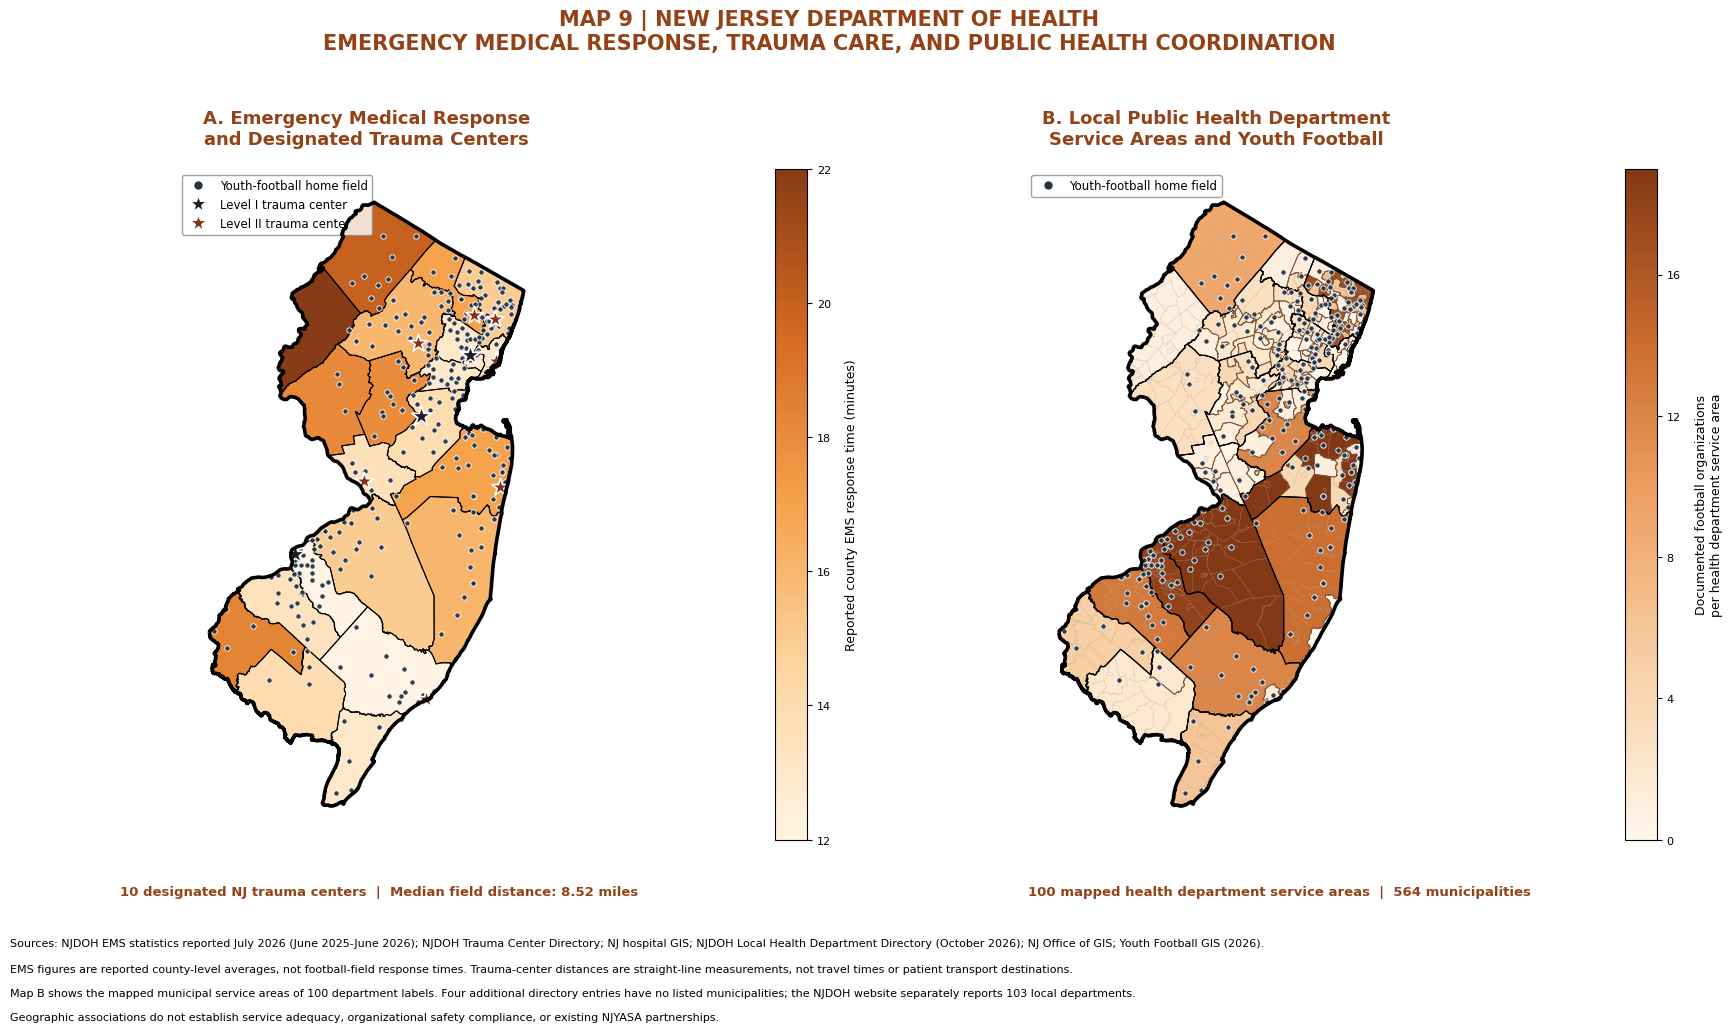

MAP 9 - FINAL TWO-MAP FIGURE
New Jersey counties: 21
Documented football home fields: 266
Designated trauma centers: 10
Municipalities: 564
Mapped public health areas: 100
Minimum reported county EMS time: 12.0 minutes
Maximum reported county EMS time: 22.0 minutes
Median straight-line trauma-center distance: 8.52 miles
Fields more than 20 straight-line miles from a listed NJ trauma center: 30

TOP HEALTH DEPARTMENT AREAS


,Health_Department,Municipalities_Served,Documented_Organizations
7,Burlington County Health Department,40,19
54,Monmouth County Board of Health,34,19
8,Camden County Department of Health & Human Ser...,36,18
3,Bergen County Department of Health Services,33,17
65,Ocean County Health Department,27,14
29,Gloucester County Department of Health & Senio...,24,13
1,Atlantic County Division of Public Health,22,12
53,Middlesex County Office of Health Services,21,12
80,Sussex County Department of Health and Human S...,24,9
51,Mid-Bergen Regional Health Commission,15,7



Map 9 figure generated successfully.
Both orange GIS panels exported.


In [75]:

# ==========================================================
# PS4 - MAP 9 - PART 11
# NJ DEPARTMENT OF HEALTH
# EMERGENCY CARE AND PUBLIC HEALTH COORDINATION
# TWO SIDE-BY-SIDE ORANGE GIS MAPS
# ==========================================================

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator
from IPython.display import display

# ----------------------------------------------------------
# 1. VALIDATE THE REQUIRED DATA
# ----------------------------------------------------------

required = [
    "map9_counties",
    "map9_trauma_gdf",
    "map9_field_distances",
    "map9_lhd_municipalities",
    "map9_football_lhd",
    "map9_lhd_counts"
]

for variable in required:
    if variable not in globals():
        raise RuntimeError(
            f"Missing {variable}. Run the earlier Map 9 cells."
        )

assert len(map9_counties) == 21
assert len(map9_trauma_gdf) == 10
assert len(map9_field_distances) == 266
assert len(map9_lhd_municipalities) == 564
assert len(map9_football_lhd) == 266

assert map9_counties[
    "EMS_Reported_Mean_Minutes"
].notna().all()

assert map9_lhd_municipalities[
    "Health_Department"
].notna().all()

assert map9_field_distances[
    "Distance_Miles"
].notna().all()

# ----------------------------------------------------------
# 2. PROJECT ALL GEOGRAPHY TO THE SAME COORDINATE SYSTEM
# ----------------------------------------------------------

MAP_CRS = "EPSG:26918"

m9_counties = map9_counties.to_crs(MAP_CRS).copy()
m9_trauma = map9_trauma_gdf.to_crs(MAP_CRS).copy()
m9_fields = map9_field_distances.to_crs(MAP_CRS).copy()
m9_municipalities = map9_lhd_municipalities.to_crs(
    MAP_CRS
).copy()
m9_football_lhd = map9_football_lhd.to_crs(
    MAP_CRS
).copy()

# Create the New Jersey statewide outline
m9_state_outline = m9_counties[
    ["geometry"]
].dissolve()

# ----------------------------------------------------------
# 3. PREPARE HEALTH DEPARTMENT SERVICE AREAS
# ----------------------------------------------------------

# The department count is associated with the full
# department jurisdiction, not with each municipality
# individually.

department_counts = (
    map9_lhd_counts[
        ["Health_Department", "Organizations"]
    ]
    .copy()
    .rename(
        columns={
            "Organizations": "Organizations_in_Jurisdiction"
        }
    )
)

m9_municipalities = m9_municipalities.merge(
    department_counts,
    on="Health_Department",
    how="left",
    validate="many_to_one"
)

# Some departments have zero documented football
# home-field locations.
m9_municipalities[
    "Organizations_in_Jurisdiction"
] = (
    m9_municipalities[
        "Organizations_in_Jurisdiction"
    ]
    .fillna(0)
    .astype(int)
)

# Dissolve municipality polygons by health department
# to create geographic service-area boundaries.

m9_health_areas = m9_municipalities.dissolve(
    by="Health_Department",
    as_index=False,
    aggfunc={
        "Organizations_in_Jurisdiction": "first"
    }
)

# ----------------------------------------------------------
# 4. VALIDATE SERVICE-AREA COUNTS
# ----------------------------------------------------------

mapped_department_count = (
    m9_municipalities[
        "Health_Department"
    ].nunique()
)

assert len(m9_health_areas) == mapped_department_count

assert (
    m9_health_areas[
        "Organizations_in_Jurisdiction"
    ].sum() == 266
)

assert len(m9_municipalities) == 564
assert len(m9_football_lhd) == 266

print("MAP 9 - SERVICE AREA VALIDATION")
print("--------------------------------")
print("Municipalities:", len(m9_municipalities))
print("Mapped health department areas:",
      len(m9_health_areas))
print("Football home fields:", len(m9_football_lhd))
print(
    "Organizations counted across service areas:",
    int(
        m9_health_areas[
            "Organizations_in_Jurisdiction"
        ].sum()
    )
)

# ----------------------------------------------------------
# 5. PREPARE MAP COLORS
# ----------------------------------------------------------

# MAP A: EMS response-time color palette
ems_cmap = LinearSegmentedColormap.from_list(
    "NJDOH_EMS_Orange",
    [
        "#FFF3E3",
        "#FDD6A2",
        "#F5A24C",
        "#D66A21",
        "#873B16"
    ]
)

# MAP B: Local public health jurisdiction palette
health_cmap = LinearSegmentedColormap.from_list(
    "NJDOH_Health_Orange",
    [
        "#FFF6EA",
        "#F7D1A8",
        "#EFA265",
        "#C96B2E",
        "#843916"
    ]
)

EMS_MIN = m9_counties[
    "EMS_Reported_Mean_Minutes"
].min()

EMS_MAX = m9_counties[
    "EMS_Reported_Mean_Minutes"
].max()

DEPARTMENT_MAX = m9_health_areas[
    "Organizations_in_Jurisdiction"
].max()

# ----------------------------------------------------------
# 6. CREATE THE TWO-MAP FIGURE
# ----------------------------------------------------------

fig = plt.figure(
    figsize=(18, 11),
    facecolor="white"
)

gs = fig.add_gridspec(
    1,
    4,
    width_ratios=[1, 0.045, 1, 0.045],
    left=0.045,
    right=0.96,
    top=0.82,
    bottom=0.21,
    wspace=0.14
)

ax_a = fig.add_subplot(gs[0, 0])
cax_a = fig.add_subplot(gs[0, 1])

ax_b = fig.add_subplot(gs[0, 2])
cax_b = fig.add_subplot(gs[0, 3])

# ==========================================================
# MAP A - EMS RESPONSE AND TRAUMA CENTER ACCESS
# ==========================================================

# ----------------------------------------------------------
# 7. EMS RESPONSE-TIME COUNTY CHOROPLETH
# ----------------------------------------------------------

m9_counties.plot(
    column="EMS_Reported_Mean_Minutes",
    ax=ax_a,
    cmap=ems_cmap,
    vmin=EMS_MIN,
    vmax=EMS_MAX,
    edgecolor="none",
    zorder=1
)

# County borders
m9_counties.boundary.plot(
    ax=ax_a,
    color="black",
    linewidth=0.75,
    zorder=2
)

# ----------------------------------------------------------
# 8. OVERLAY 266 FOOTBALL HOME FIELDS
# ----------------------------------------------------------

m9_fields.plot(
    ax=ax_a,
    marker="o",
    color="#263442",
    edgecolor="white",
    linewidth=0.65,
    markersize=15,
    alpha=0.95,
    zorder=4
)

# ----------------------------------------------------------
# 9. OVERLAY NJDOH TRAUMA CENTERS
# ----------------------------------------------------------

level_1 = m9_trauma[
    m9_trauma["Official_Level"] == "I"
]

level_2 = m9_trauma[
    m9_trauma["Official_Level"] == "II"
]

assert len(level_1) == 3
assert len(level_2) == 7

# Level II trauma centers
level_2.plot(
    ax=ax_a,
    marker="*",
    color="#8A2F19",
    edgecolor="white",
    linewidth=1.2,
    markersize=175,
    zorder=6
)

# Level I trauma centers
level_1.plot(
    ax=ax_a,
    marker="*",
    color="#211B29",
    edgecolor="white",
    linewidth=1.2,
    markersize=220,
    zorder=7
)

# State outline on top
m9_state_outline.boundary.plot(
    ax=ax_a,
    color="black",
    linewidth=2.6,
    zorder=8
)

ax_a.set_title(
    "A. Emergency Medical Response\n"
    "and Designated Trauma Centers",
    fontsize=13,
    fontweight="bold",
    color="#934318",
    pad=18
)

ax_a.set_axis_off()
ax_a.set_aspect("equal")

# ----------------------------------------------------------
# 10. MAP A LEGEND
# ----------------------------------------------------------

legend_a = [
    Line2D(
        [0], [0],
        marker="o",
        color="none",
        markerfacecolor="#263442",
        markeredgecolor="white",
        markeredgewidth=1,
        markersize=7,
        label="Youth-football home field"
    ),
    Line2D(
        [0], [0],
        marker="*",
        color="none",
        markerfacecolor="#211B29",
        markeredgecolor="white",
        markeredgewidth=0.8,
        markersize=12,
        label="Level I trauma center"
    ),
    Line2D(
        [0], [0],
        marker="*",
        color="none",
        markerfacecolor="#8A2F19",
        markeredgecolor="white",
        markeredgewidth=0.8,
        markersize=12,
        label="Level II trauma center"
    )
]

ax_a.legend(
    handles=legend_a,
    loc="upper left",
    fontsize=8.5,
    frameon=True,
    facecolor="white",
    edgecolor="#888888"
)

# EMS colorbar
ems_scale = ScalarMappable(
    norm=Normalize(
        vmin=EMS_MIN,
        vmax=EMS_MAX
    ),
    cmap=ems_cmap
)

ems_scale.set_array([])

cb_a = fig.colorbar(
    ems_scale,
    cax=cax_a
)

cb_a.set_label(
    "Reported county EMS response time (minutes)",
    fontsize=9,
    labelpad=10
)

cb_a.ax.tick_params(labelsize=8)

# ==========================================================
# MAP B - LOCAL PUBLIC HEALTH COORDINATION
# ==========================================================

# ----------------------------------------------------------
# 11. SHADE VERIFIED HEALTH DEPARTMENT SERVICE AREAS
# ----------------------------------------------------------

m9_health_areas.plot(
    column="Organizations_in_Jurisdiction",
    ax=ax_b,
    cmap=health_cmap,
    vmin=0,
    vmax=DEPARTMENT_MAX,
    edgecolor="none",
    zorder=1
)

# Outline individual municipal polygons lightly
m9_municipalities.boundary.plot(
    ax=ax_b,
    color="#BBA691",
    linewidth=0.18,
    alpha=0.6,
    zorder=2
)

# Draw health department jurisdiction boundaries
m9_health_areas.boundary.plot(
    ax=ax_b,
    color="#77513A",
    linewidth=0.6,
    zorder=3
)

# Draw New Jersey county boundaries
m9_counties.boundary.plot(
    ax=ax_b,
    color="black",
    linewidth=0.8,
    zorder=4
)

# ----------------------------------------------------------
# 12. ADD 266 DOCUMENTED FOOTBALL LOCATIONS
# ----------------------------------------------------------

m9_football_lhd.plot(
    ax=ax_b,
    marker="o",
    color="#263442",
    edgecolor="white",
    linewidth=0.65,
    markersize=15,
    alpha=0.95,
    zorder=5
)

# Thick New Jersey outline
m9_state_outline.boundary.plot(
    ax=ax_b,
    color="black",
    linewidth=2.6,
    zorder=6
)

ax_b.set_title(
    "B. Local Public Health Department\n"
    "Service Areas and Youth Football",
    fontsize=13,
    fontweight="bold",
    color="#934318",
    pad=18
)

ax_b.set_axis_off()
ax_b.set_aspect("equal")

# ----------------------------------------------------------
# 13. MAP B LEGEND
# ----------------------------------------------------------

ax_b.legend(
    handles=[
        Line2D(
            [0], [0],
            marker="o",
            color="none",
            markerfacecolor="#263442",
            markeredgecolor="white",
            markeredgewidth=1,
            markersize=7,
            label="Youth-football home field"
        )
    ],
    loc="upper left",
    fontsize=8.5,
    frameon=True,
    facecolor="white",
    edgecolor="#888888"
)

# Colorbar for number of football organizations
health_scale = ScalarMappable(
    norm=Normalize(
        vmin=0,
        vmax=DEPARTMENT_MAX
    ),
    cmap=health_cmap
)

health_scale.set_array([])

cb_b = fig.colorbar(
    health_scale,
    cax=cax_b
)

cb_b.set_label(
    "Documented football organizations\n"
    "per health department service area",
    fontsize=9,
    labelpad=10
)

cb_b.locator = MaxNLocator(
    nbins=6,
    integer=True
)
cb_b.update_ticks()

cb_b.ax.tick_params(labelsize=8)

# ----------------------------------------------------------
# 14. ALIGN BOTH MAPS TO THE SAME NJ EXTENT
# ----------------------------------------------------------

xmin, ymin, xmax, ymax = m9_counties.total_bounds

for axis in [ax_a, ax_b]:
    axis.set_xlim(xmin - 15000, xmax + 15000)
    axis.set_ylim(ymin - 15000, ymax + 15000)
    axis.set_aspect("equal")

# ----------------------------------------------------------
# 15. ADD MAIN TITLE AND SUMMARY STATISTICS
# ----------------------------------------------------------

fig.suptitle(
    "MAP 9 | NEW JERSEY DEPARTMENT OF HEALTH\n"
    "EMERGENCY MEDICAL RESPONSE, TRAUMA CARE, "
    "AND PUBLIC HEALTH COORDINATION",
    fontsize=15,
    fontweight="bold",
    color="#944116",
    y=0.965
)

median_distance = (
    m9_fields["Distance_Miles"].median()
)

more_than_20 = int(
    (m9_fields["Distance_Miles"] > 20).sum()
)

fig.text(
    0.25,
    0.16,
    "10 designated NJ trauma centers  |  "
    f"Median field distance: {median_distance:.2f} miles",
    ha="center",
    fontsize=9.5,
    fontweight="bold",
    color="#934318"
)

fig.text(
    0.75,
    0.16,
    f"{mapped_department_count} mapped health department "
    "service areas  |  564 municipalities",
    ha="center",
    fontsize=9.5,
    fontweight="bold",
    color="#934318"
)

# ----------------------------------------------------------
# 16. SOURCE AND LIMITATION NOTES
# ----------------------------------------------------------

fig.text(
    0.045,
    0.113,
    "Sources: NJDOH EMS statistics reported July 2026 "
    "(June 2025-June 2026); NJDOH Trauma Center Directory; "
    "NJ hospital GIS; NJDOH Local Health Department Directory "
    "(October 2026); NJ Office of GIS; Youth Football GIS (2026).",
    fontsize=8
)

fig.text(
    0.045,
    0.090,
    "EMS figures are reported county-level averages, "
    "not football-field response times. "
    "Trauma-center distances are straight-line measurements, "
    "not travel times or patient transport destinations.",
    fontsize=8
)

fig.text(
    0.045,
    0.068,
    "Map B shows the mapped municipal service areas of "
    "100 department labels. Four additional directory "
    "entries have no listed municipalities; the NJDOH "
    "website separately reports 103 local departments.",
    fontsize=8
)

fig.text(
    0.045,
    0.046,
    "Geographic associations do not establish service "
    "adequacy, organizational safety compliance, or "
    "existing NJYASA partnerships.",
    fontsize=8
)

# ----------------------------------------------------------
# 17. EXPORT HIGH-RESOLUTION MAPS
# ----------------------------------------------------------

plt.savefig(
    "PS4_Map9_NJDOH_Emergency_Care_and_Coordination.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.savefig(
    "PS4_Map9_NJDOH_Emergency_Care_and_Coordination.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# ----------------------------------------------------------
# 18. EXPORT SERVICE-AREA STATISTICS
# ----------------------------------------------------------

map9_service_area_summary = (
    m9_municipalities
    .groupby("Health_Department")
    .agg(
        Municipalities_Served=("MUN_CODE", "nunique"),
        Documented_Organizations=(
            "Organizations_in_Jurisdiction",
            "first"
        )
    )
    .reset_index()
    .sort_values(
        "Documented_Organizations",
        ascending=False
    )
)

assert len(map9_service_area_summary) == mapped_department_count

assert (
    map9_service_area_summary[
        "Documented_Organizations"
    ].sum() == 266
)

map9_service_area_summary.to_csv(
    "PS4_Map9_NJDOH_Service_Area_Summary.csv",
    index=False
)

# ----------------------------------------------------------
# 19. FINAL VALIDATION
# ----------------------------------------------------------

print("============================================")
print("MAP 9 - FINAL TWO-MAP FIGURE")
print("============================================")

print("New Jersey counties:", len(m9_counties))
print("Documented football home fields:", len(m9_fields))
print("Designated trauma centers:", len(m9_trauma))
print("Municipalities:", len(m9_municipalities))
print("Mapped public health areas:",
      mapped_department_count)

print(
    "Minimum reported county EMS time:",
    round(EMS_MIN, 2),
    "minutes"
)

print(
    "Maximum reported county EMS time:",
    round(EMS_MAX, 2),
    "minutes"
)

print(
    "Median straight-line trauma-center distance:",
    round(median_distance, 2),
    "miles"
)

print(
    "Fields more than 20 straight-line miles "
    "from a listed NJ trauma center:",
    more_than_20
)

print("\nTOP HEALTH DEPARTMENT AREAS")
display(map9_service_area_summary.head(10))

print("\nMap 9 figure generated successfully.")
print("Both orange GIS panels exported.")


### **Map 9 Interpretation — Emergency Medical Response, Trauma Care, and Local Public Health Coordination**

Map 9 examines the geographic relationship between emergency medical services, designated trauma centers, local public-health jurisdictions, and 266 documented community youth-football organizations across New Jersey's 21 counties.

The analysis consists of two complementary GIS maps designed to evaluate emergency-care geography and potential opportunities for public-health coordination.

### Map A — Emergency Medical Response and Designated Trauma Centers

Map A displays reported county-level emergency medical services (EMS) response-time statistics alongside the locations of 10 New Jersey Department of Health-designated Level I and Level II trauma centers and 266 documented youth-football home fields.

The reported county EMS response-time statistics range from approximately 12 to 22 minutes. These figures represent county-level averages reported for June 2025 through June 2026 and should not be interpreted as expected ambulance arrival times at individual football fields.

The geographic analysis calculates the straight-line distance between each documented football home field and its nearest designated New Jersey trauma center.

Across the 266 football locations, the median straight-line distance is 8.52 miles, and the mean distance is 10.39 miles. Of the documented locations, 110 are more than 10 straight-line miles from the nearest listed New Jersey trauma center, including 30 that are more than 20 miles away.

The counties with the greatest median distances are Cumberland (32.23 miles), Salem (27.02 miles), Cape May (25.67 miles), Hunterdon (24.00 miles), and Sussex (23.84 miles).

These findings demonstrate geographic variation in proximity to designated trauma-care facilities. However, the distances do not measure actual travel times, EMS coverage, availability of other emergency departments, or the clinical appropriateness of particular hospitals.

### Map B — Local Public Health Departments and County-Level Coordination

Map B examines the distribution of community youth-football organizations within New Jersey's existing local public-health service jurisdictions.

The analysis uses the October 2026 NJDOH Local Health Department Directory, official municipal GIS boundaries, and the documented football home-field inventory.

A total of 564 municipalities were assigned to 100 mapped local health-department service areas. All 266 documented football locations were successfully associated with municipal and health-department jurisdictions.

The Burlington County Health Department and Monmouth County Board of Health each have 19 documented football organizations within their mapped service areas. Camden County's department has 18, Bergen County's department has 17, and Ocean County's department has 14.

These findings identify existing public-health agencies whose geographic jurisdictions overlap with community youth-sports infrastructure.

The mapping does not establish that these agencies currently oversee the youth-football organizations, provide services to them, or have entered into partnerships with NJYASA.

### Public Administration and NJYASA Implications

Together, Maps A and B demonstrate the potential value of examining emergency-care geography and established public-health institutions when developing a voluntary statewide youth-sports coordination framework.

NJYASA's proposed 21 County Conferences and three Regional Councils could potentially serve as communication structures connecting participating youth-sports organizations with qualified emergency medical professionals, local health departments, hospitals, and other public-health partners.

Potential areas for future collaboration include emergency-action planning, CPR/AED education, appropriate coach safety training, injury-response awareness, and pediatric emergency preparedness.

The geographic findings may also assist NJYASA in identifying where additional discussions with qualified medical and public-health personnel would be useful.

For example, the Burlington County demonstration could examine opportunities for communication between its 19 documented football organizations, the Burlington County Health Department, and relevant emergency medical and healthcare providers.

This research does not establish that NJYASA can improve EMS response times or that geographic proximity determines organizational safety. Rather, it identifies existing institutions and geographic conditions that may inform future planning and coordination.

### Research Limitations

The county-level EMS statistics represent reported historical response-time measures across general emergency incidents, not youth-sports-specific emergencies or response times at individual football fields.

The trauma-center analysis includes 10 designated New Jersey Level I and Level II facilities. It excludes other emergency departments and potentially relevant out-of-state facilities.

Straight-line distance does not measure road-network travel time, traffic conditions, ambulance availability, dispatch procedures, patient transport destinations, or pediatric treatment capabilities.

The football inventory represents documented 2026 organizations and their mapped home-field locations. Home-field location does not necessarily indicate where participating athletes reside or receive medical services.

The NJDOH directory contained 100 mapped department labels with identifiable municipal assignments and four additional directory entries without listed municipalities. NJDOH separately reports 103 local health departments statewide. These figures represent different classifications and have not been forced into a single total.

The 2026 health-department directory, 2026 football inventory, historical hospital GIS coordinates, and EMS reporting period are not temporally identical.

Further research would be necessary to assess actual emergency medical coverage, organizational preparedness, AED availability, coach training, pediatric emergency readiness, and opportunities for institutional collaboration.

# Limitations

This project is based on documented youth football organizations and their mapped home-field locations. The dataset does not measure the number of athletes, number of teams, registration levels, financial resources, or the full geographic area served by each organization.

League affiliation represents the best documented information available during the research period. One organization's exact league affiliation remains pending verification.

The proposed County Conference and North, Central, and South regional structure is a planning model developed for this project. These boundaries do not represent an existing NJYASA administrative system.

Organization counts should also not be interpreted as measures of participation or need. A county with fewer documented organizations may still serve a large number of athletes, while a county with many organizations may divide participation among several smaller programs.

The higher-education analysis identifies existing institutions as possible resources and opportunity hubs. Their presence does not indicate that any college or university has agreed to participate in or partner with NJYASA.

# Next Steps

PS3 establishes the geographic and organizational foundation of the proposed NJYASA model.

The next stage of the project will examine how this structure could connect with existing New Jersey public institutions and programs.

PS4 will specifically examine the potential relationship between NJYASA and:

- the **New Jersey Department of State**
- the **New Jersey Department of Children and Families**
- the **New Jersey Department of Community Affairs**

The purpose will be to determine whether an organized statewide youth-sports network could help connect state resources with local organizations while also creating a structured pathway for local needs and information to move upward through County Conferences, Regional Councils, and NJYASA professional staff.

Later analysis can also examine additional measures such as population, youth population, school districts, recreation infrastructure, participation, facilities, and other indicators of local need and capacity.